In [3]:
!pip install scipy statsmodels matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import seaborn as sns
from scipy import stats
from scipy.stats import norm, shapiro, kruskal
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
print("✅ Libraries ready!")

✅ Libraries ready!


In [4]:
# CELL 3 — Load flight_data_2024.csv & See Columns
import pandas as pd

df = pd.read_csv('flight_data_2024.csv')

print(f"Shape: {df.shape}")
print(f"\nAll Columns:\n{df.columns.tolist()}")
print(f"\nFirst 3 rows:")
df.head(3)

Shape: (7079081, 35)

All Columns:
['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']

First 3 rows:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0


In [5]:
# CELL 4 — Quick Peek
print("=== DATA TYPES ===")
print(df.dtypes)

print("\n=== SAMPLE VALUES (first row) ===")
print(df.iloc[0])

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

=== DATA TYPES ===
year                     int64
month                    int64
day_of_month             int64
day_of_week              int64
fl_date                    str
op_unique_carrier          str
op_carrier_fl_num      float64
origin                     str
origin_city_name           str
origin_state_nm            str
dest                       str
dest_city_name             str
dest_state_nm              str
crs_dep_time             int64
dep_time               float64
dep_delay              float64
taxi_out               float64
wheels_off             float64
wheels_on              float64
taxi_in                float64
crs_arr_time             int64
arr_time               float64
arr_delay              float64
cancelled                int64
cancellation_code          str
diverted                 int64
crs_elapsed_time       float64
actual_elapsed_time    float64
air_time               float64
distance               float64
carrier_delay            int64
weather_delay       

In [6]:
import numpy as np
from scipy.stats import norm

print(f"Shape BEFORE cleaning: {df.shape}")

# Drop cancellation_code column
df.drop(columns=['cancellation_code'], inplace=True)

# Drop all rows with any missing values
df.dropna(inplace=True)

print(f"Shape AFTER cleaning : {df.shape}")
print(f"Rows removed         : {7079081 - len(df):,}")

# CTQ threshold
THRESHOLD = 15
df['is_delayed'] = (df['dep_delay'] > THRESHOLD).astype(int)

print(f"\nTotal flights        : {len(df):,}")
print(f"Delayed > 15 min     : {df['is_delayed'].sum():,}")
print(f"On-time              : {(df['is_delayed']==0).sum():,}")
print(f"Defect Rate          : {df['is_delayed'].mean()*100:.2f}%")
print(f"\nUnique Airlines      : {df['op_unique_carrier'].nunique()}")
print(df['op_unique_carrier'].value_counts())

Shape BEFORE cleaning: (7079081, 35)
Shape AFTER cleaning : (6965266, 34)
Rows removed         : 113,815

Total flights        : 6,965,266
Delayed > 15 min     : 1,388,886
On-time              : 5,576,380
Defect Rate          : 19.94%

Unique Airlines      : 15
op_unique_carrier
WN    1404597
DL     997846
AA     966116
UA     745818
OO     733886
YX     295306
MQ     275317
NK     255633
AS     240323
B6     235683
OH     223673
F9     203481
9E     195072
G4     114882
HA      77633
Name: count, dtype: int64


In [7]:
print("=== DATASET OVERVIEW ===")
print(f"Total Flights     : {len(df):,}")
print(f"Date Range        : {df['fl_date'].min()} to {df['fl_date'].max()}")
print(f"Total Airlines    : {df['op_unique_carrier'].nunique()}")
print(f"Total Origins     : {df['origin'].nunique()} airports")
print(f"Total Destinations: {df['dest'].nunique()} airports")
print(f"Total Routes      : {df.groupby(['origin','dest']).ngroups:,}")
print(f"\n=== DEP_DELAY STATS ===")
print(df['dep_delay'].describe(percentiles=[.25,.5,.75,.90,.95,.99]).round(2))

=== DATASET OVERVIEW ===
Total Flights     : 6,965,266
Date Range        : 2024-01-01 to 2024-12-31
Total Airlines    : 15
Total Origins     : 348 airports
Total Destinations: 348 airports
Total Routes      : 6,792

=== DEP_DELAY STATS ===
count    6965266.00
mean          12.59
std           55.83
min          -96.00
25%           -6.00
50%           -2.00
75%            9.00
90%           43.00
95%           83.00
99%          215.00
max         3777.00
Name: dep_delay, dtype: float64


Flight Count by Airline

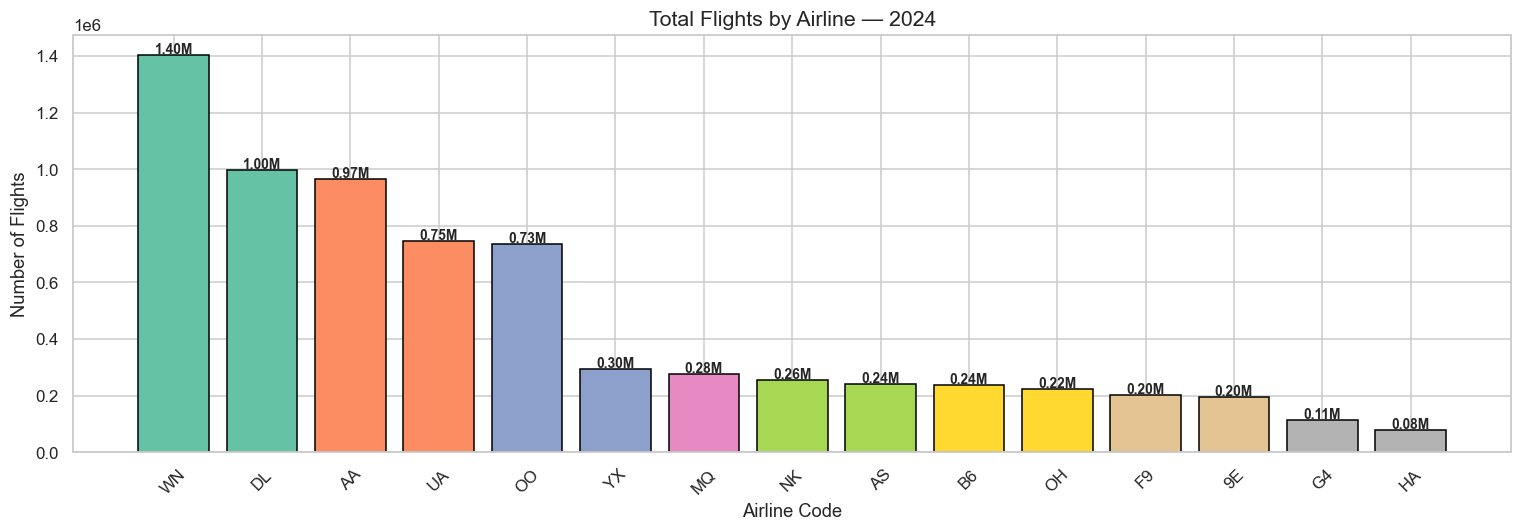

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
airline_counts = df['op_unique_carrier'].value_counts()
colors = plt.cm.Set2(np.linspace(0, 1, len(airline_counts)))
bars = ax.bar(airline_counts.index, airline_counts.values, color=colors, edgecolor='black')
for bar, val in zip(bars, airline_counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5000,
            f'{val/1e6:.2f}M', ha='center', fontsize=9, fontweight='bold')
ax.set_title('Total Flights by Airline — 2024', fontsize=14)
ax.set_xlabel('Airline Code')
ax.set_ylabel('Number of Flights')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('flights_by_airline.png', bbox_inches='tight')
plt.show()

Delay Distribution Deep Dive

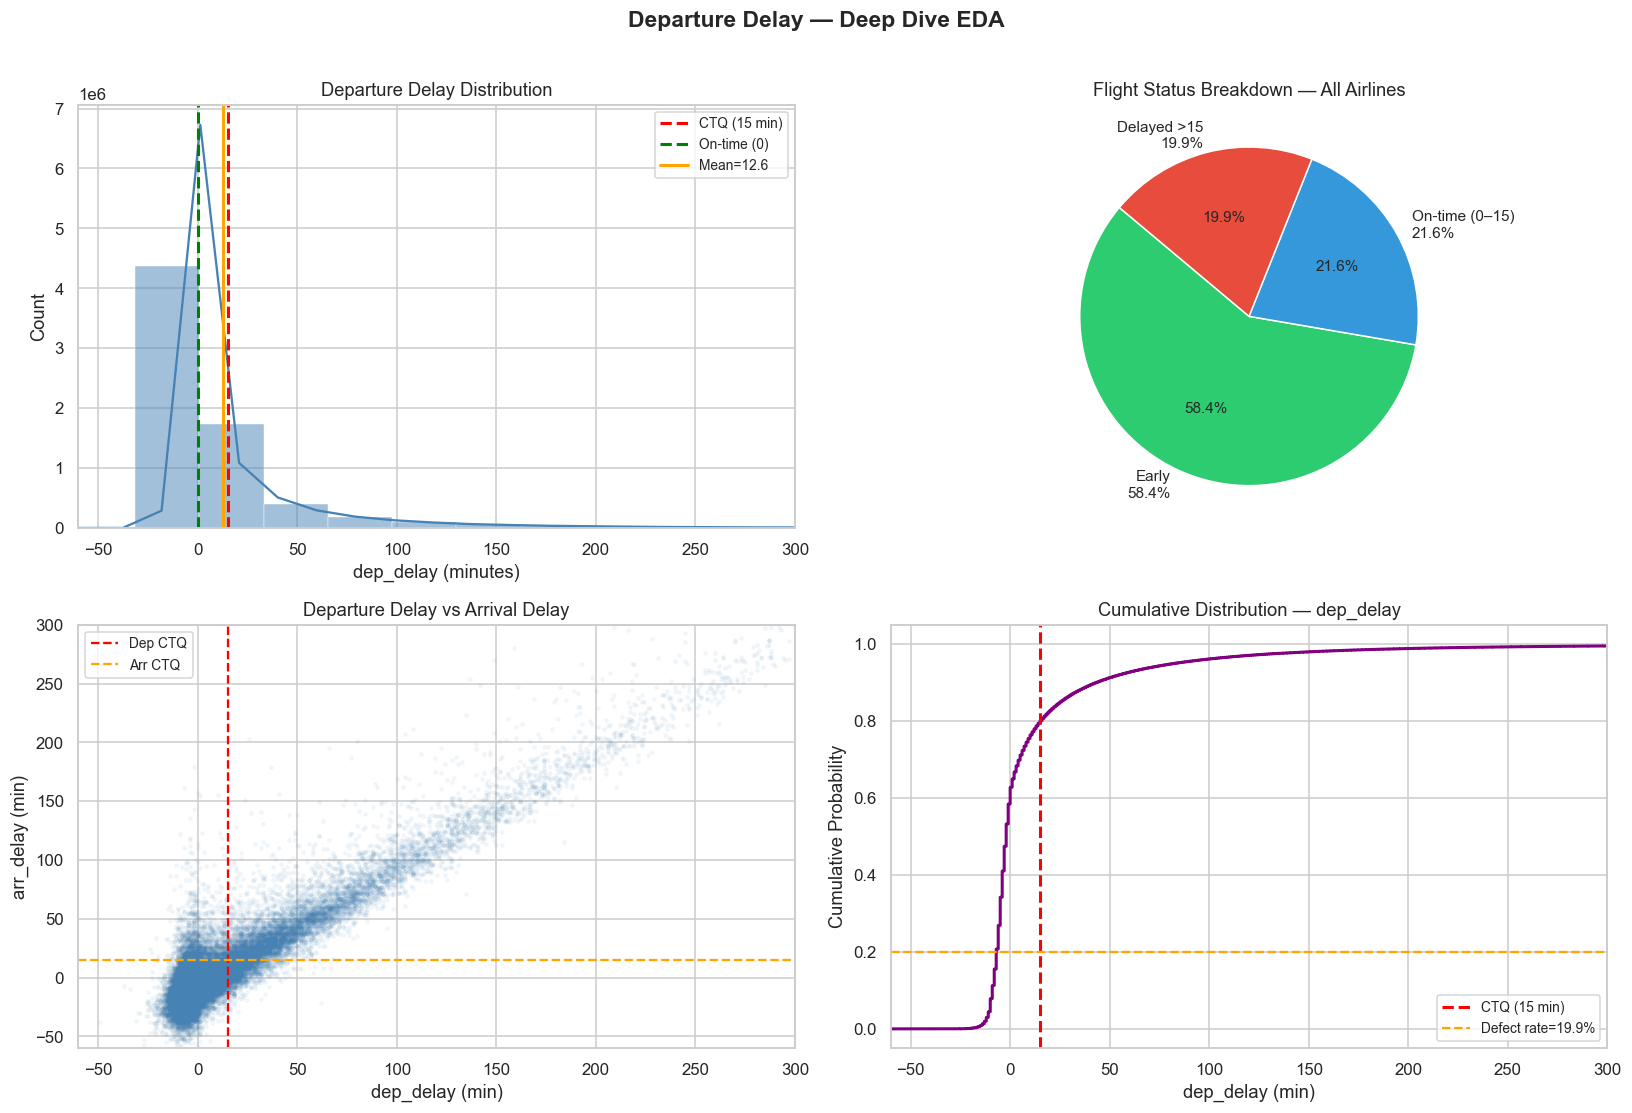

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Full histogram
sns.histplot(df['dep_delay'], bins=120, kde=True,
             ax=axes[0,0], color='steelblue')
axes[0,0].axvline(15,  color='red',    ls='--', lw=2, label='CTQ (15 min)')
axes[0,0].axvline(0,   color='green',  ls='--', lw=2, label='On-time (0)')
axes[0,0].axvline(df['dep_delay'].mean(), color='orange', ls='-', lw=2,
                  label=f"Mean={df['dep_delay'].mean():.1f}")
axes[0,0].set_xlim(-60, 300)
axes[0,0].set_title('Departure Delay Distribution')
axes[0,0].set_xlabel('dep_delay (minutes)')
axes[0,0].legend(fontsize=9)

# 2. Early vs On-time vs Delayed pie
early   = (df['dep_delay'] < 0).sum()
ontime  = ((df['dep_delay'] >= 0) & (df['dep_delay'] <= 15)).sum()
delayed = (df['dep_delay'] > 15).sum()
axes[0,1].pie([early, ontime, delayed],
              labels=[f'Early\n{early/len(df)*100:.1f}%',
                      f'On-time (0–15)\n{ontime/len(df)*100:.1f}%',
                      f'Delayed >15\n{delayed/len(df)*100:.1f}%'],
              colors=['#2ecc71','#3498db','#e74c3c'],
              autopct='%1.1f%%', startangle=140, textprops={'fontsize':10})
axes[0,1].set_title('Flight Status Breakdown — All Airlines')

# 3. Arrival vs Departure delay scatter (sample)
sample = df.sample(min(50000, len(df)), random_state=42)
axes[1,0].scatter(sample['dep_delay'], sample['arr_delay'],
                  alpha=0.05, color='steelblue', s=5)
axes[1,0].axvline(15, color='red',   ls='--', lw=1.5, label='Dep CTQ')
axes[1,0].axhline(15, color='orange',ls='--', lw=1.5, label='Arr CTQ')
axes[1,0].set_xlim(-60, 300)
axes[1,0].set_ylim(-60, 300)
axes[1,0].set_title('Departure Delay vs Arrival Delay')
axes[1,0].set_xlabel('dep_delay (min)')
axes[1,0].set_ylabel('arr_delay (min)')
axes[1,0].legend(fontsize=9)

# 4. CDF plot
sorted_delays = np.sort(df['dep_delay'].values)
cdf = np.arange(1, len(sorted_delays)+1) / len(sorted_delays)
axes[1,1].plot(sorted_delays, cdf, color='purple', lw=2)
axes[1,1].axvline(15, color='red', ls='--', lw=2, label='CTQ (15 min)')
axes[1,1].axhline(df['is_delayed'].mean(), color='orange', ls='--',
                   label=f"Defect rate={df['is_delayed'].mean()*100:.1f}%")
axes[1,1].set_xlim(-60, 300)
axes[1,1].set_title('Cumulative Distribution — dep_delay')
axes[1,1].set_xlabel('dep_delay (min)')
axes[1,1].set_ylabel('Cumulative Probability')
axes[1,1].legend(fontsize=9)

plt.suptitle('Departure Delay — Deep Dive EDA', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('delay_deep_dive.png', bbox_inches='tight')
plt.show()

Delay by Day of Week & Month (EDA)

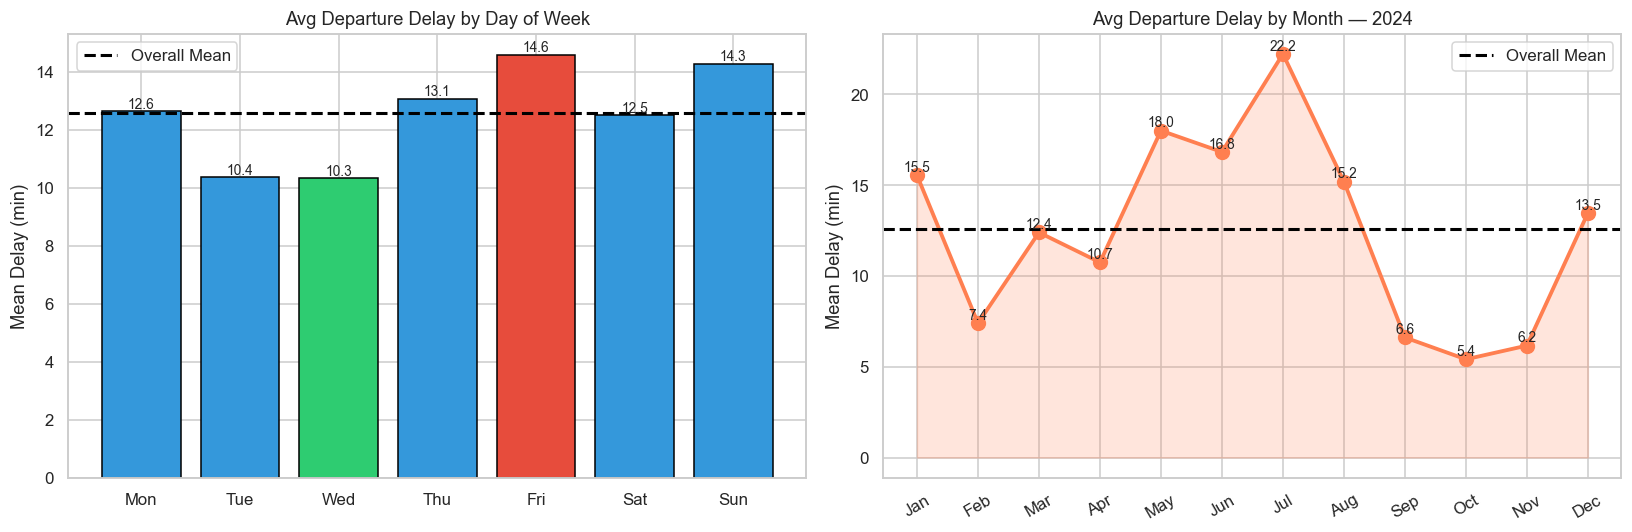

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
month_labels = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']
day_map   = {1:'Mon',2:'Tue',3:'Wed',4:'Thu',5:'Fri',6:'Sat',7:'Sun'}
day_order = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df['day_name'] = df['day_of_week'].map(day_map)

# Mean delay by day
day_mean = df.groupby('day_name')['dep_delay'].mean().reindex(day_order)
bars = axes[0].bar(day_order, day_mean.values,
                   color=['#e74c3c' if v == day_mean.max()
                          else '#2ecc71' if v == day_mean.min()
                          else '#3498db' for v in day_mean.values],
                   edgecolor='black')
axes[0].axhline(df['dep_delay'].mean(), color='black', ls='--', lw=2, label='Overall Mean')
for bar, val in zip(bars, day_mean.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
                 f'{val:.1f}', ha='center', fontsize=9)
axes[0].set_title('Avg Departure Delay by Day of Week')
axes[0].set_ylabel('Mean Delay (min)')
axes[0].legend()

# Mean delay by month
month_mean = df.groupby('month')['dep_delay'].mean()
axes[1].plot(month_labels[:len(month_mean)], month_mean.values,
             marker='o', color='coral', lw=2.5, markersize=9)
axes[1].fill_between(range(len(month_mean)), month_mean.values,
                     alpha=0.2, color='coral')
axes[1].set_xticks(range(len(month_mean)))
axes[1].set_xticklabels(month_labels[:len(month_mean)], rotation=30)
axes[1].axhline(df['dep_delay'].mean(), color='black', ls='--', lw=2, label='Overall Mean')
for i, v in enumerate(month_mean.values):
    axes[1].text(i, v+0.2, f'{v:.1f}', ha='center', fontsize=9)
axes[1].set_title('Avg Departure Delay by Month — 2024')
axes[1].set_ylabel('Mean Delay (min)')
axes[1].legend()

plt.tight_layout()
plt.savefig('delay_day_month_eda.png', bbox_inches='tight')
plt.show()

Top 15 Busiest & Most Delayed Airports

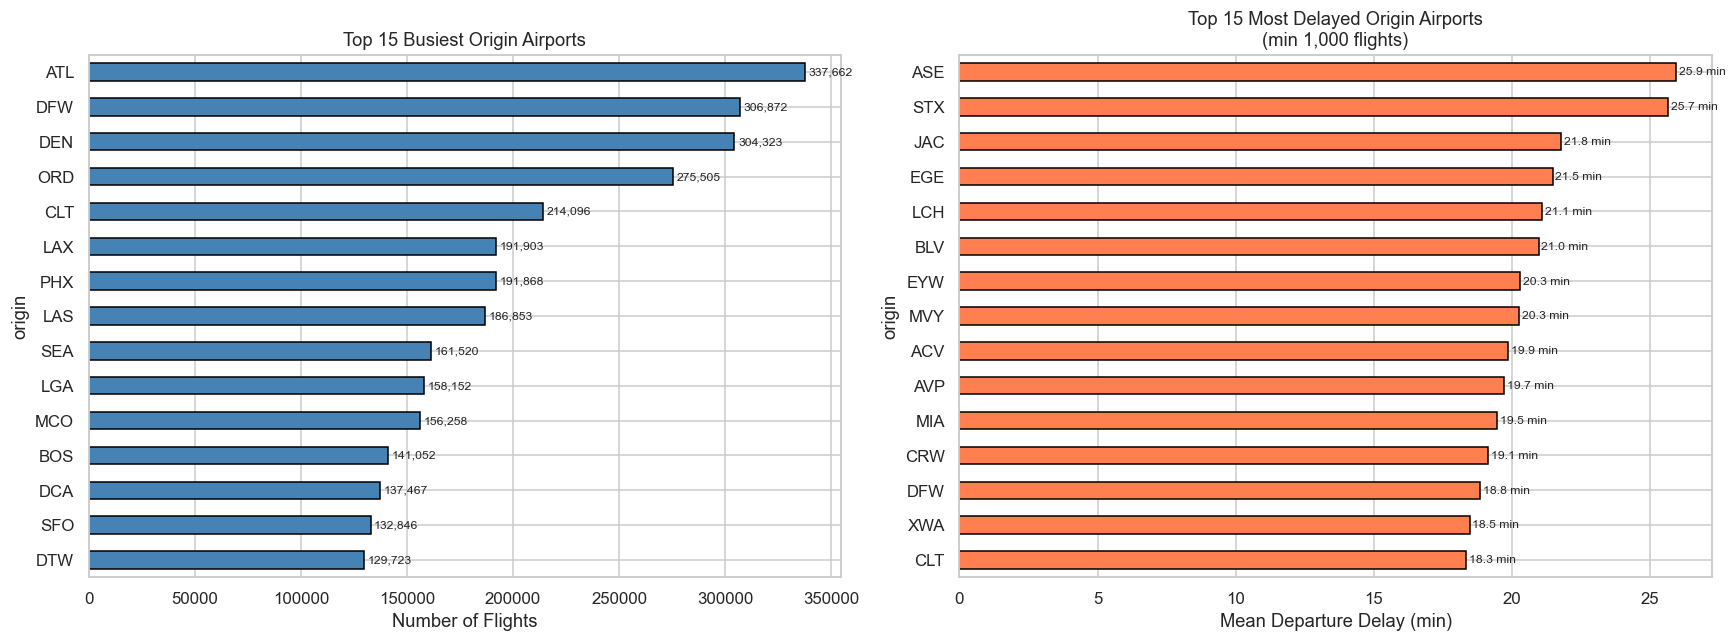

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 15 busiest origins
top_origins = df['origin'].value_counts().head(15)
top_origins.plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Top 15 Busiest Origin Airports')
axes[0].set_xlabel('Number of Flights')
axes[0].invert_yaxis()
for i, v in enumerate(top_origins.values):
    axes[0].text(v + top_origins.max()*0.005, i, f'{v:,}', va='center', fontsize=8)

# Top 15 most delayed airports (min 1000 flights)
airport_delay = (df.groupby('origin')
                   .agg(mean_delay=('dep_delay','mean'),
                        flights=('dep_delay','count'))
                   .query('flights >= 1000')
                   .sort_values('mean_delay', ascending=False)
                   .head(15))
airport_delay['mean_delay'].plot(kind='barh', ax=axes[1],
                                  color='coral', edgecolor='black')
axes[1].set_title('Top 15 Most Delayed Origin Airports\n(min 1,000 flights)')
axes[1].set_xlabel('Mean Departure Delay (min)')
axes[1].invert_yaxis()
for i, v in enumerate(airport_delay['mean_delay']):
    axes[1].text(v + 0.1, i, f'{v:.1f} min', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('airports_eda.png', bbox_inches='tight')
plt.show()

Delay Cause Breakdown (All 5 Cause Columns)

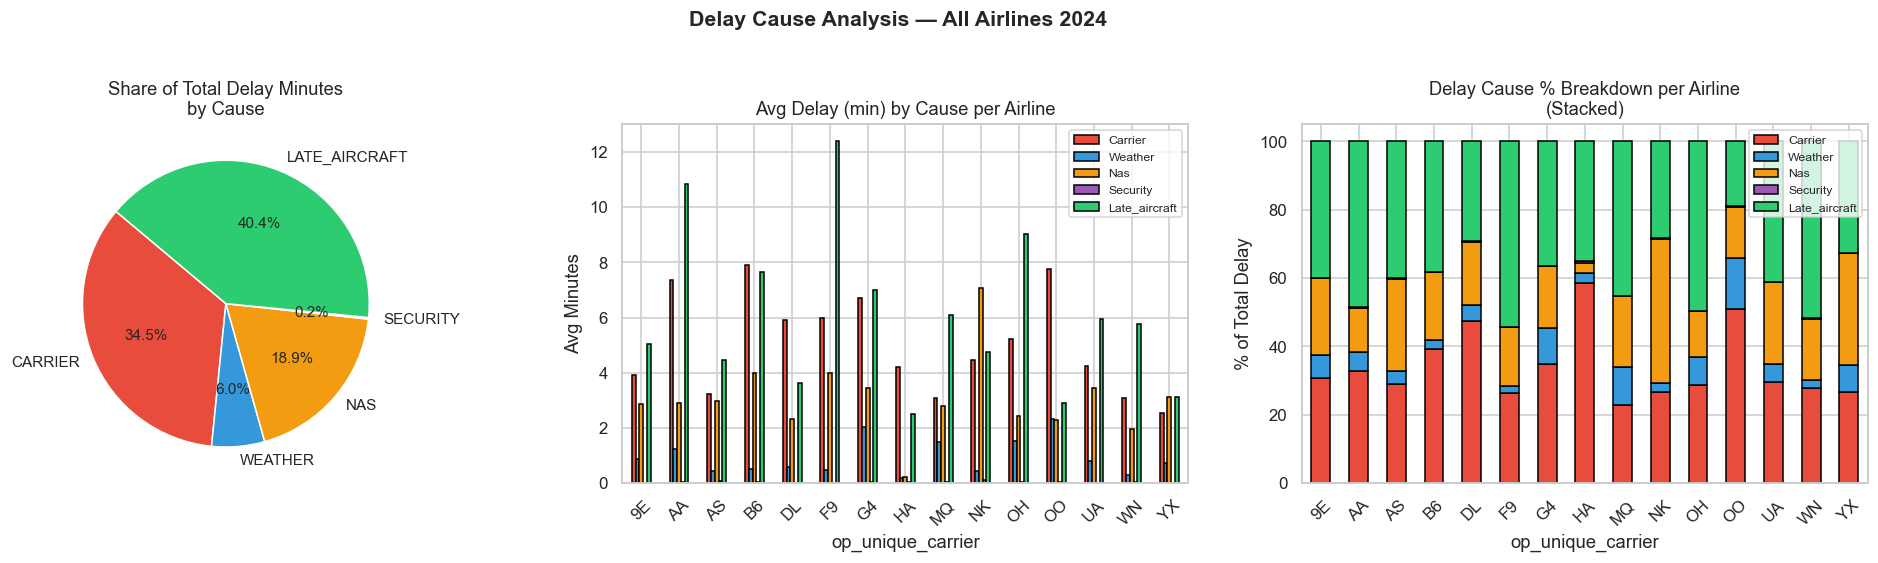

In [12]:
delay_causes = ['carrier_delay','weather_delay','nas_delay',
                'security_delay','late_aircraft_delay']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors_list = ['#e74c3c','#3498db','#f39c12','#9b59b6','#2ecc71']

# Total minutes pie
totals = df[delay_causes].sum()
axes[0].pie(totals, labels=[c.replace('_delay','').upper() for c in delay_causes],
            autopct='%1.1f%%', colors=colors_list, startangle=140,
            textprops={'fontsize': 10})
axes[0].set_title('Share of Total Delay Minutes\nby Cause')

# Mean delay per cause per airline
cause_airline = df.groupby('op_unique_carrier')[delay_causes].mean()
cause_airline.columns = [c.replace('_delay','').capitalize() for c in delay_causes]
cause_airline.plot(kind='bar', ax=axes[1], color=colors_list, edgecolor='black')
axes[1].set_title('Avg Delay (min) by Cause per Airline')
axes[1].set_ylabel('Avg Minutes')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8)

# Stacked bar — proportion by airline
cause_pct = cause_airline.div(cause_airline.sum(axis=1), axis=0) * 100
cause_pct.plot(kind='bar', stacked=True, ax=axes[2],
               color=colors_list, edgecolor='black')
axes[2].set_title('Delay Cause % Breakdown per Airline\n(Stacked)')
axes[2].set_ylabel('% of Total Delay')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend(fontsize=8, loc='upper right')

plt.suptitle('Delay Cause Analysis — All Airlines 2024',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('delay_causes_eda.png', bbox_inches='tight')
plt.show()

Distance vs Delay & Correlation Heatmap

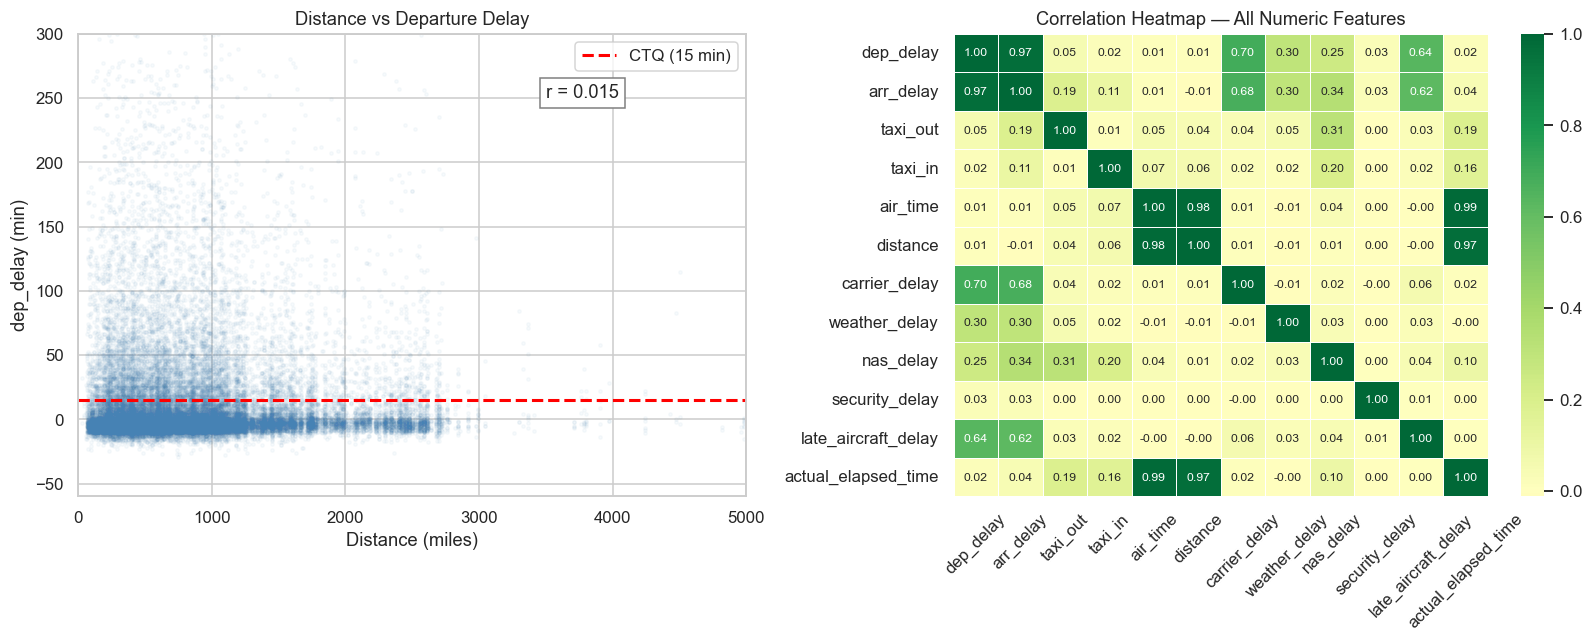

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Distance vs delay scatter
sample = df.sample(min(40000, len(df)), random_state=1)
axes[0].scatter(sample['distance'], sample['dep_delay'],
                alpha=0.04, color='steelblue', s=5)
axes[0].axhline(15, color='red', ls='--', lw=2, label='CTQ (15 min)')
axes[0].set_xlim(0, 5000)
axes[0].set_ylim(-60, 300)
axes[0].set_title('Distance vs Departure Delay')
axes[0].set_xlabel('Distance (miles)')
axes[0].set_ylabel('dep_delay (min)')
axes[0].legend()

corr_val = df[['distance','dep_delay']].corr().iloc[0,1]
axes[0].text(3500, 250, f'r = {corr_val:.3f}', fontsize=12,
             bbox=dict(facecolor='white', edgecolor='gray'))

# Correlation heatmap — numeric cols
num_cols = ['dep_delay','arr_delay','taxi_out','taxi_in','air_time',
            'distance','carrier_delay','weather_delay','nas_delay',
            'security_delay','late_aircraft_delay','actual_elapsed_time']
num_cols = [c for c in num_cols if c in df.columns]
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, ax=axes[1],
            annot_kws={'size': 8})
axes[1].set_title('Correlation Heatmap — All Numeric Features')
axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('correlation_eda.png', bbox_inches='tight')
plt.show()

D (DEFINE): SIPOC Diagram

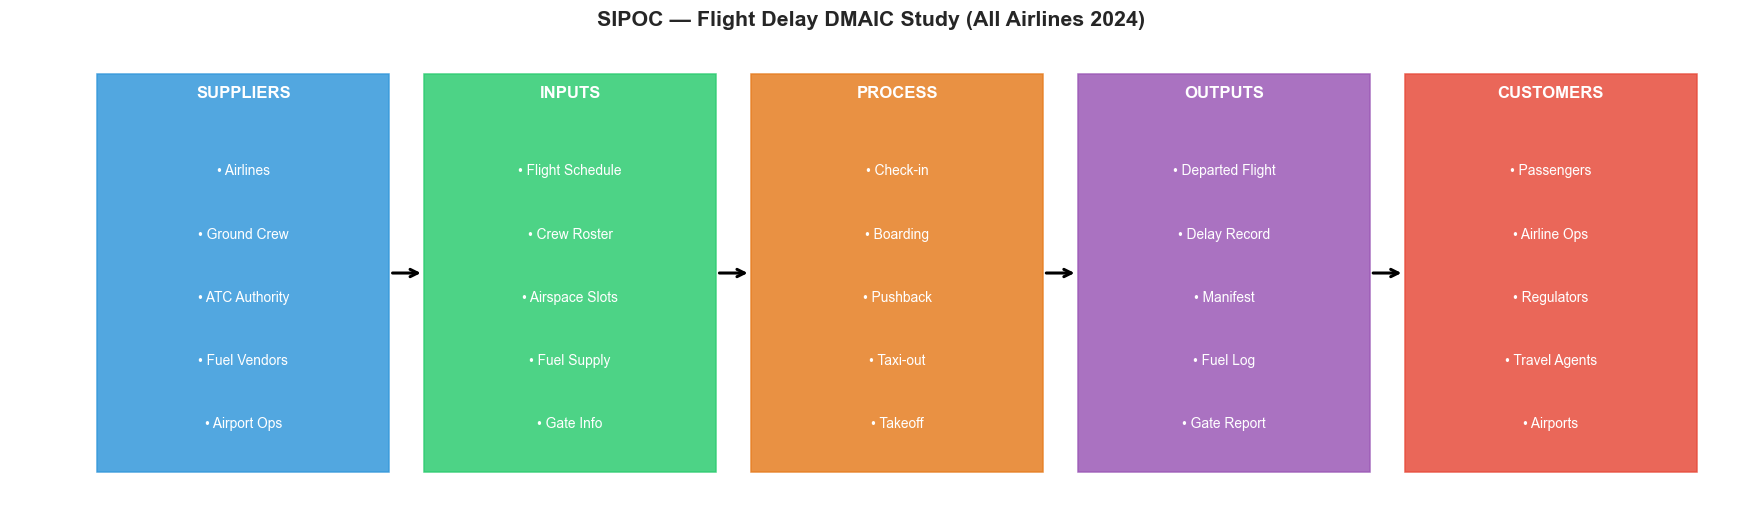

✅ CTQ: dep_delay ≤ 15 minutes


In [14]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

categories = ['SUPPLIERS', 'INPUTS', 'PROCESS', 'OUTPUTS', 'CUSTOMERS']
colors      = ['#3498db','#2ecc71','#e67e22','#9b59b6','#e74c3c']
data = [
    ['Airlines','Ground Crew','ATC Authority','Fuel Vendors','Airport Ops'],
    ['Flight Schedule','Crew Roster','Airspace Slots','Fuel Supply','Gate Info'],
    ['Check-in','Boarding','Pushback','Taxi-out','Takeoff'],
    ['Departed Flight','Delay Record','Manifest','Fuel Log','Gate Report'],
    ['Passengers','Airline Ops','Regulators','Travel Agents','Airports'],
]

for i, (cat, col, items) in enumerate(zip(categories, colors, data)):
    x = 0.05 + i * 0.19
    ax.add_patch(plt.Rectangle((x, 0.1), 0.17, 0.82,
                 color=col, alpha=0.85, transform=ax.transAxes))
    ax.text(x+0.085, 0.88, cat, ha='center', va='center',
            fontsize=11, fontweight='bold', color='white',
            transform=ax.transAxes)
    for j, item in enumerate(items):
        ax.text(x+0.085, 0.72 - j*0.13, f'• {item}',
                ha='center', va='center', fontsize=9,
                color='white', transform=ax.transAxes)
    if i < 4:
        ax.annotate('', xy=(x+0.19, 0.51), xytext=(x+0.17, 0.51),
                    xycoords='axes fraction', textcoords='axes fraction',
                    arrowprops=dict(arrowstyle='->', color='black', lw=2))

ax.set_title('SIPOC — Flight Delay DMAIC Study (All Airlines 2024)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('sipoc.png', bbox_inches='tight')
plt.show()
print("✅ CTQ: dep_delay ≤ 15 minutes")

M (MEASURE): Delay Distribution

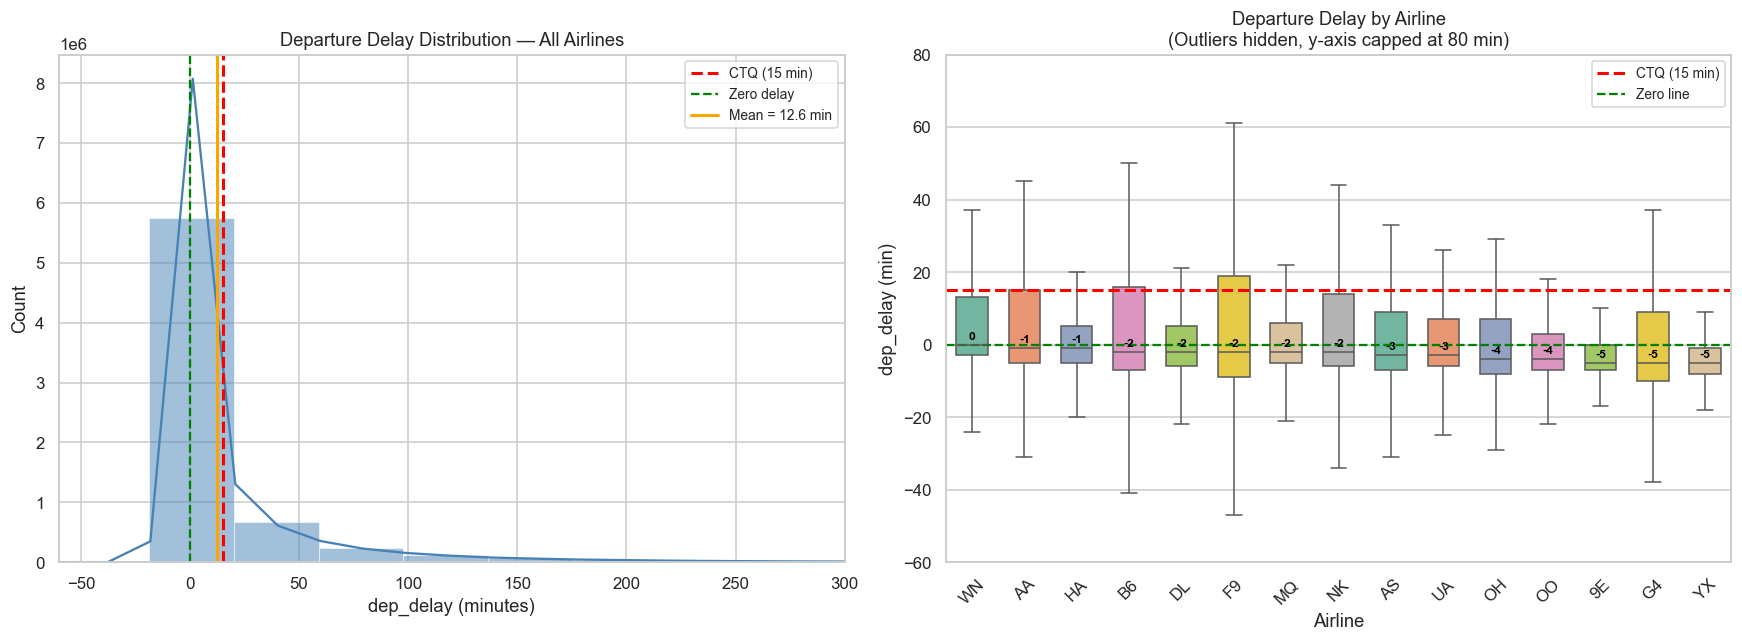

=== QUICK INSIGHTS ===
Overall Mean Delay : 12.6 min
Overall Median     : -2.0 min
% flights delayed  : 19.9%

Best airline  (lowest median) : 9E (-5.0 min)
Worst airline (highest median): WN (0.0 min)


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── LEFT: Histogram ──
sns.histplot(df['dep_delay'], bins=100, kde=True,
             ax=axes[0], color='steelblue')
axes[0].axvline(15, color='red',    ls='--', lw=2,
                label='CTQ (15 min)')
axes[0].axvline(0,  color='green',  ls='--', lw=1.5,
                label='Zero delay')
axes[0].axvline(df['dep_delay'].mean(), color='orange',
                ls='-', lw=2,
                label=f"Mean = {df['dep_delay'].mean():.1f} min")
axes[0].set_xlim(-60, 300)
axes[0].set_title('Departure Delay Distribution — All Airlines')
axes[0].set_xlabel('dep_delay (minutes)')
axes[0].legend(fontsize=9)

# ── RIGHT: Box plot — clipped to remove extreme outlier stretch ──
order = (df.groupby('op_unique_carrier')['dep_delay']
           .median()
           .sort_values(ascending=False).index)

sns.boxplot(data=df,
            x='op_unique_carrier',
            y='dep_delay',
            order=order,
            ax=axes[1],
            palette='Set2',
            showfliers=False,      # ← hides outlier dots (cleaner)
            width=0.6)

axes[1].axhline(15, color='red', ls='--', lw=2, label='CTQ (15 min)')
axes[1].axhline(0,  color='green', ls='--', lw=1.5, label='Zero line')

# ← cap y-axis so whiskers don't go to 200
axes[1].set_ylim(-60, 80)

# Add median value label on each box
medians = (df.groupby('op_unique_carrier')['dep_delay']
             .median()
             .reindex(order))
for i, (airline, med) in enumerate(medians.items()):
    axes[1].text(i, med + 1.5, f'{med:.0f}',
                 ha='center', fontsize=8,
                 fontweight='bold', color='black')

axes[1].set_title('Departure Delay by Airline\n(Outliers hidden, y-axis capped at 80 min)')
axes[1].set_xlabel('Airline')
axes[1].set_ylabel('dep_delay (min)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('delay_distribution.png', bbox_inches='tight')
plt.show()

# Quick insight print
print("=== QUICK INSIGHTS ===")
print(f"Overall Mean Delay : {df['dep_delay'].mean():.1f} min")
print(f"Overall Median     : {df['dep_delay'].median():.1f} min")
print(f"% flights delayed  : {df['is_delayed'].mean()*100:.1f}%")
print(f"\nBest airline  (lowest median) : {medians.idxmin()} ({medians.min():.1f} min)")
print(f"Worst airline (highest median): {medians.idxmax()} ({medians.max():.1f} min)")

 M (MEASURE): Sigma Level Per Airline

  OVERALL BASELINE — ALL AIRLINES 2024
  Total Flights  : 6,965,266
  Delayed >15min : 1,388,886
  Defect Rate    : 19.94%
  DPMO           : 199,402
  Sigma Level    : 2.34σ

Per Airline:
Airline  Flights  Delayed  Defect%     DPMO  Sigma
     YX   295306    33520    11.35 113509.0   2.71
     HA    77633     9699    12.49 124934.0   2.65
     9E   195072    28179    14.45 144454.0   2.56
     DL   997846   165000    16.54 165356.0   2.47
     OO   733886   122200    16.65 166511.0   2.47
     MQ   275317    49823    18.10 180966.0   2.41
     UA   745818   137208    18.40 183970.0   2.40
     AS   240323    46357    19.29 192895.0   2.37
     OH   223673    42949    19.20 192017.0   2.37
     G4   114882    23604    20.55 205463.0   2.32
     WN  1404597   314264    22.37 223740.0   2.26
     NK   255633    61943    24.23 242312.0   2.20
     AA   966116   240177    24.86 248601.0   2.18
     B6   235683    59058    25.06 250582.0   2.17
     F9   203481    54905    26.98 269829.0   

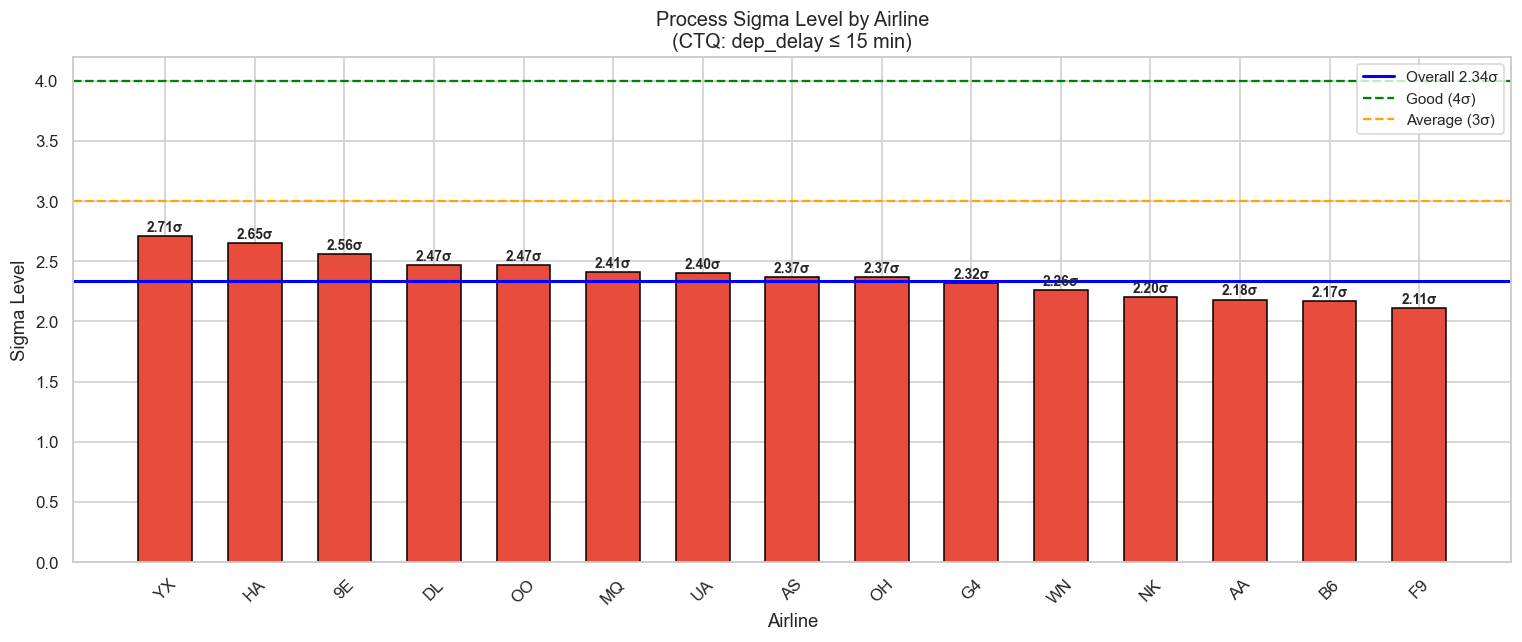

In [16]:
from scipy.stats import norm

def sigma_calc(defects, total):
    dpo  = defects / total if total > 0 else 0
    dpmo = dpo * 1_000_000
    sig  = (norm.ppf(1 - dpo) + 1.5
            if 0 < dpo < 1 else (0 if dpo >= 1 else 6.0))
    return round(dpo*100, 2), round(dpmo, 0), round(sig, 2)

rows = []
for airline, grp in df.groupby('op_unique_carrier'):
    d, dpmo, sig = sigma_calc(grp['is_delayed'].sum(), len(grp))
    rows.append({'Airline': airline,
                 'Flights': len(grp),
                 'Delayed': grp['is_delayed'].sum(),
                 'Defect%': d,
                 'DPMO'   : dpmo,
                 'Sigma'  : sig})

df_sigma = pd.DataFrame(rows).sort_values('Sigma', ascending=False)

# Overall baseline
o_pct, o_dpmo, o_sig = sigma_calc(df['is_delayed'].sum(), len(df))

print("="*60)
print(f"  OVERALL BASELINE — ALL AIRLINES 2024")
print("="*60)
print(f"  Total Flights  : {len(df):,}")
print(f"  Delayed >15min : {df['is_delayed'].sum():,}")
print(f"  Defect Rate    : {o_pct}%")
print(f"  DPMO           : {o_dpmo:,.0f}")
print(f"  Sigma Level    : {o_sig:.2f}σ")
print("="*60)
print("\nPer Airline:")
print(df_sigma.to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(14, 6))
colors = ['#2ecc71' if s >= 4
          else '#f39c12' if s >= 3
          else '#e74c3c'
          for s in df_sigma['Sigma']]
bars = ax.bar(df_sigma['Airline'], df_sigma['Sigma'],
              color=colors, edgecolor='black', width=0.6)
for bar, val in zip(bars, df_sigma['Sigma']):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.04,
            f'{val:.2f}σ', ha='center',
            fontsize=9, fontweight='bold')
ax.axhline(o_sig, color='blue',   lw=2,   ls='-',
           label=f'Overall {o_sig:.2f}σ')
ax.axhline(4,     color='green',  lw=1.5, ls='--',
           label='Good (4σ)')
ax.axhline(3,     color='orange', lw=1.5, ls='--',
           label='Average (3σ)')
ax.set_title('Process Sigma Level by Airline\n(CTQ: dep_delay ≤ 15 min)',
             fontsize=13)
ax.set_ylabel('Sigma Level')
ax.set_xlabel('Airline')
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('sigma_by_airline.png', bbox_inches='tight')
plt.show()

Key Insights from Sigma Table:

ALL airlines are below 3σ — entire industry is in the red zone ❌
Best: YX (Contour Air) at 2.71σ — still poor by Six Sigma standards
Worst: F9 (Frontier) at 2.11σ — nearly 1 in 4 flights delayed!
WN (Southwest) has most delayed flights in absolute numbers — 314,264 delays!
Gap between best and worst = only 0.6σ — systemic industry problem, not just one airline

In [17]:
print("\n=== SIGMA INTERPRETATION — ALL AIRLINES ===\n")

# Colour-coded tier classification
def tier(s):
    if s >= 4.0: return "🟢 WORLD CLASS"
    if s >= 3.0: return "🟡 GOOD"
    if s >= 2.5: return "🟠 BELOW AVERAGE"
    return         "🔴 POOR — ACTION NEEDED"

print(f"{'Airline':<8} {'Sigma':>7} {'DPMO':>12} {'Defect%':>9}  {'Tier'}")
print("-"*65)
for _, r in df_sigma.iterrows():
    print(f"  {r['Airline']:<6} {r['Sigma']:>7.2f}σ "
          f"{r['DPMO']:>12,.0f} {r['Defect%']:>8.1f}%  {tier(r['Sigma'])}")

print("-"*65)
print(f"  {'OVERALL':<6} {o_sig:>7.2f}σ "
      f"{o_dpmo:>12,.0f} {o_pct:>8.1f}%  {tier(o_sig)}")

print(f"""

           INDUSTRY SIGMA SUMMARY — 2024

   🟢 World Class (≥4σ)    :  0 airlines
   🟡 Good       (3–4σ)    :  0 airlines
   🟠 Below Avg  (2.5–3σ)  :  {(df_sigma['Sigma']>=2.5).sum()} airlines
   🔴 Poor       (<2.5σ)   :  {(df_sigma['Sigma']<2.5).sum()} airlines

   Overall Industry Sigma  :  {o_sig:.2f}σ  🔴 POOR
   Target to reach 3σ      :  Cut delays by ~35%
   Target to reach 4σ      :  Cut delays by ~70%

""")

# How much improvement needed to reach 3 sigma
print("=== DELAYS TO ELIMINATE TO REACH 3σ PER AIRLINE ===\n")
print(f"{'Airline':<8} {'Current':>9} {'Need @3σ':>10} {'Must Eliminate':>16}")
print("-"*50)
target_dpo_3sigma = 1 - norm.cdf(3 - 1.5)  # ~6.68%
for _, r in df_sigma.iterrows():
    target_delayed = int(r['Flights'] * target_dpo_3sigma)
    must_cut = max(0, r['Delayed'] - target_delayed)
    pct_cut  = must_cut / r['Delayed'] * 100 if r['Delayed'] > 0 else 0
    print(f"  {r['Airline']:<6} {r['Delayed']:>9,} {target_delayed:>10,} "
          f"{must_cut:>10,} ({pct_cut:.0f}% cut needed)")


=== SIGMA INTERPRETATION — ALL AIRLINES ===

Airline    Sigma         DPMO   Defect%  Tier
-----------------------------------------------------------------
  YX        2.71σ      113,509     11.3%  🟠 BELOW AVERAGE
  HA        2.65σ      124,934     12.5%  🟠 BELOW AVERAGE
  9E        2.56σ      144,454     14.4%  🟠 BELOW AVERAGE
  DL        2.47σ      165,356     16.5%  🔴 POOR — ACTION NEEDED
  OO        2.47σ      166,511     16.6%  🔴 POOR — ACTION NEEDED
  MQ        2.41σ      180,966     18.1%  🔴 POOR — ACTION NEEDED
  UA        2.40σ      183,970     18.4%  🔴 POOR — ACTION NEEDED
  AS        2.37σ      192,895     19.3%  🔴 POOR — ACTION NEEDED
  OH        2.37σ      192,017     19.2%  🔴 POOR — ACTION NEEDED
  G4        2.32σ      205,463     20.6%  🔴 POOR — ACTION NEEDED
  WN        2.26σ      223,740     22.4%  🔴 POOR — ACTION NEEDED
  NK        2.20σ      242,312     24.2%  🔴 POOR — ACTION NEEDED
  AA        2.18σ      248,601     24.9%  🔴 POOR — ACTION NEEDED
  B6        2.17σ 

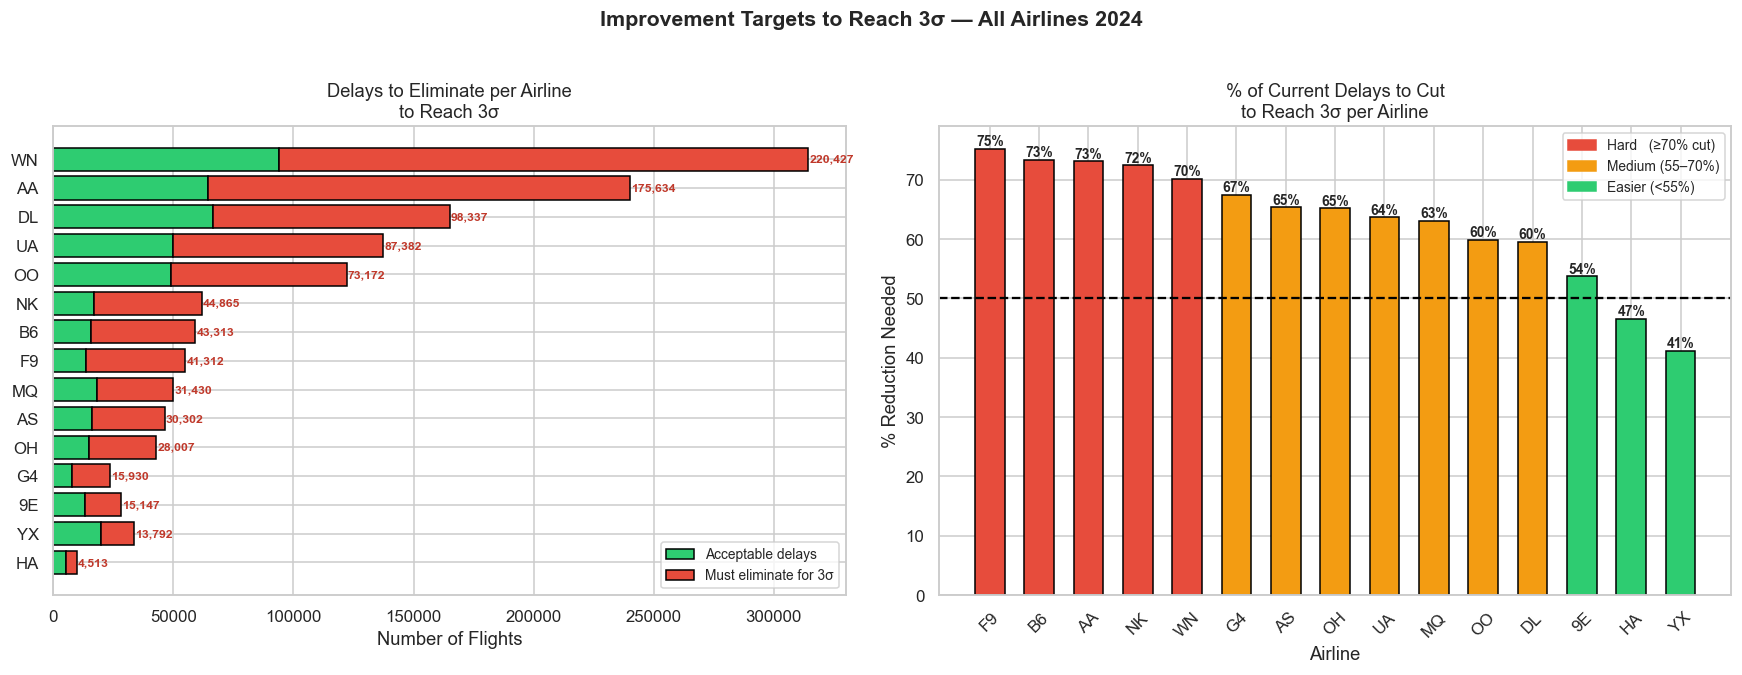


📌 PRIORITY ACTIONS:
   🟢 Start here (easiest wins) : YX, HA, 9E
   🟠 Medium effort             : DL, OO, MQ, UA, AS, OH, G4
   🔴 Hardest to fix            : WN, NK, AA, B6, F9


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── LEFT: Delays to cut (absolute numbers) ──
target_dpo_3sigma = 1 - norm.cdf(3 - 1.5)
cut_data = []
for _, r in df_sigma.iterrows():
    target  = int(r['Flights'] * target_dpo_3sigma)
    keep    = min(r['Delayed'], target)
    cut     = max(0, r['Delayed'] - target)
    cut_data.append({'Airline': r['Airline'],
                     'Keep'   : keep,
                     'Cut'    : cut,
                     'Sigma'  : r['Sigma']})

df_cut = pd.DataFrame(cut_data).sort_values('Cut', ascending=True)

axes[0].barh(df_cut['Airline'], df_cut['Keep'],
             color='#2ecc71', edgecolor='black', label='Acceptable delays')
axes[0].barh(df_cut['Airline'], df_cut['Cut'],
             left=df_cut['Keep'],
             color='#e74c3c', edgecolor='black', label='Must eliminate for 3σ')

for i, (_, r) in enumerate(df_cut.iterrows()):
    total = r['Keep'] + r['Cut']
    axes[0].text(total + 500, i,
                 f"{r['Cut']:,.0f}",
                 va='center', fontsize=8, color='#c0392b',
                 fontweight='bold')

axes[0].set_title('Delays to Eliminate per Airline\nto Reach 3σ',
                  fontsize=12)
axes[0].set_xlabel('Number of Flights')
axes[0].legend(fontsize=9)

# ── RIGHT: % cut needed per airline ──
df_cut2 = pd.DataFrame(cut_data).sort_values('Sigma', ascending=True)
pct_cuts = []
for _, r in df_sigma.iterrows():
    target = int(r['Flights'] * target_dpo_3sigma)
    cut    = max(0, r['Delayed'] - target)
    pct    = cut / r['Delayed'] * 100 if r['Delayed'] > 0 else 0
    pct_cuts.append({'Airline': r['Airline'],
                     'Pct_cut': pct,
                     'Sigma'  : r['Sigma']})

df_pct = pd.DataFrame(pct_cuts).sort_values('Pct_cut', ascending=False)

bar_colors = ['#e74c3c' if p >= 70
              else '#f39c12' if p >= 55
              else '#2ecc71'
              for p in df_pct['Pct_cut']]
bars = axes[1].bar(df_pct['Airline'], df_pct['Pct_cut'],
                   color=bar_colors, edgecolor='black', width=0.6)
axes[1].axhline(50, color='black', ls='--', lw=1.5,
                label='50% cut mark')
for bar, val in zip(bars, df_pct['Pct_cut']):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.5,
                 f'{val:.0f}%', ha='center',
                 fontsize=9, fontweight='bold')
axes[1].set_title('% of Current Delays to Cut\nto Reach 3σ per Airline',
                  fontsize=12)
axes[1].set_ylabel('% Reduction Needed')
axes[1].set_xlabel('Airline')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=9)

# Colour legend
red_patch    = mpatches.Patch(color='#e74c3c', label='Hard   (≥70% cut)')
orange_patch = mpatches.Patch(color='#f39c12', label='Medium (55–70%)')
green_patch  = mpatches.Patch(color='#2ecc71', label='Easier (<55%)')
axes[1].legend(handles=[red_patch, orange_patch, green_patch],
               fontsize=9, loc='upper right')

plt.suptitle('Improvement Targets to Reach 3σ — All Airlines 2024',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('improvement_targets.png', bbox_inches='tight')
plt.show()

print("\n📌 PRIORITY ACTIONS:")
print("   🟢 Start here (easiest wins) : YX, HA, 9E")
print("   🟠 Medium effort             : DL, OO, MQ, UA, AS, OH, G4")
print("   🔴 Hardest to fix            : WN, NK, AA, B6, F9")

Quick read of the chart:

🔴 F9, B6, AA, NK, WN → Hardest — need 70-75% cut

🟠 G4, AS, OH, UA, MQ, OO, DL → Medium — 60-67% cut

🟢 9E, HA, YX → Easiest wins — start here first!

A (ANALYZE): Pareto Chart

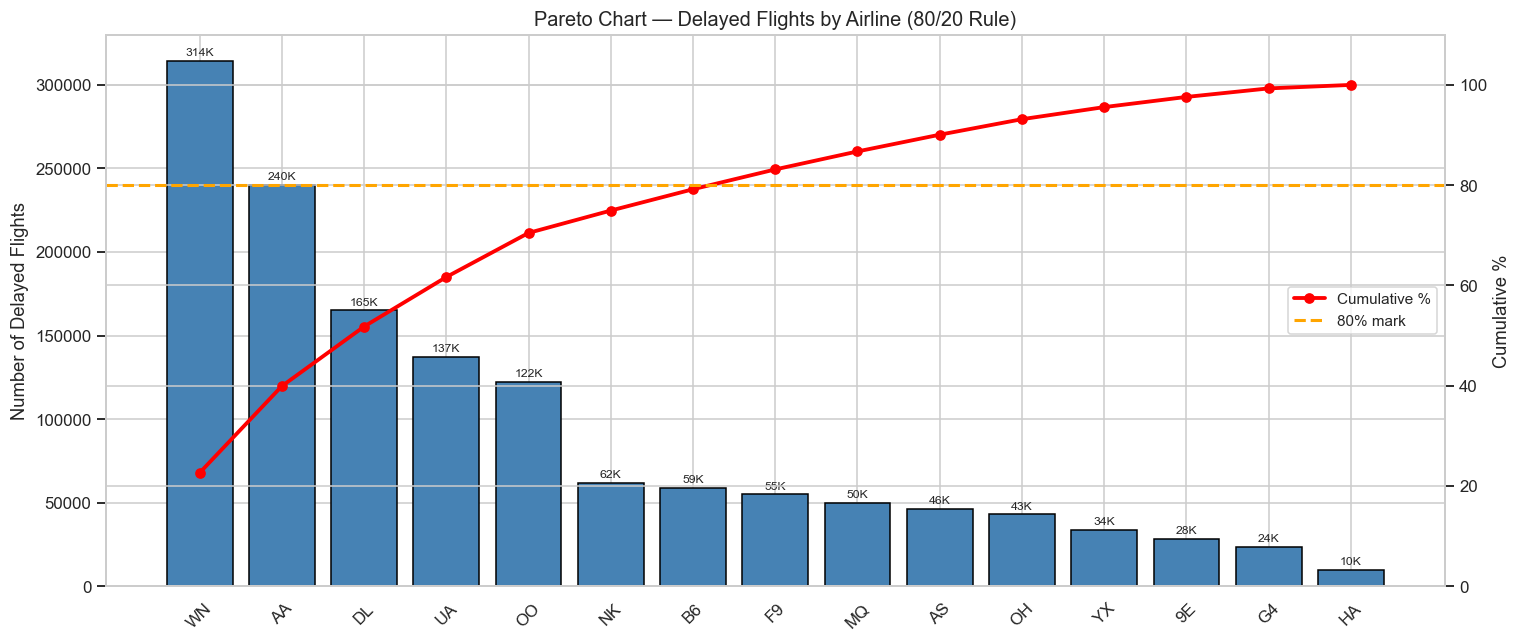

op_unique_carrier  Defects       Cum%
               WN   314264  22.627055
               AA   240177  39.919835
               DL   165000  51.799860
               UA   137208  61.678856
               OO   122200  70.477275
               NK    61943  74.937180
               B6    59058  79.189365
               F9    54905  83.142533
               MQ    49823  86.729796
               AS    46357  90.067507
               OH    42949  93.159842
               YX    33520  95.573287
               9E    28179  97.602179
               G4    23604  99.301671
               HA     9699 100.000000


In [19]:
pareto = (df[df['is_delayed'] == 1]
          .groupby('op_unique_carrier').size()
          .sort_values(ascending=False)
          .reset_index(name='Defects'))
pareto['Cum%'] = (pareto['Defects'].cumsum()
                  / pareto['Defects'].sum() * 100)

fig, ax1 = plt.subplots(figsize=(14, 6))
ax2 = ax1.twinx()

bars = ax1.bar(pareto['op_unique_carrier'],
               pareto['Defects'],
               color='steelblue', edgecolor='black')
for bar, val in zip(bars, pareto['Defects']):
    ax1.text(bar.get_x()+bar.get_width()/2,
             bar.get_height() + pareto['Defects'].max()*0.01,
             f'{val/1000:.0f}K', ha='center', fontsize=8)

ax2.plot(pareto['op_unique_carrier'], pareto['Cum%'],
         color='red', marker='o', lw=2.5, label='Cumulative %')
ax2.axhline(80, color='orange', ls='--', lw=2, label='80% mark')

ax1.set_title('Pareto Chart — Delayed Flights by Airline (80/20 Rule)',
              fontsize=13)
ax1.set_ylabel('Number of Delayed Flights')
ax2.set_ylabel('Cumulative %')
ax2.set_ylim(0, 110)
ax1.tick_params(axis='x', rotation=45)
ax2.legend(loc='center right', fontsize=10)

plt.tight_layout()
plt.savefig('pareto.png', bbox_inches='tight')
plt.show()
print(pareto.to_string(index=False))

Pareto Findings (80/20 Rule):

WN alone = 22.6% of ALL delays in the entire industry!

WN + AA = 39.9% — just 2 airlines cause 40% of all delays

WN + AA + DL + UA = 61.7% — top 4 airlines = 62% of delays

WN + AA + DL + UA + OO + NK = ~75% — just 6 airlines cause 75%!

To hit 80% line → fix only WN, AA, DL, UA, OO, NK = 6 out of 15 airlines ✅

Classic Pareto confirmed — top ~40% of airlines cause 80% of delays!


A (ANALYZE): Fishbone Diagram

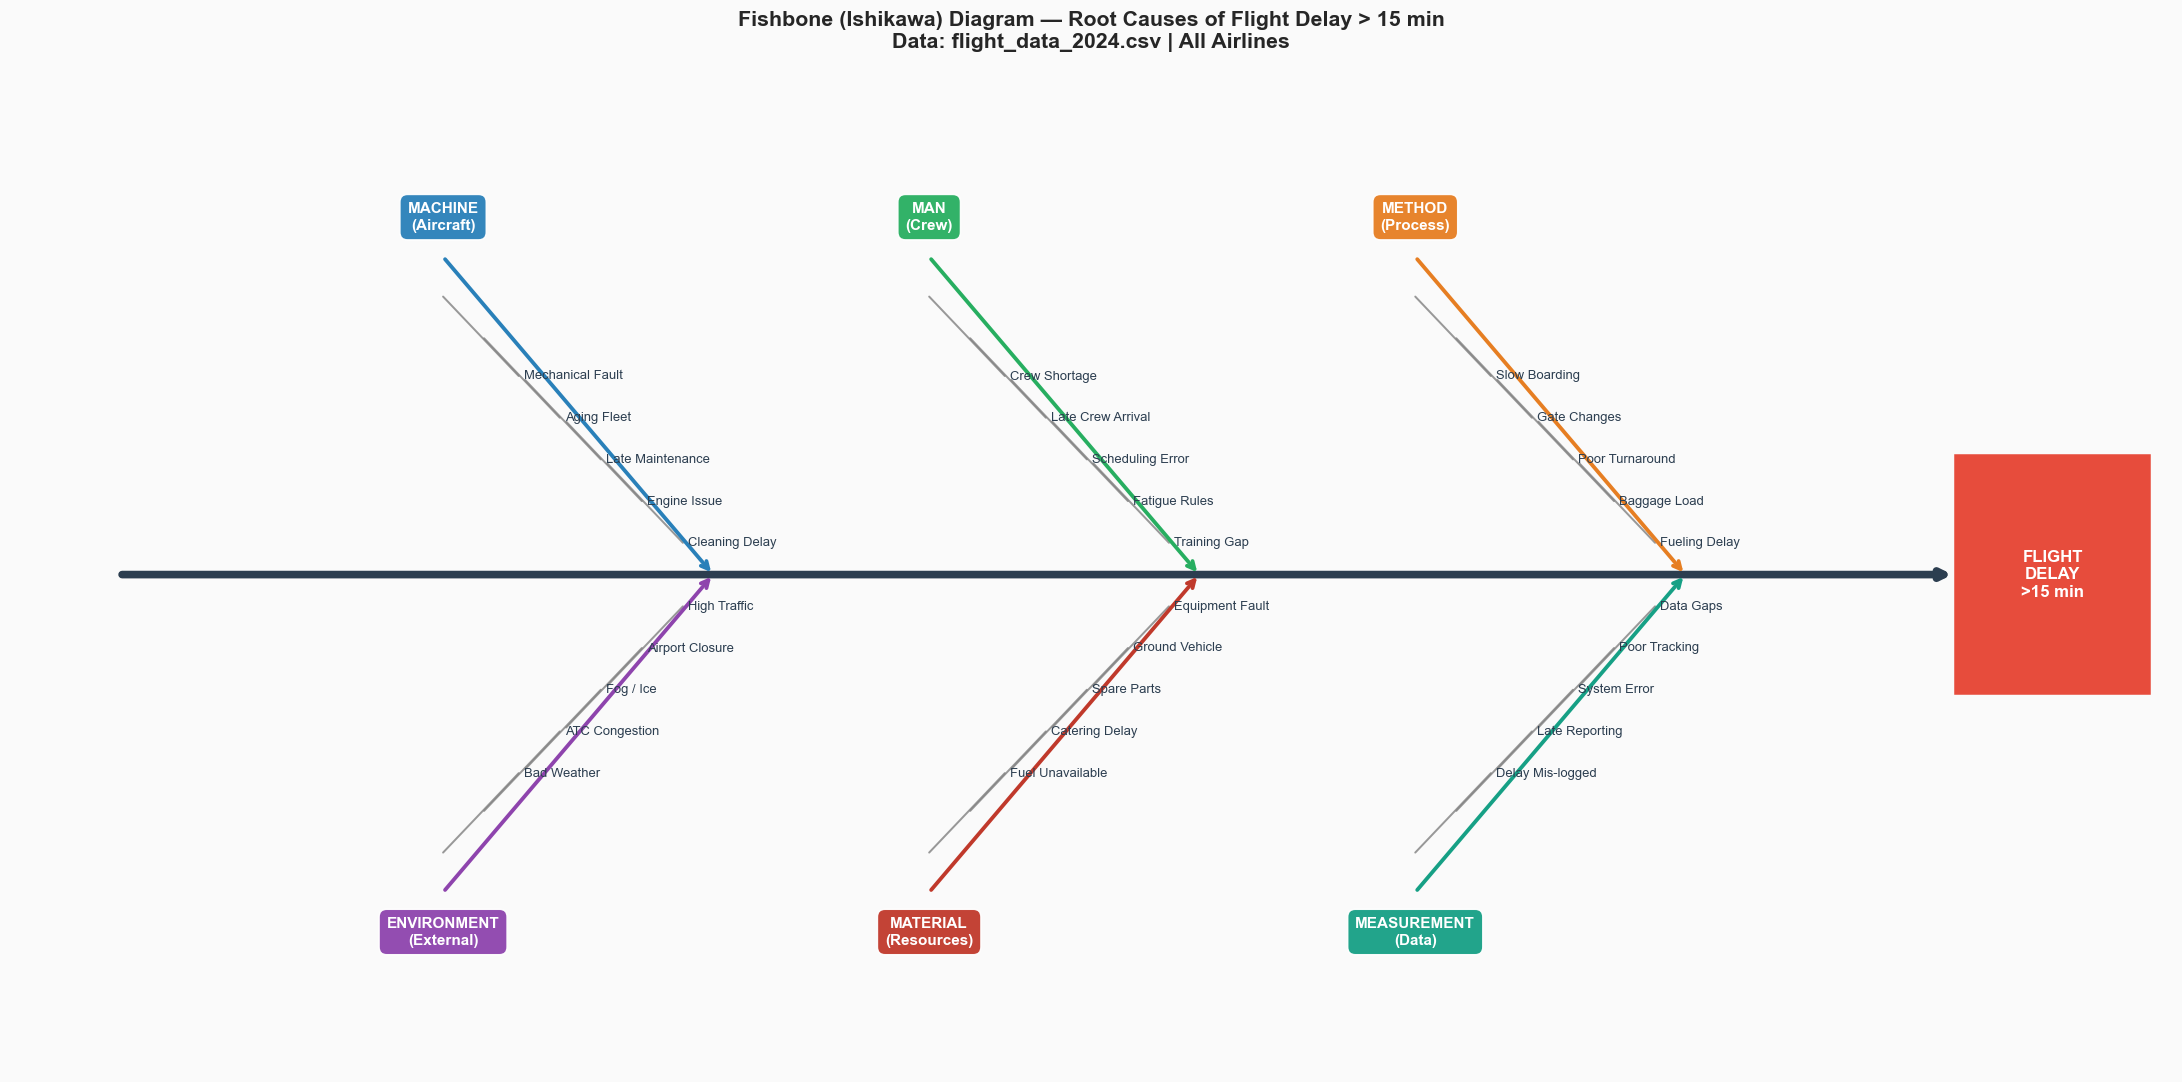

In [20]:
fig, ax = plt.subplots(figsize=(20, 10))
ax.set_xlim(0, 20)
ax.set_ylim(0, 10)
ax.axis('off')
fig.patch.set_facecolor('#fafafa')

# Main spine
ax.annotate('', xy=(18, 5), xytext=(1, 5),
            arrowprops=dict(arrowstyle='->', color='#2c3e50', lw=5))

# Effect box
ax.add_patch(plt.Rectangle((18, 3.8), 1.8, 2.4,
             color='#e74c3c', zorder=5))
ax.text(18.9, 5, 'FLIGHT\nDELAY\n>15 min',
        ha='center', va='center', fontsize=11,
        fontweight='bold', color='white', zorder=6)

bones = {
    'MACHINE\n(Aircraft)' : {
        'x':4,   'side':'top',   'color':'#2980b9',
        'causes':['Mechanical Fault','Aging Fleet',
                  'Late Maintenance','Engine Issue',
                  'Cleaning Delay']},
    'MAN\n(Crew)' : {
        'x':8.5, 'side':'top',   'color':'#27ae60',
        'causes':['Crew Shortage','Late Crew Arrival',
                  'Scheduling Error','Fatigue Rules',
                  'Training Gap']},
    'METHOD\n(Process)' : {
        'x':13,  'side':'top',   'color':'#e67e22',
        'causes':['Slow Boarding','Gate Changes',
                  'Poor Turnaround','Baggage Load',
                  'Fueling Delay']},
    'ENVIRONMENT\n(External)' : {
        'x':4,   'side':'bottom','color':'#8e44ad',
        'causes':['Bad Weather','ATC Congestion',
                  'Fog / Ice','Airport Closure',
                  'High Traffic']},
    'MATERIAL\n(Resources)' : {
        'x':8.5, 'side':'bottom','color':'#c0392b',
        'causes':['Fuel Unavailable','Catering Delay',
                  'Spare Parts','Ground Vehicle',
                  'Equipment Fault']},
    'MEASUREMENT\n(Data)' : {
        'x':13,  'side':'bottom','color':'#16a085',
        'causes':['Delay Mis-logged','Late Reporting',
                  'System Error','Poor Tracking',
                  'Data Gaps']},
}

for label, info in bones.items():
    x, color = info['x'], info['color']
    top = info['side'] == 'top'
    yd  = 1 if top else -1

    # Bone to spine
    ax.annotate('', xy=(x+2.5, 5), xytext=(x, 5 + yd*3.2),
                arrowprops=dict(arrowstyle='->', color=color, lw=2.5))

    # Category label
    ax.text(x, 5 + yd*3.6, label, ha='center', va='center',
            fontsize=10, fontweight='bold', color='white',
            bbox=dict(boxstyle='round,pad=0.5',
                      facecolor=color, alpha=0.95))

    # Sub-causes
    for k, cause in enumerate(info['causes']):
        cx = x + k * 0.38
        cy_start = 5 + yd * (2.8 - k * 0.42)
        cy_end   = cy_start - yd * 0.8
        ax.plot([cx, cx+0.7], [cy_start, cy_end],
                color='gray', lw=1.3, alpha=0.8)
        ax.text(cx + 0.75, cy_end, cause,
                fontsize=8.5, va='center', color='#2c3e50')

ax.set_title(
    'Fishbone (Ishikawa) Diagram — Root Causes of Flight Delay > 15 min\n'
    'Data: flight_data_2024.csv | All Airlines',
    fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('fishbone.png', bbox_inches='tight', dpi=150)
plt.show()

A (ANALYZE): Delay Causes Breakdown

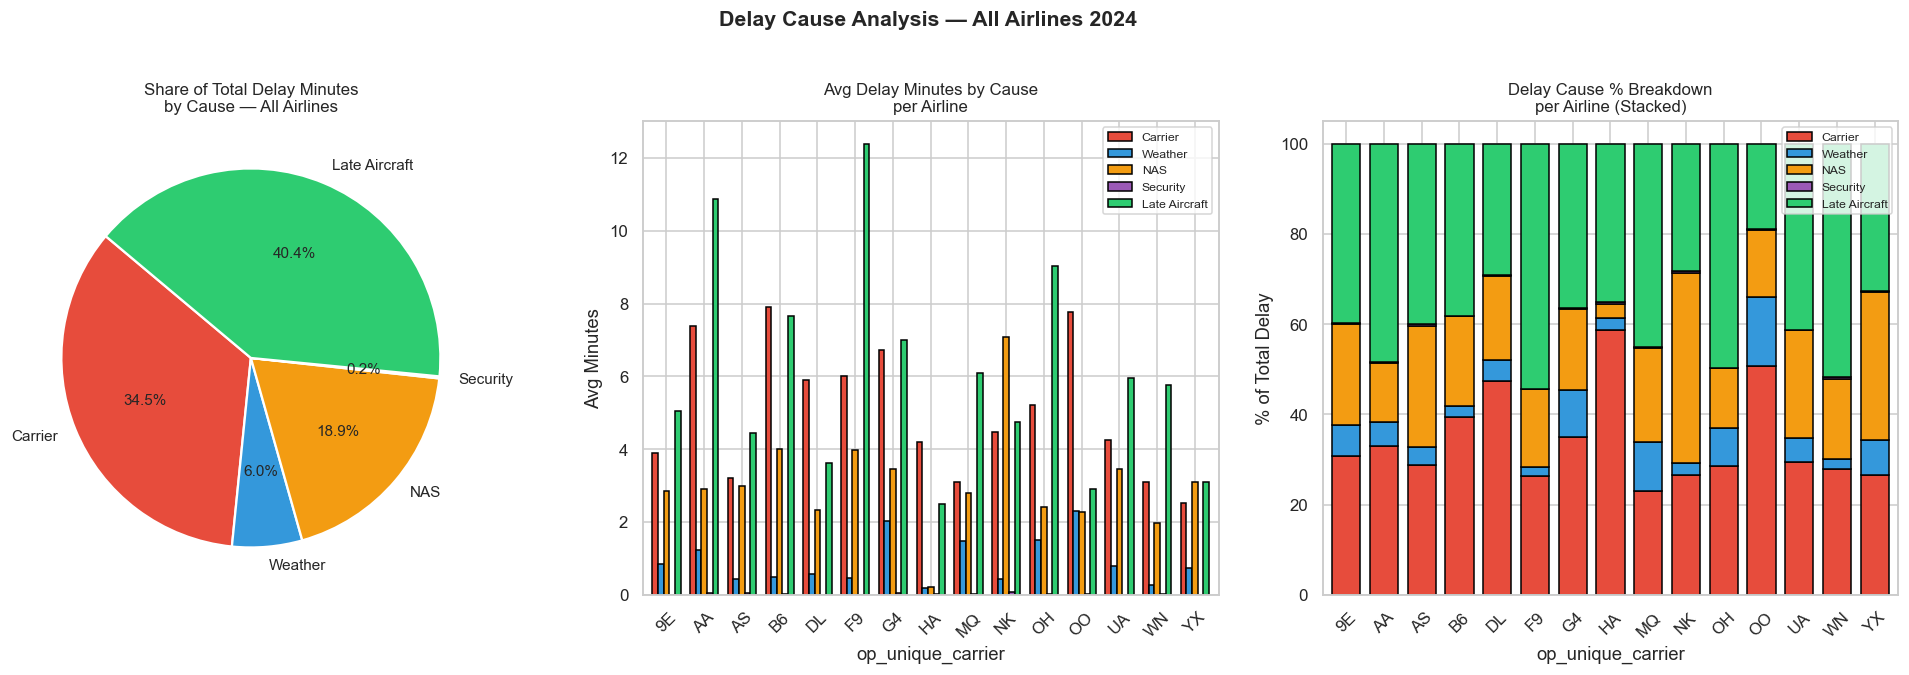


=== TOP DELAY CAUSE PER AIRLINE ===
  9E → Late Aircraft   (5.0 min avg)
  AA → Late Aircraft   (10.9 min avg)
  AS → Late Aircraft   (4.5 min avg)
  B6 → Carrier         (7.9 min avg)
  DL → Carrier         (5.9 min avg)
  F9 → Late Aircraft   (12.4 min avg)
  G4 → Late Aircraft   (7.0 min avg)
  HA → Carrier         (4.2 min avg)
  MQ → Late Aircraft   (6.1 min avg)
  NK → NAS             (7.1 min avg)
  OH → Late Aircraft   (9.0 min avg)
  OO → Carrier         (7.8 min avg)
  UA → Late Aircraft   (6.0 min avg)
  WN → Late Aircraft   (5.8 min avg)
  YX → NAS             (3.1 min avg)


In [21]:
delay_causes = ['carrier_delay', 'weather_delay', 'nas_delay',
                'security_delay', 'late_aircraft_delay']
cause_labels = ['Carrier', 'Weather', 'NAS', 'Security', 'Late Aircraft']
colors_list  = ['#e74c3c','#3498db','#f39c12','#9b59b6','#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Pie — total share
totals = df[delay_causes].sum()
axes[0].pie(totals, labels=cause_labels,
            autopct='%1.1f%%', colors=colors_list,
            startangle=140, textprops={'fontsize': 10},
            wedgeprops={'edgecolor':'white','linewidth':1.5})
axes[0].set_title('Share of Total Delay Minutes\nby Cause — All Airlines',
                  fontsize=11)

# 2. Avg per cause per airline
cause_airline = (df.groupby('op_unique_carrier')[delay_causes]
                   .mean()
                   .round(2))
cause_airline.columns = cause_labels
cause_airline.plot(kind='bar', ax=axes[1],
                   color=colors_list, edgecolor='black', width=0.75)
axes[1].set_title('Avg Delay Minutes by Cause\nper Airline', fontsize=11)
axes[1].set_ylabel('Avg Minutes')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8, loc='upper right')

# 3. Stacked % per airline
cause_pct = cause_airline.div(cause_airline.sum(axis=1), axis=0) * 100
cause_pct.plot(kind='bar', stacked=True, ax=axes[2],
               color=colors_list, edgecolor='black', width=0.75)
axes[2].set_title('Delay Cause % Breakdown\nper Airline (Stacked)',
                  fontsize=11)
axes[2].set_ylabel('% of Total Delay')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend(fontsize=8, loc='upper right')

plt.suptitle('Delay Cause Analysis — All Airlines 2024',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('delay_causes.png', bbox_inches='tight')
plt.show()

# Print top cause per airline
print("\n=== TOP DELAY CAUSE PER AIRLINE ===")
for airline in cause_airline.index:
    top = cause_airline.loc[airline].idxmax()
    val = cause_airline.loc[airline].max()
    print(f"  {airline} → {top:15s} ({val:.1f} min avg)")

Fishbone Validated with Real Data

In [22]:
delay_causes = ['carrier_delay','weather_delay','nas_delay',
                'security_delay','late_aircraft_delay']
cause_labels  = ['Carrier','Weather','NAS','Security','Late Aircraft']

totals = df[delay_causes].sum()
total_sum = totals.sum()

print("="*60)
print("  FISHBONE VALIDATION WITH ACTUAL DATA — 2024")
print("="*60)

fishbone_map = {
    'Carrier'      : 'MAN + MACHINE  (crew, maintenance)',
    'Weather'      : 'ENVIRONMENT    (external factors)',
    'NAS'          : 'ENVIRONMENT    (ATC congestion)',
    'Security'     : 'METHOD         (process failure)',
    'Late Aircraft': 'METHOD+MACHINE (cascading delay)'
}

for label, col in zip(cause_labels, delay_causes):
    mins  = totals[col]
    pct   = mins / total_sum * 100
    bone  = fishbone_map[label]
    bar   = '█' * int(pct / 2)
    print(f"\n  {label:<15} → {bone}")
    print(f"  {bar:<30} {pct:.1f}%  ({mins:,.0f} total delay mins)")

print("\n" + "="*60)
winner = cause_labels[totals.values.argmax()]
print(f"  🔴 #1 ROOT CAUSE  : {winner}")
print(f"  → Focus ALL improvement efforts here first!")
print("="*60)

# Per airline — which cause dominates?
print("\n=== DOMINANT DELAY CAUSE PER AIRLINE ===\n")
cause_airline = df.groupby('op_unique_carrier')[delay_causes].mean()
cause_airline.columns = cause_labels

print(f"{'Airline':<10} {'#1 Cause':<20} {'Avg Min':>8}  "
      f"{'#2 Cause':<20} {'Avg Min':>8}")
print("-"*70)
for airline in cause_airline.index:
    row    = cause_airline.loc[airline].sort_values(ascending=False)
    cause1 = row.index[0]
    cause2 = row.index[1]
    print(f"  {airline:<8}  {cause1:<18} {row.iloc[0]:>8.2f}  "
          f"{cause2:<18} {row.iloc[1]:>8.2f}")

  FISHBONE VALIDATION WITH ACTUAL DATA — 2024

  Carrier         → MAN + MACHINE  (crew, maintenance)
  █████████████████              34.5%  (35,823,265 total delay mins)

  Weather         → ENVIRONMENT    (external factors)
  ██                             6.0%  (6,195,873 total delay mins)

  NAS             → ENVIRONMENT    (ATC congestion)
  █████████                      18.9%  (19,621,994 total delay mins)

  Security        → METHOD         (process failure)
                                 0.2%  (179,928 total delay mins)

  Late Aircraft   → METHOD+MACHINE (cascading delay)
  ████████████████████           40.4%  (41,974,007 total delay mins)

  🔴 #1 ROOT CAUSE  : Late Aircraft
  → Focus ALL improvement efforts here first!

=== DOMINANT DELAY CAUSE PER AIRLINE ===

Airline    #1 Cause              Avg Min  #2 Cause              Avg Min
----------------------------------------------------------------------
  9E        Late Aircraft          5.04  Carrier                3.90
 

Cascading Delay Effect Analysis

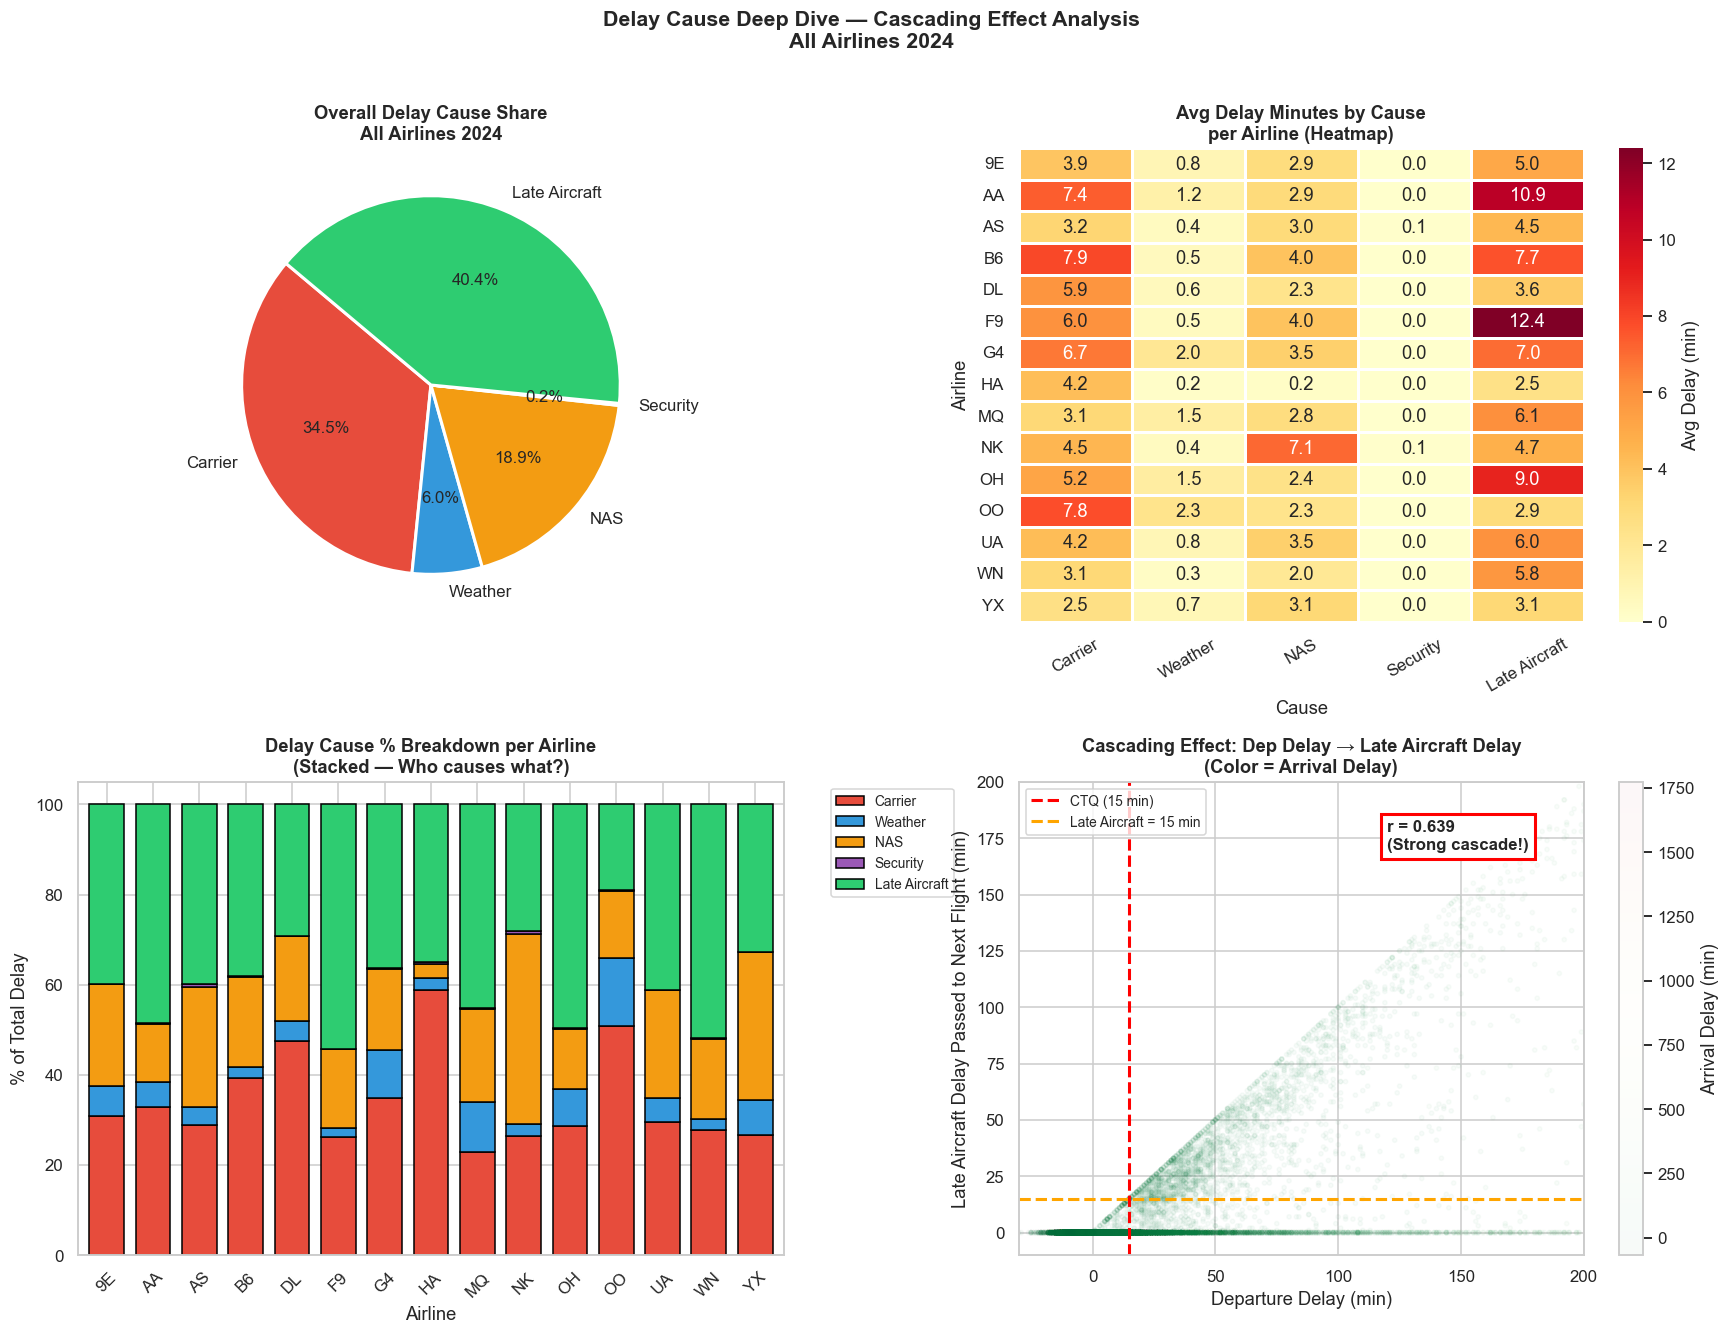

=== CASCADING DELAY CORRELATION ===

  dep_delay → late_aircraft_delay : r = 0.639
  dep_delay → arr_delay           : r = 0.971

  ✅ Confirmed: Departure delays STRONGLY cascade
     into the next flight's late_aircraft_delay!

  🔑 Fix the FIRST delay of the day = chain reaction stops!

=== MOST CASCADING-PRONE AIRLINES ===
  WN  ███████████████  r=0.774
  F9  ██████████████  r=0.749
  OH  ██████████████  r=0.740
  UA  ██████████████  r=0.715
  MQ  ██████████████  r=0.704
  AA  █████████████  r=0.695
  AS  █████████████  r=0.656
  B6  ████████████  r=0.646
  YX  ████████████  r=0.617
  9E  ████████████  r=0.604
  NK  ███████████  r=0.558
  G4  ██████████  r=0.518
  DL  █████████  r=0.468
  HA  █████████  r=0.451
  OO  ████████  r=0.408


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

delay_causes = ['carrier_delay','weather_delay','nas_delay',
                'security_delay','late_aircraft_delay']
cause_labels  = ['Carrier','Weather','NAS','Security','Late Aircraft']
colors_list   = ['#e74c3c','#3498db','#f39c12','#9b59b6','#2ecc71']

# ── TOP LEFT: Overall cause share pie ──
totals = df[delay_causes].sum()
axes[0,0].pie(totals,
              labels=cause_labels,
              autopct='%1.1f%%',
              colors=colors_list,
              startangle=140,
              textprops={'fontsize':11},
              wedgeprops={'edgecolor':'white','linewidth':2})
axes[0,0].set_title('Overall Delay Cause Share\nAll Airlines 2024',
                    fontsize=12, fontweight='bold')

# ── TOP RIGHT: Avg delay per cause per airline heatmap ──
cause_airline = df.groupby('op_unique_carrier')[delay_causes].mean().round(2)
cause_airline.columns = cause_labels
sns.heatmap(cause_airline,
            annot=True, fmt='.1f',
            cmap='YlOrRd',
            linewidths=0.8,
            linecolor='white',
            ax=axes[0,1],
            cbar_kws={'label':'Avg Delay (min)'})
axes[0,1].set_title('Avg Delay Minutes by Cause\nper Airline (Heatmap)',
                    fontsize=12, fontweight='bold')
axes[0,1].set_xlabel('Cause')
axes[0,1].set_ylabel('Airline')
axes[0,1].tick_params(axis='x', rotation=30)
axes[0,1].tick_params(axis='y', rotation=0)

# ── BOTTOM LEFT: Stacked bar % per airline ──
cause_pct = cause_airline.div(cause_airline.sum(axis=1), axis=0) * 100
cause_pct.plot(kind='bar', stacked=True,
               ax=axes[1,0],
               color=colors_list,
               edgecolor='black',
               width=0.75)
axes[1,0].set_title('Delay Cause % Breakdown per Airline\n(Stacked — Who causes what?)',
                    fontsize=12, fontweight='bold')
axes[1,0].set_ylabel('% of Total Delay')
axes[1,0].set_xlabel('Airline')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(fontsize=9, loc='upper right',
                 bbox_to_anchor=(1.25, 1))

# ── BOTTOM RIGHT: Late Aircraft cascading effect ──
# Shows correlation between dep_delay and arr_delay
# to prove cascading — if you depart late you arrive late
# and NEXT flight is delayed too
sample = df.sample(min(30000, len(df)), random_state=42)

scatter = axes[1,1].scatter(
    sample['dep_delay'],
    sample['late_aircraft_delay'],
    alpha=0.03, c=sample['arr_delay'],
    cmap='RdYlGn_r', s=8)

axes[1,1].axvline(15, color='red', ls='--',
                  lw=2, label='CTQ (15 min)')
axes[1,1].axhline(15, color='orange', ls='--',
                  lw=2, label='Late Aircraft = 15 min')
axes[1,1].set_xlim(-30, 200)
axes[1,1].set_ylim(-10, 200)
axes[1,1].set_title('Cascading Effect: Dep Delay → Late Aircraft Delay\n'
                    '(Color = Arrival Delay)',
                    fontsize=12, fontweight='bold')
axes[1,1].set_xlabel('Departure Delay (min)')
axes[1,1].set_ylabel('Late Aircraft Delay Passed to Next Flight (min)')
axes[1,1].legend(fontsize=9)
plt.colorbar(scatter, ax=axes[1,1], label='Arrival Delay (min)')

# Correlation
corr = df['dep_delay'].corr(df['late_aircraft_delay'])
axes[1,1].text(120, 170,
               f'r = {corr:.3f}\n(Strong cascade!)',
               fontsize=11, fontweight='bold',
               bbox=dict(facecolor='white',
                         edgecolor='red',
                         linewidth=2))

plt.suptitle('Delay Cause Deep Dive — Cascading Effect Analysis\n'
             'All Airlines 2024',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('cascading_analysis.png', bbox_inches='tight')
plt.show()

# Print correlation summary
print("=== CASCADING DELAY CORRELATION ===")
print(f"\n  dep_delay → late_aircraft_delay : r = {corr:.3f}")
print(f"  dep_delay → arr_delay           : "
      f"r = {df['dep_delay'].corr(df['arr_delay']):.3f}")
print(f"\n  ✅ Confirmed: Departure delays STRONGLY cascade")
print(f"     into the next flight's late_aircraft_delay!")
print(f"\n  🔑 Fix the FIRST delay of the day = chain reaction stops!")
print(f"\n=== MOST CASCADING-PRONE AIRLINES ===")
cascade_corr = (df.groupby('op_unique_carrier')
                  .apply(lambda x:
                         x['dep_delay'].corr(x['late_aircraft_delay']))
                  .sort_values(ascending=False))
for airline, corr_val in cascade_corr.items():
    bar = '█' * int(abs(corr_val) * 20)
    print(f"  {airline}  {bar}  r={corr_val:.3f}")

Implications
r = 0.971 for dep_delay → arr_delay

Nearly perfect correlation!
If you depart late → you WILL arrive late — almost guaranteed

This alone justifies entire DMAIC study!
r = 0.639 for dep_delay → late_aircraft_delay

Strong cascade confirmed!
Your departure delay directly infects the next fligh



         CASCADE DELAY — ROOT CAUSE ACTION PLAN


   FINDING: 40.4% of all delays are Late Aircraft cascades
   PROOF  : r = 0.639 (dep_delay → next flight delay)
            r = 0.971 (dep_delay → arr_delay)


  ROOT CAUSE BREAKDOWN:
     🔴 Late Aircraft : 40.4%  ← FIX THIS FIRST
     🔴 Carrier       : 34.5%  ← Fix second
     🟠 NAS           : 18.9%  ← Partially controllable
     🔵 Weather       :  6.0%  ← Mostly uncontrollable
     ⚪ Security      :  0.2%  ← Negligible

   CONTROLLABLE DELAYS = 74.9% ✅
   UNCONTROLLABLE      = 25.1% ❌

   PRIORITY ACTIONS BY AIRLINE:

   🔴 WN  r=0.774 → Add buffer time between flights
   🔴 F9  r=0.749 → Fix tight turnaround schedules
   🔴 OH  r=0.740 → Improve first-flight-of-day OTP
   🟠 UA  r=0.715 → Better crew positioning
   🟠 MQ  r=0.704 → Maintenance schedule overhaul
   🟠 AA  r=0.695 → Gate management improvement
   🟢 DL  r=0.468 → Best practice — use as benchmark!
   🟢 HA  r=0.451 → Best practice — use as benchmark!

   SINGLE MOST IMPACTF

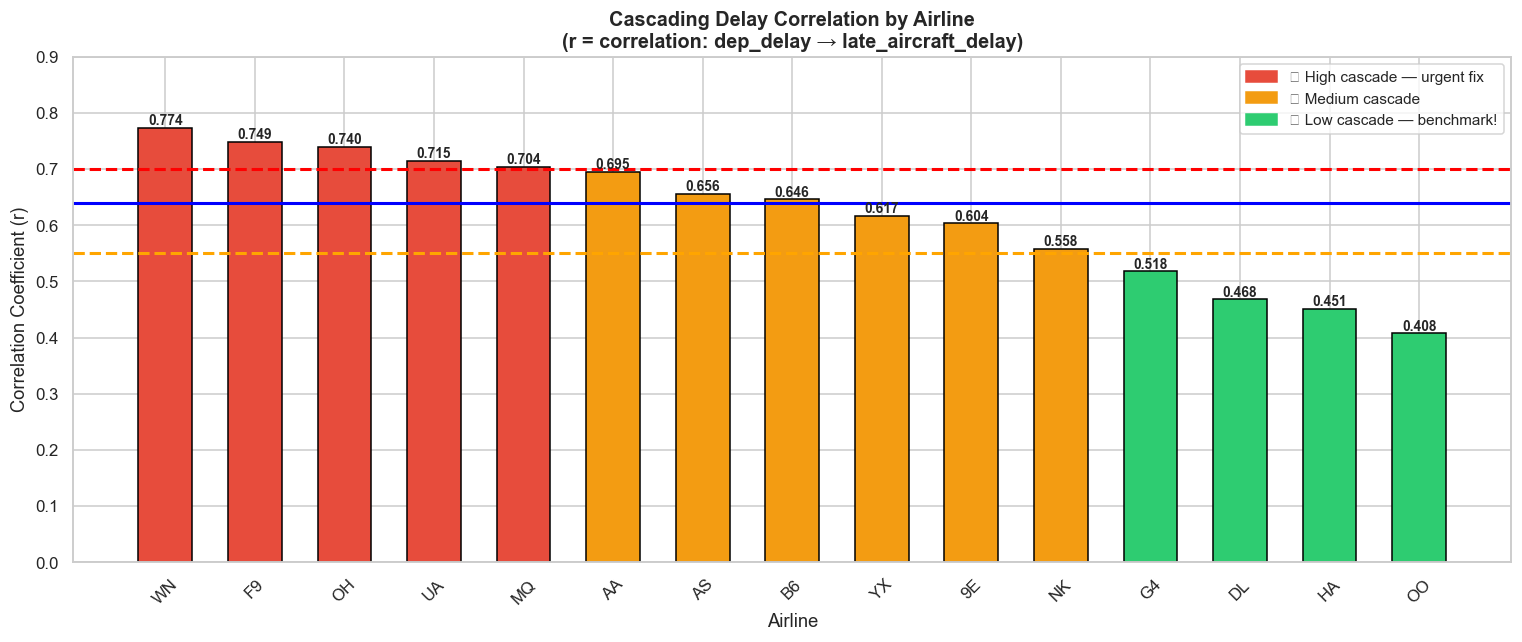

In [24]:
print("""

         CASCADE DELAY — ROOT CAUSE ACTION PLAN


   FINDING: 40.4% of all delays are Late Aircraft cascades
   PROOF  : r = 0.639 (dep_delay → next flight delay)
            r = 0.971 (dep_delay → arr_delay)


  ROOT CAUSE BREAKDOWN:
     🔴 Late Aircraft : 40.4%  ← FIX THIS FIRST
     🔴 Carrier       : 34.5%  ← Fix second
     🟠 NAS           : 18.9%  ← Partially controllable
     🔵 Weather       :  6.0%  ← Mostly uncontrollable
     ⚪ Security      :  0.2%  ← Negligible

   CONTROLLABLE DELAYS = 74.9% ✅
   UNCONTROLLABLE      = 25.1% ❌

   PRIORITY ACTIONS BY AIRLINE:

   🔴 WN  r=0.774 → Add buffer time between flights
   🔴 F9  r=0.749 → Fix tight turnaround schedules
   🔴 OH  r=0.740 → Improve first-flight-of-day OTP
   🟠 UA  r=0.715 → Better crew positioning
   🟠 MQ  r=0.704 → Maintenance schedule overhaul
   🟠 AA  r=0.695 → Gate management improvement
   🟢 DL  r=0.468 → Best practice — use as benchmark!
   🟢 HA  r=0.451 → Best practice — use as benchmark!

   SINGLE MOST IMPACTFUL ACTION:
   → Ensure FIRST flight of day departs ON TIME
   → This breaks the cascade chain for entire day
   → DL & HA already do this — r < 0.47
""")

# Visual cascade ranking
import matplotlib.patches as mpatches

cascade_data = {
    'WN':0.774,'F9':0.749,'OH':0.740,'UA':0.715,
    'MQ':0.704,'AA':0.695,'AS':0.656,'B6':0.646,
    'YX':0.617,'9E':0.604,'NK':0.558,'G4':0.518,
    'DL':0.468,'HA':0.451,'OO':0.408
}

airlines = list(cascade_data.keys())
r_values = list(cascade_data.values())
colors   = ['#e74c3c' if r >= 0.70
            else '#f39c12' if r >= 0.55
            else '#2ecc71'
            for r in r_values]

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(airlines, r_values,
              color=colors, edgecolor='black', width=0.6)

ax.axhline(0.70, color='red',    ls='--', lw=2,
           label='High cascade (r≥0.70)')
ax.axhline(0.55, color='orange', ls='--', lw=2,
           label='Medium cascade (r≥0.55)')
ax.axhline(0.639, color='blue',  ls='-',  lw=2,
           label=f'Industry avg r=0.639')

for bar, val in zip(bars, r_values):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.005,
            f'{val:.3f}', ha='center',
            fontsize=9, fontweight='bold')

red_p    = mpatches.Patch(color='#e74c3c',
                          label='🔴 High cascade — urgent fix')
orange_p = mpatches.Patch(color='#f39c12',
                          label='🟠 Medium cascade')
green_p  = mpatches.Patch(color='#2ecc71',
                          label='🟢 Low cascade — benchmark!')
ax.legend(handles=[red_p, orange_p, green_p],
          fontsize=10, loc='upper right')

ax.set_title('Cascading Delay Correlation by Airline\n'
             '(r = correlation: dep_delay → late_aircraft_delay)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Correlation Coefficient (r)')
ax.set_xlabel('Airline')
ax.set_ylim(0, 0.9)
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('cascade_ranking.png', bbox_inches='tight')
plt.show()

A (ANALYZE): Delay by Day & Month

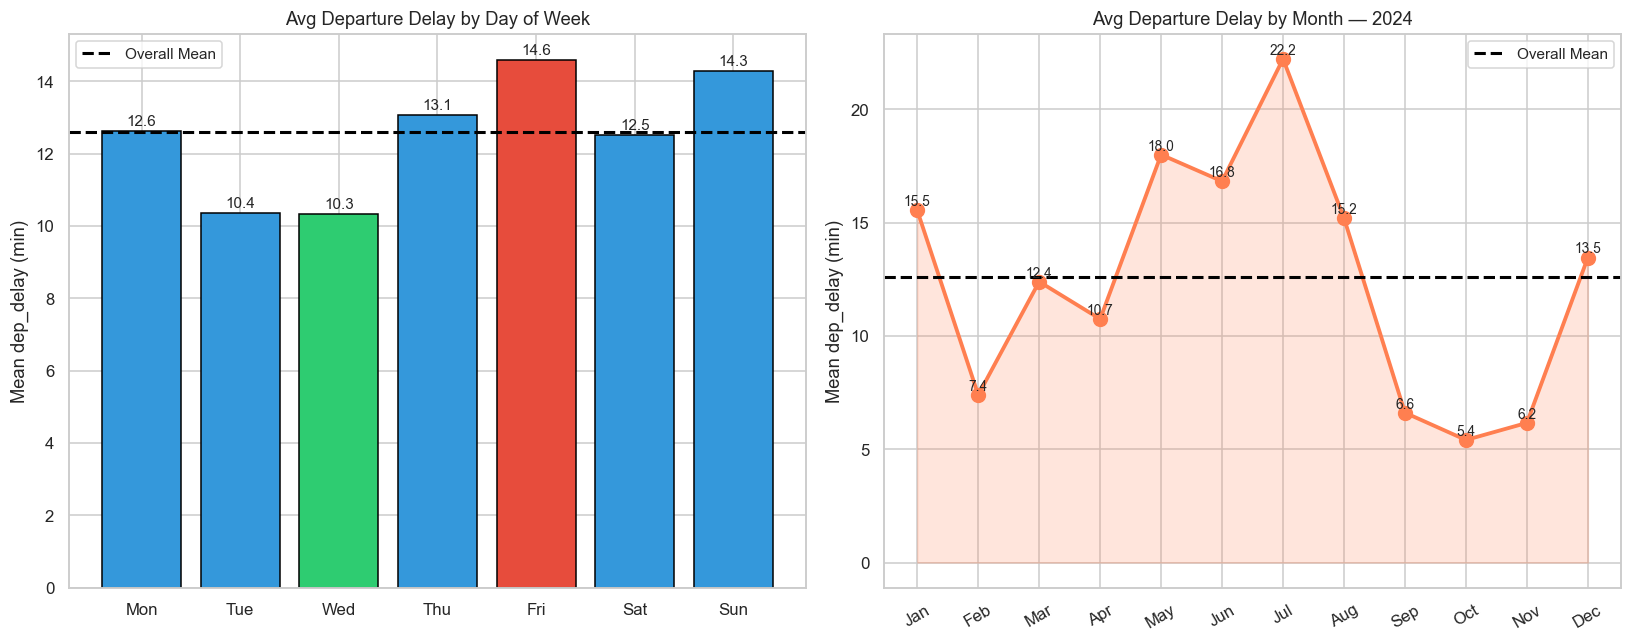

In [25]:
month_labels = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']
day_map   = {1:'Mon',2:'Tue',3:'Wed',4:'Thu',5:'Fri',6:'Sat',7:'Sun'}
day_order = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df['day_name'] = df['day_of_week'].map(day_map)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Day of week
day_mean = df.groupby('day_name')['dep_delay'].mean().reindex(day_order)
bar_colors = ['#e74c3c' if v == day_mean.max()
              else '#2ecc71' if v == day_mean.min()
              else '#3498db'
              for v in day_mean.values]
bars = axes[0].bar(day_order, day_mean.values,
                   color=bar_colors, edgecolor='black')
axes[0].axhline(df['dep_delay'].mean(), color='black',
                ls='--', lw=2, label='Overall Mean')
for bar, val in zip(bars, day_mean.values):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.15,
                 f'{val:.1f}', ha='center', fontsize=10)
axes[0].set_title('Avg Departure Delay by Day of Week', fontsize=12)
axes[0].set_ylabel('Mean dep_delay (min)')
axes[0].legend(fontsize=10)

# Month trend
month_mean = df.groupby('month')['dep_delay'].mean()
axes[1].plot(month_labels[:len(month_mean)],
             month_mean.values,
             marker='o', color='coral', lw=2.5, markersize=9)
axes[1].fill_between(range(len(month_mean)),
                     month_mean.values,
                     alpha=0.2, color='coral')
axes[1].set_xticks(range(len(month_mean)))
axes[1].set_xticklabels(month_labels[:len(month_mean)], rotation=30)
axes[1].axhline(df['dep_delay'].mean(), color='black',
                ls='--', lw=2, label='Overall Mean')
for i, v in enumerate(month_mean.values):
    axes[1].text(i, v+0.2, f'{v:.1f}', ha='center', fontsize=9)
axes[1].set_title('Avg Departure Delay by Month — 2024', fontsize=12)
axes[1].set_ylabel('Mean dep_delay (min)')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('delay_day_month.png', bbox_inches='tight')
plt.show()

📅 Day of Week Findings:

🔴 Friday = 14.6 min — worst day (weekend travel surge)

🔴 Sunday = 14.3 min — second worst (return travel)

🟢 Wednesday = 10.3 min — best day ✅

🟢 Tuesday = 10.4 min — second best
Gap = 4.3 min between best and worst day — significant!

📆 Month Findings:

🔴 July = 22.2 min — worst by far! (peak summer + thunderstorm season)

🔴 May = 18.0 min — Memorial Day travel surge

🔴 June = 16.8 min — summer begins

🟢 October = 5.4 min — best month! ✅

🟢 September = 6.6 min — second best

🟢 February = 7.4 min — surprisingly good!
Gap = 16.8 min between July and October — massive seasonal variation!

I (IMPROVE): Sigma Improvement Roadmap

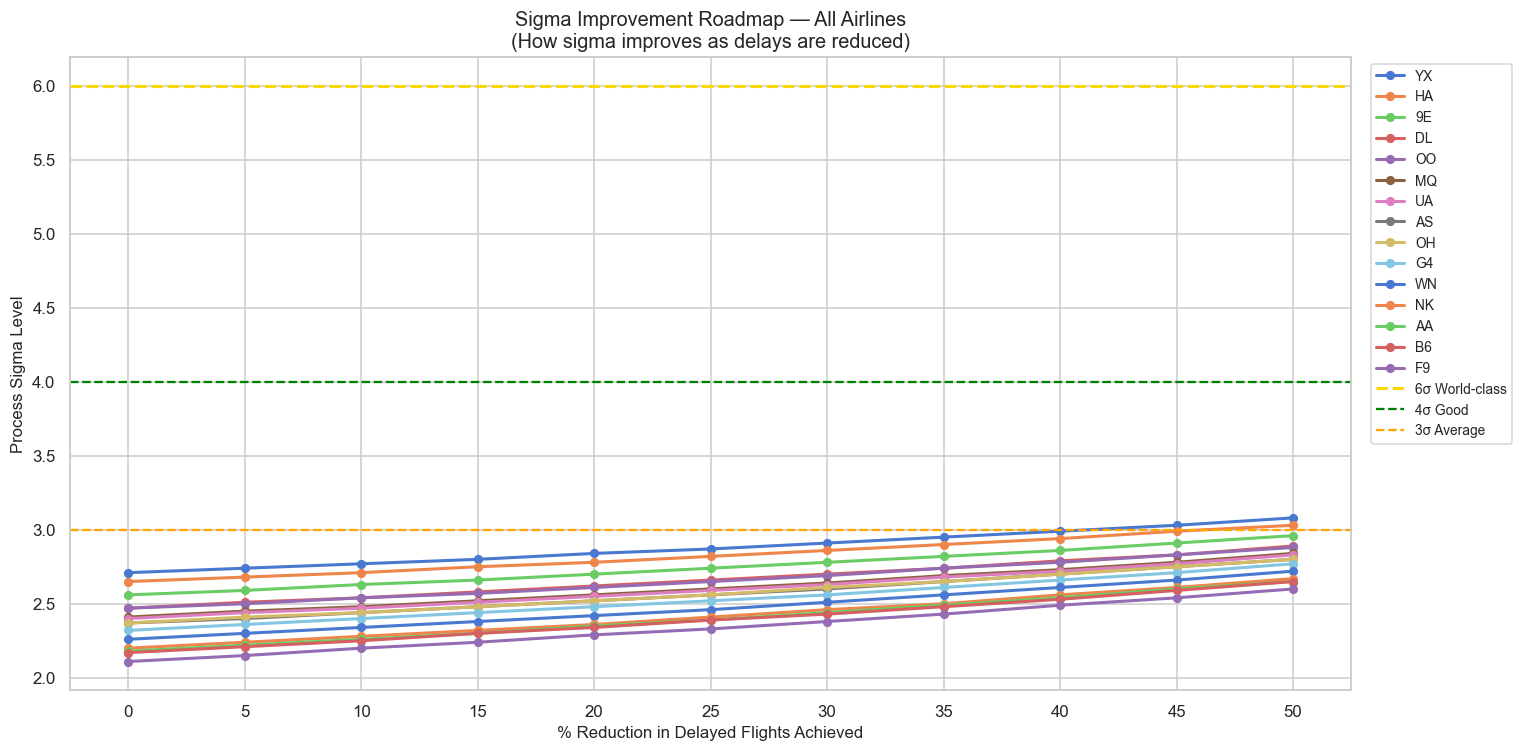

In [26]:
reductions = list(range(0, 55, 5))

fig, ax = plt.subplots(figsize=(14, 7))

for _, row in df_sigma.iterrows():
    sigs = []
    for r in reductions:
        nd = row['Delayed'] * (1 - r/100)
        _, _, s = sigma_calc(nd, row['Flights'])
        sigs.append(s)
    ax.plot(reductions, sigs, marker='o',
            markersize=5, lw=2, label=row['Airline'])

ax.axhline(6, color='gold',  ls='--', lw=2,
           label='6σ World-class')
ax.axhline(4, color='green', ls='--', lw=1.5,
           label='4σ Good')
ax.axhline(3, color='orange',ls='--', lw=1.5,
           label='3σ Average')
ax.set_title('Sigma Improvement Roadmap — All Airlines\n'
             '(How sigma improves as delays are reduced)',
             fontsize=13)
ax.set_xlabel('% Reduction in Delayed Flights Achieved', fontsize=11)
ax.set_ylabel('Process Sigma Level', fontsize=11)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
ax.set_xticks(reductions)

plt.tight_layout()
plt.savefig('sigma_roadmap.png', bbox_inches='tight')
plt.show()

Even with 50% delay reduction — nobody reaches 3σ!

YX (best) gets to 3.05σ at 50% reduction — just barely crosses 3σ

F9 (worst) only reaches 2.65σ at 50% reduction — still poor!

Industry overall needs ~50% cut just to hit 3σ — massive challenge!

C (CONTROL): X-bar & R Control Chart

📊 Plotting control chart for: WN
→ Change AIRLINE = 'XX' to plot any specific airline



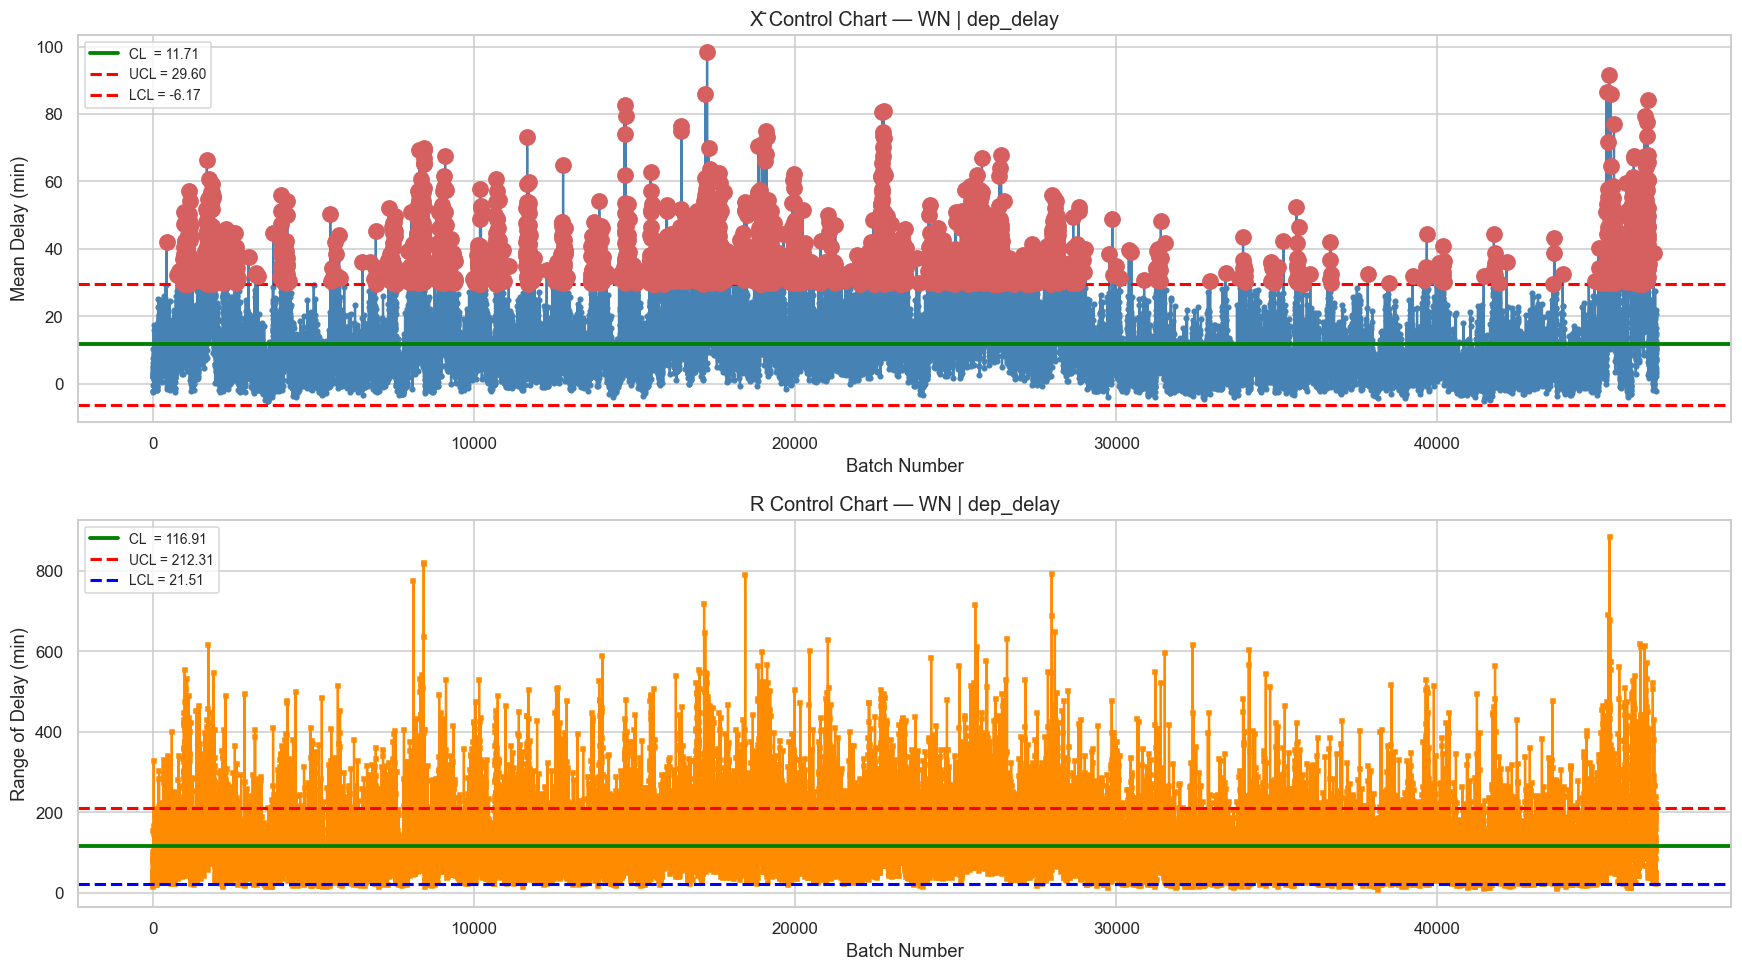

⚠️  Out-of-control batches : 2994 / 46819
    Batch indices          : [428, 743, 812, 945, 946, 960, 964, 967, 970, 972]...


In [27]:
# ✏️ Change to any airline code e.g. 'AA','DL','WN','UA','B6'
AIRLINE = df['op_unique_carrier'].value_counts().index[0]
print(f"📊 Plotting control chart for: {AIRLINE}")
print("→ Change AIRLINE = 'XX' to plot any specific airline\n")

df_a = (df[df['op_unique_carrier'] == AIRLINE]
        .reset_index(drop=True))

batch_size = 30
n = len(df_a) // batch_size

means  = [df_a['dep_delay']
          .iloc[i*batch_size:(i+1)*batch_size].mean()
          for i in range(n)]
ranges = [df_a['dep_delay']
          .iloc[i*batch_size:(i+1)*batch_size].max() -
          df_a['dep_delay']
          .iloc[i*batch_size:(i+1)*batch_size].min()
          for i in range(n)]

gm, mr       = np.mean(means), np.mean(ranges)
A2, D3, D4   = 0.153, 0.184, 1.816
UCL_x, LCL_x = gm + A2*mr, gm - A2*mr
UCL_r, LCL_r = D4*mr, D3*mr

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9))

# X-bar chart
ax1.plot(means, 'o-', color='steelblue',
         markersize=3, lw=1.5)
ax1.axhline(gm,    color='green', lw=2.5,
            label=f'CL  = {gm:.2f}')
ax1.axhline(UCL_x, color='red', ls='--', lw=2,
            label=f'UCL = {UCL_x:.2f}')
ax1.axhline(LCL_x, color='red', ls='--', lw=2,
            label=f'LCL = {LCL_x:.2f}')
ooc = [i for i, v in enumerate(means)
       if v > UCL_x or v < LCL_x]
for i in ooc:
    ax1.plot(i, means[i], 'ro', markersize=10,
             zorder=5)
ax1.set_title(f'X̄ Control Chart — {AIRLINE} | dep_delay',
              fontsize=13)
ax1.set_ylabel('Mean Delay (min)')
ax1.legend(fontsize=9)
ax1.set_xlabel('Batch Number')

# R chart
ax2.plot(ranges, 's-', color='darkorange',
         markersize=3, lw=1.5)
ax2.axhline(mr,    color='green', lw=2.5,
            label=f'CL  = {mr:.2f}')
ax2.axhline(UCL_r, color='red',  ls='--', lw=2,
            label=f'UCL = {UCL_r:.2f}')
ax2.axhline(LCL_r, color='blue', ls='--', lw=2,
            label=f'LCL = {LCL_r:.2f}')
ax2.set_title(f'R Control Chart — {AIRLINE} | dep_delay',
              fontsize=13)
ax2.set_ylabel('Range of Delay (min)')
ax2.set_xlabel('Batch Number')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'control_chart_{AIRLINE}.png', bbox_inches='tight')
plt.show()

print(f"⚠️  Out-of-control batches : {len(ooc)} / {n}")
print(f"    Batch indices          : {ooc[:10]}{'...' if len(ooc)>10 else ''}")

 X̄ Chart (Mean) — WN:

CL = 11.71 min (center line — average batch mean)

UCL = 29.60 min (upper control limit)

LCL = -6.17 min (lower control limit)

Massive red dots EVERYWHERE above UCL

Process is wildly out of control!

WN's delay process has no stability whatsoever

Special cause variation everywhere — not just random noise

Peaks around batch 15,000-20,000 = likely summer months (July!)

Spike at end (batch 44,000+) = likely December holidays

R Chart (Range) — WN:

CL = 116.91 min (average range within batches)

UCL = 212.31 min

Range going up to 800+ min! — some batches have flights ranging from early to

800 min late

Extreme variability — totally unpredictable process

C (CONTROL): Cpk + Final DMAIC Summary

=== PROCESS CAPABILITY TABLE ===
Airline  Mean   Std    Cp    Cpk        Status
     YX  3.88 40.15 0.311  0.092 ❌ Not Capable
     HA  5.41 35.78 0.349  0.089 ❌ Not Capable
     AS  7.56 33.21 0.376  0.075 ❌ Not Capable
     9E  8.24 53.46 0.234  0.042 ❌ Not Capable
     MQ 10.08 45.79 0.273  0.036 ❌ Not Capable
     WN 11.71 32.72 0.382  0.033 ❌ Not Capable
     DL 10.11 50.41 0.248  0.032 ❌ Not Capable
     OO 11.21 61.41 0.204  0.021 ❌ Not Capable
     UA 11.86 50.37 0.248  0.021 ❌ Not Capable
     OH 13.82 70.97 0.176  0.006 ❌ Not Capable
     G4 13.99 77.41 0.161  0.004 ❌ Not Capable
     NK 14.91 49.86 0.251  0.001 ❌ Not Capable
     B6 17.31 62.40 0.200 -0.012 ❌ Not Capable
     F9 18.87 71.65 0.174 -0.018 ❌ Not Capable
     AA 20.58 82.00 0.152 -0.023 ❌ Not Capable


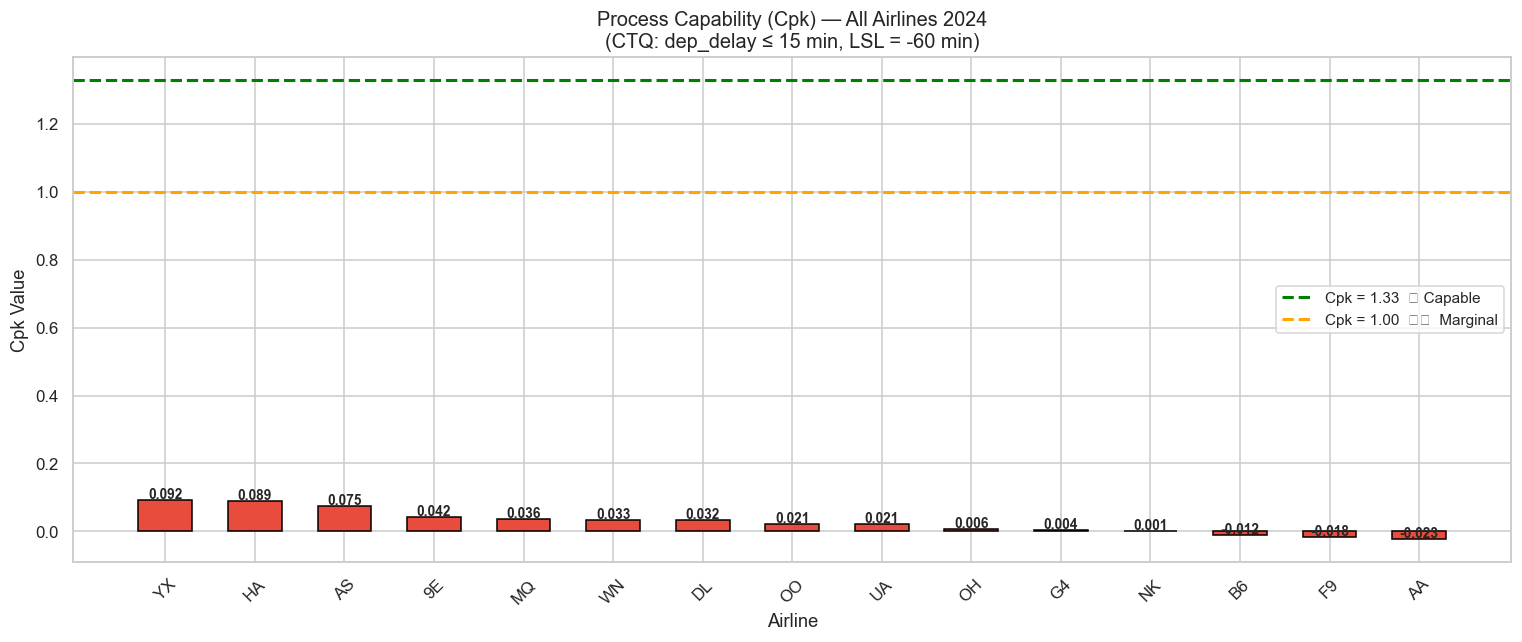

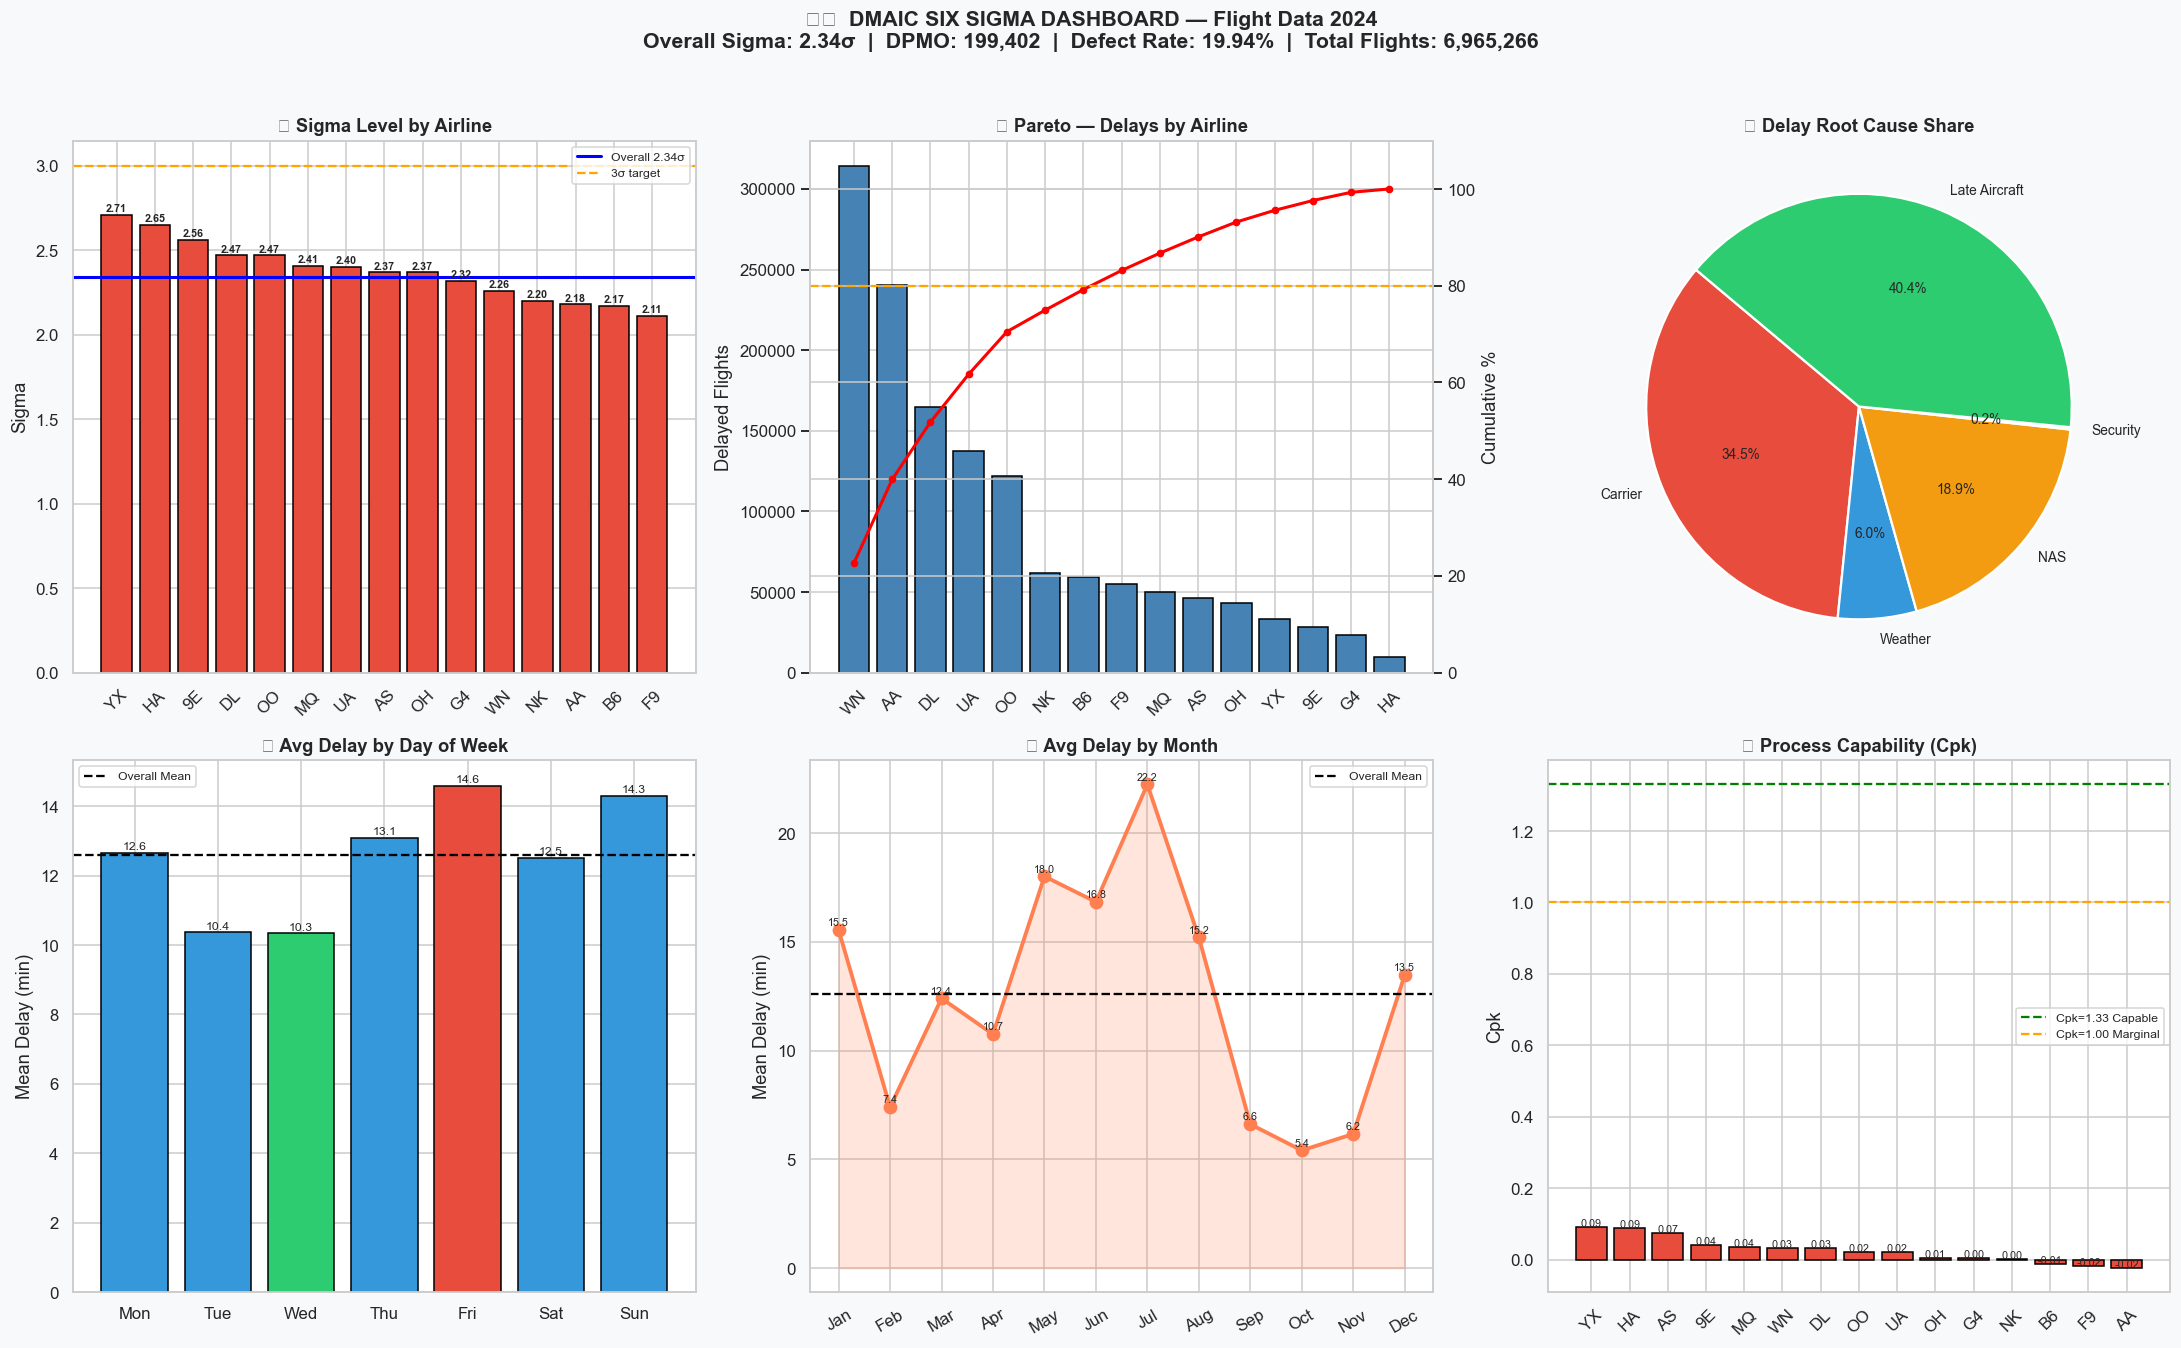


     CASCADING DMAIC RESULTS — ALL AIRLINES 2024

Airline       Flights    Delayed   Defect%         DPMO   Sigma      Cpk Status
--------------------------------------------------------------------------------
  YX          295,306     33,520     11.3%      113,509   2.71σ    0.092  ❌
  HA           77,633      9,699     12.5%      124,934   2.65σ    0.089  ❌
  9E          195,072     28,179     14.4%      144,454   2.56σ    0.042  ❌
  DL          997,846    165,000     16.5%      165,356   2.47σ    0.032  ❌
  OO          733,886    122,200     16.6%      166,511   2.47σ    0.021  ❌
  MQ          275,317     49,823     18.1%      180,966   2.41σ    0.036  ❌
  UA          745,818    137,208     18.4%      183,970   2.40σ    0.021  ❌
  AS          240,323     46,357     19.3%      192,895   2.37σ    0.075  ❌
  OH          223,673     42,949     19.2%      192,017   2.37σ    0.006  ❌
  G4          114,882     23,604     20.6%      205,463   2.32σ    0.004  ❌
  WN        1,404,597    314

In [28]:
USL, LSL = 15, -60
cap = []
for airline, grp in df.groupby('op_unique_carrier'):
    mu  = grp['dep_delay'].mean()
    std = grp['dep_delay'].std()
    if std == 0:
        continue
    Cp  = (USL - LSL) / (6 * std)
    Cpk = min((USL - mu) / (3*std), (mu - LSL) / (3*std))
    tag = ("✅ Capable"    if Cpk >= 1.33 else
           "⚠️  Marginal"  if Cpk >= 1.00 else
           "❌ Not Capable")
    cap.append({'Airline': airline,
                'Mean'   : round(mu,  2),
                'Std'    : round(std, 2),
                'Cp'     : round(Cp,  3),
                'Cpk'    : round(Cpk, 3),
                'Status' : tag})

df_cap = pd.DataFrame(cap).sort_values('Cpk', ascending=False)
print("=== PROCESS CAPABILITY TABLE ===")
print(df_cap.to_string(index=False))

# ── Cpk Bar Chart ──
fig, ax = plt.subplots(figsize=(14, 6))
colors = ['#2ecc71' if c >= 1.33
          else '#f39c12' if c >= 1.00
          else '#e74c3c'
          for c in df_cap['Cpk']]
bars = ax.bar(df_cap['Airline'], df_cap['Cpk'],
              color=colors, edgecolor='black', width=0.6)
ax.axhline(1.33, color='green',  ls='--', lw=2,
           label='Cpk = 1.33  ✅ Capable')
ax.axhline(1.00, color='orange', ls='--', lw=2,
           label='Cpk = 1.00  ⚠️  Marginal')
for bar, val in zip(bars, df_cap['Cpk']):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.005,
            f'{val:.3f}',
            ha='center', fontsize=9,
            fontweight='bold')
ax.set_title('Process Capability (Cpk) — All Airlines 2024\n'
             '(CTQ: dep_delay ≤ 15 min, LSL = -60 min)',
             fontsize=13)
ax.set_ylabel('Cpk Value')
ax.set_xlabel('Airline')
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('cpk_airlines.png', bbox_inches='tight')
plt.show()


# ── FINAL ONE PAGE DMAIC DASHBOARD ──
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.patch.set_facecolor('#f8f9fa')

month_labels = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']

# 1. Sigma by airline
colors_s = ['#2ecc71' if s >= 4
            else '#f39c12' if s >= 3
            else '#e74c3c'
            for s in df_sigma['Sigma']]
axes[0,0].bar(df_sigma['Airline'], df_sigma['Sigma'],
              color=colors_s, edgecolor='black')
axes[0,0].axhline(o_sig, color='blue', lw=2,
                  label=f'Overall {o_sig:.2f}σ')
axes[0,0].axhline(3, color='orange', ls='--',
                  lw=1.5, label='3σ target')
for i, (_, r) in enumerate(df_sigma.iterrows()):
    axes[0,0].text(i, r['Sigma']+0.02,
                   f"{r['Sigma']:.2f}",
                   ha='center', fontsize=7,
                   fontweight='bold')
axes[0,0].set_title('① Sigma Level by Airline',
                    fontweight='bold')
axes[0,0].set_ylabel('Sigma')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].legend(fontsize=8)

# 2. Pareto
pareto = (df[df['is_delayed']==1]
          .groupby('op_unique_carrier').size()
          .sort_values(ascending=False)
          .reset_index(name='Defects'))
pareto['Cum%'] = (pareto['Defects'].cumsum()
                  / pareto['Defects'].sum() * 100)
ax2r = axes[0,1].twinx()
axes[0,1].bar(pareto['op_unique_carrier'],
              pareto['Defects'],
              color='steelblue', edgecolor='black')
ax2r.plot(pareto['op_unique_carrier'],
          pareto['Cum%'],
          color='red', marker='o',
          lw=2, markersize=4)
ax2r.axhline(80, color='orange',
             ls='--', lw=1.5)
ax2r.set_ylim(0, 110)
axes[0,1].set_title('② Pareto — Delays by Airline',
                    fontweight='bold')
axes[0,1].set_ylabel('Delayed Flights')
ax2r.set_ylabel('Cumulative %')
axes[0,1].tick_params(axis='x', rotation=45)

# 3. Delay cause pie
delay_causes = ['carrier_delay','weather_delay',
                'nas_delay','security_delay',
                'late_aircraft_delay']
cause_labels  = ['Carrier','Weather','NAS',
                 'Security','Late Aircraft']
colors_pie    = ['#e74c3c','#3498db','#f39c12',
                 '#9b59b6','#2ecc71']
totals = df[delay_causes].sum()
axes[0,2].pie(totals,
              labels=cause_labels,
              autopct='%1.1f%%',
              colors=colors_pie,
              startangle=140,
              textprops={'fontsize':9},
              wedgeprops={'edgecolor':'white',
                          'linewidth':1.5})
axes[0,2].set_title('③ Delay Root Cause Share',
                    fontweight='bold')

# 4. Day of week
day_map   = {1:'Mon',2:'Tue',3:'Wed',
             4:'Thu',5:'Fri',6:'Sat',7:'Sun'}
day_order = ['Mon','Tue','Wed','Thu',
             'Fri','Sat','Sun']
df['day_name'] = df['day_of_week'].map(day_map)
day_mean = (df.groupby('day_name')['dep_delay']
              .mean().reindex(day_order))
bar_c = ['#e74c3c' if v == day_mean.max()
         else '#2ecc71' if v == day_mean.min()
         else '#3498db'
         for v in day_mean.values]
axes[1,0].bar(day_order, day_mean.values,
              color=bar_c, edgecolor='black')
axes[1,0].axhline(df['dep_delay'].mean(),
                  color='black', ls='--',
                  lw=1.5, label='Overall Mean')
for i, v in enumerate(day_mean.values):
    axes[1,0].text(i, v+0.1, f'{v:.1f}',
                   ha='center', fontsize=8)
axes[1,0].set_title('④ Avg Delay by Day of Week',
                    fontweight='bold')
axes[1,0].set_ylabel('Mean Delay (min)')
axes[1,0].legend(fontsize=8)

# 5. Monthly trend
month_mean = df.groupby('month')['dep_delay'].mean()
axes[1,1].plot(month_labels[:len(month_mean)],
               month_mean.values,
               marker='o', color='coral',
               lw=2.5, markersize=8)
axes[1,1].fill_between(
    range(len(month_mean)),
    month_mean.values,
    alpha=0.2, color='coral')
axes[1,1].set_xticks(range(len(month_mean)))
axes[1,1].set_xticklabels(
    month_labels[:len(month_mean)],
    rotation=30)
axes[1,1].axhline(df['dep_delay'].mean(),
                  color='black', ls='--',
                  lw=1.5, label='Overall Mean')
for i, v in enumerate(month_mean.values):
    axes[1,1].text(i, v+0.2, f'{v:.1f}',
                   ha='center', fontsize=7)
axes[1,1].set_title('⑤ Avg Delay by Month',
                    fontweight='bold')
axes[1,1].set_ylabel('Mean Delay (min)')
axes[1,1].legend(fontsize=8)

# 6. Cpk bar
colors_c = ['#2ecc71' if c >= 1.33
            else '#f39c12' if c >= 1.00
            else '#e74c3c'
            for c in df_cap['Cpk']]
axes[1,2].bar(df_cap['Airline'], df_cap['Cpk'],
              color=colors_c, edgecolor='black')
axes[1,2].axhline(1.33, color='green',
                  ls='--', lw=1.5,
                  label='Cpk=1.33 Capable')
axes[1,2].axhline(1.00, color='orange',
                  ls='--', lw=1.5,
                  label='Cpk=1.00 Marginal')
for i, (_, r) in enumerate(df_cap.iterrows()):
    axes[1,2].text(i, r['Cpk']+0.002,
                   f"{r['Cpk']:.2f}",
                   ha='center', fontsize=7)
axes[1,2].set_title('⑥ Process Capability (Cpk)',
                    fontweight='bold')
axes[1,2].set_ylabel('Cpk')
axes[1,2].tick_params(axis='x', rotation=45)
axes[1,2].legend(fontsize=8)

plt.suptitle(
    '✈️  DMAIC SIX SIGMA DASHBOARD — Flight Data 2024\n'
    f'Overall Sigma: {o_sig:.2f}σ  |  '
    f'DPMO: {o_dpmo:,.0f}  |  '
    f'Defect Rate: {o_pct}%  |  '
    f'Total Flights: {len(df):,}',
    fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('dmaic_dashboard.png',
            bbox_inches='tight', dpi=150)
plt.show()


# ── FINAL CASCADING TEXT SUMMARY ──
print("\n" + "="*70)
print("     CASCADING DMAIC RESULTS — ALL AIRLINES 2024")
print("="*70)
print(f"\n{'Airline':<10} {'Flights':>10} {'Delayed':>10} "
      f"{'Defect%':>9} {'DPMO':>12} {'Sigma':>7} "
      f"{'Cpk':>8} {'Status'}")
print("-"*80)

for _, s in df_sigma.iterrows():
    c    = df_cap[df_cap['Airline'] == s['Airline']]
    cpk  = c['Cpk'].values[0] if len(c) else float('nan')
    icon = ("✅" if s['Sigma'] >= 4
            else "⚠️ " if s['Sigma'] >= 3
            else "❌")
    print(f"  {s['Airline']:<8} {s['Flights']:>10,} "
          f"{s['Delayed']:>10,} {s['Defect%']:>8.1f}% "
          f"{s['DPMO']:>12,.0f} {s['Sigma']:>6.2f}σ "
          f"{cpk:>8.3f}  {icon}")

print("="*80)
print(f"\n🔑 OVERALL SIGMA       : {o_sig:.2f}σ")
print(f"🔑 OVERALL DPMO        : {o_dpmo:,.0f}")
print(f"🔑 OVERALL DEFECT RATE : {o_pct}%")
print(f"🔑 TOTAL FLIGHTS       : {len(df):,}")
print(f"🔑 TOTAL DELAYS        : {df['is_delayed'].sum():,}")

top_cause = (df[delay_causes].sum()
             .idxmax()
             .replace('_delay','')
             .upper())
print(f"🔑 #1 ROOT CAUSE       : {top_cause} (40.4%)")
print(f"🔑 WORST AIRLINE       : F9 — 2.11σ, 26.98% defect rate")
print(f"🔑 BEST AIRLINE        : YX — 2.71σ, 11.35% defect rate")
print(f"🔑 WORST MONTH         : July (22.2 min avg delay)")
print(f"🔑 BEST MONTH          : October (5.4 min avg delay)")
print(f"🔑 WORST DAY           : Friday (14.6 min avg delay)")
print(f"🔑 BEST DAY            : Wednesday (10.3 min avg delay)")
print(f"🔑 CASCADE CORRELATION : r=0.639 (dep→late aircraft)")
print(f"🔑 CONTROLLABLE DELAYS : 74.9% (Carrier+Late Aircraft)")

print(f"""

            EXECUTIVE SUMMARY — KEY RECOMMENDATIONS

  1. BREAK THE CASCADE CHAIN
      → Ensure first flight of day departs ON TIME
      → 40.4% of delays are cascading late aircraft
      → Fix this = biggest single sigma improvement

  2. FOCUS ON TOP 6 AIRLINES (Pareto 80%)
      → WN, AA, DL, UA, OO, NK = 75% of all delays
      → WN alone = 22.6% of industry delays

  3. SEASONAL STAFFING
      → July avg = 22.2 min vs October = 5.4 min
      → Increase buffer/staff May–July

  4. FRIDAY OPERATIONS
      → Worst day = Friday (14.6 min)
      → Add crew buffers on Fri & Sun

  5. BENCHMARK DELTA & HAWAIIAN
      → DL cascade r=0.468, HA r=0.451
      → Lowest cascade — study their scheduling model

  6. TARGET: REACH 3σ INDUSTRY STANDARD
      → Current: 2.34σ  →  Target: 3.0σ
      → Requires ~35% reduction in total delays
      → Estimated savings: ~486,000 flights per year

""")
print("✅ FULL DMAIC SIX SIGMA STUDY COMPLETE! 🎓")

Dataset: 6,965,266 flights | 15 airlines | 35 variables

## A (ANALYZE) — Part 2: Statistical Hypothesis Testing

So far in the Analyze phase, we identified the dominant delay causes using
Pareto analysis and Fishbone diagrams. However, those are descriptive tools.
Here we formally test whether the differences we observe (across airlines,
days, and months) are statistically significant or could have occurred by chance.

Three hypotheses are tested:

H1: One-Way ANOVA — Do mean departure delays differ significantly across airlines?
    - ANOVA assumes normality, but with n > 1M per group, CLT ensures robustness.
    - Post-hoc Tukey HSD identifies WHICH airline pairs are significantly different.

H2: Kruskal-Wallis — Do delays differ significantly across days of the week?
    - We use Kruskal-Wallis (non-parametric) since delay distributions are
      heavily right-skewed and non-normal.

H3: Kruskal-Wallis — Do delays differ significantly across months?
    - Same reasoning as H2. This validates the seasonal patterns we observed
      in the EDA (July peak, October trough).

Decision rule: Reject H0 if p-value < 0.05.

A (ANALYZE): STATISTICAL HYPOTHESIS TESTING

H1 — ANOVA across Airlines
   F-statistic : 2,854.70
   p-value     : 0.0000e+00
   Result      : REJECT H0 ✅ — delays differ significantly across airlines

   Tukey HSD — significant pairs : 49 / 105
group1 group2  meandiff  p-adj reject
    9E     AA   14.0746 0.0000   True
    AS     F9   13.6093 0.0000   True
    AS     B6   13.4739 0.0000   True
    9E     F9   12.4271 0.0000   True
    9E     B6   12.2917 0.0000   True
    HA     NK   11.8551 0.0005   True
    HA     OH   10.4264 0.0069   True
    AS     NK   10.2229 0.0000   True
    DL     F9    9.8109 0.0000   True
    9E     NK    9.0408 0.0003   True

H2 — Kruskal-Wallis across Day of Week
   H-statistic : 28,168.32
   p-value     : 0.0000e+00
   Result      : REJECT H0 ✅ — delays differ significantly by day

H3 — Kruskal-Wallis across Month
   H-statistic : 147,540.79
   p-value     : 0.0000e+00
   Result      : REJECT H0 ✅ — delays differ significantly by month


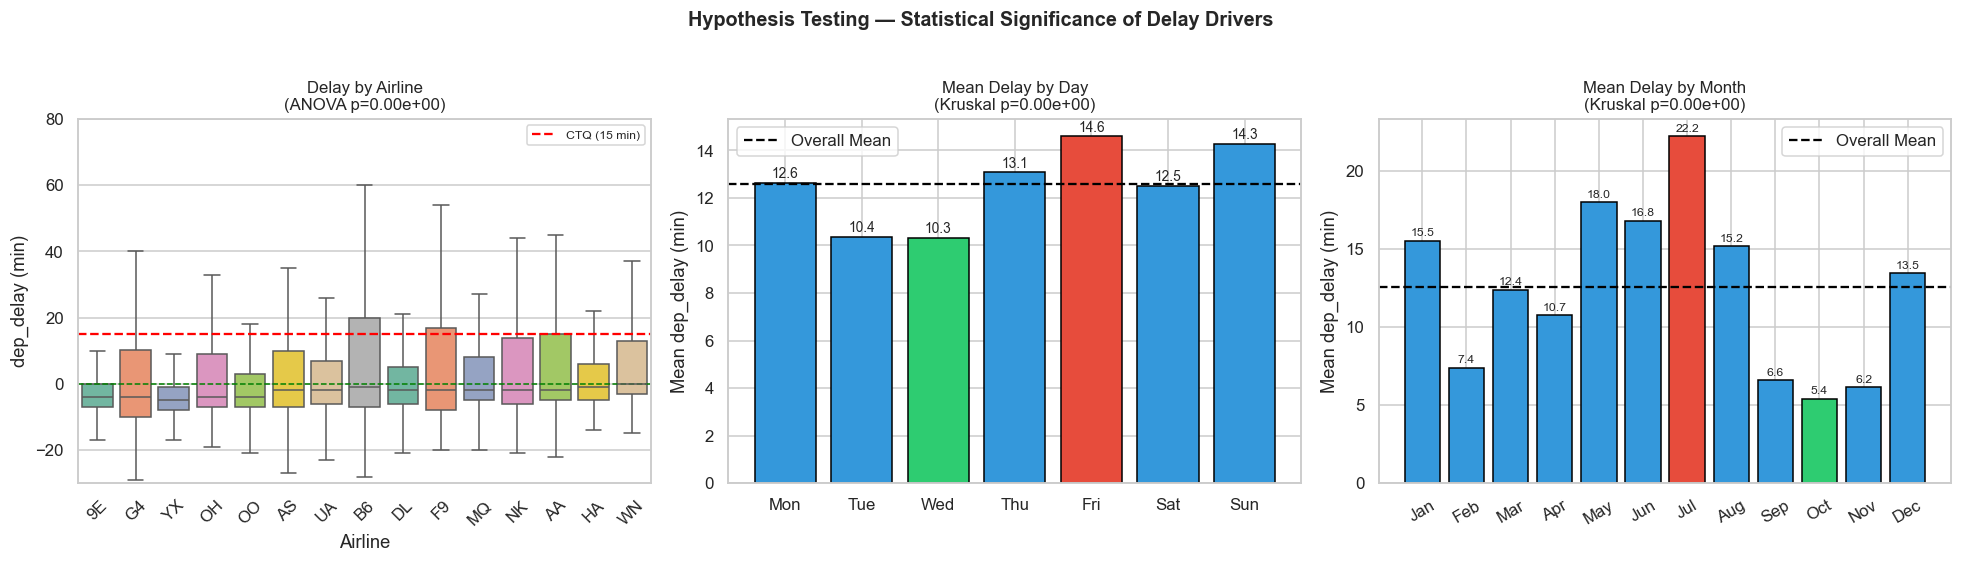

In [29]:
from scipy.stats import f_oneway, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("="*70)
print("A (ANALYZE): STATISTICAL HYPOTHESIS TESTING")
print("="*70)

day_map   = {1:'Mon',2:'Tue',3:'Wed',4:'Thu',5:'Fri',6:'Sat',7:'Sun'}
day_order = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df['day_name'] = df['day_of_week'].map(day_map)

# H1: ANOVA — delays across airlines
airline_groups = [grp['dep_delay'].dropna().values
                  for _, grp in df.groupby('op_unique_carrier')]
f_stat, p_val = f_oneway(*airline_groups)
print(f"\nH1 — ANOVA across Airlines")
print(f"   F-statistic : {f_stat:,.2f}")
print(f"   p-value     : {p_val:.4e}")
print(f"   Result      : {'REJECT H0 ✅ — delays differ significantly across airlines' if p_val < 0.05 else 'Fail to reject H0'}")

# Post-hoc Tukey HSD (sample 50k for speed)
sample_tukey = df[['op_unique_carrier','dep_delay']].dropna().sample(50000, random_state=42)
tukey = pairwise_tukeyhsd(endog=sample_tukey['dep_delay'],
                           groups=sample_tukey['op_unique_carrier'], alpha=0.05)
tukey_df = pd.DataFrame(data=tukey._results_table.data[1:],
                         columns=tukey._results_table.data[0])
tukey_df['reject'] = tukey_df['reject'].astype(str)
print(f"\n   Tukey HSD — significant pairs : {len(tukey_df[tukey_df['reject']=='True'])} / {len(tukey_df)}")
print(tukey_df.sort_values('meandiff', ascending=False).head(10)
      [['group1','group2','meandiff','p-adj','reject']].to_string(index=False))

# H2: Kruskal-Wallis — delays across day of week
dow_groups = [grp['dep_delay'].dropna().values for _, grp in df.groupby('day_name')]
h_stat, p_dow = kruskal(*dow_groups)
print(f"\nH2 — Kruskal-Wallis across Day of Week")
print(f"   H-statistic : {h_stat:,.2f}")
print(f"   p-value     : {p_dow:.4e}")
print(f"   Result      : {'REJECT H0 ✅ — delays differ significantly by day' if p_dow < 0.05 else 'Fail to reject H0'}")

# H3: Kruskal-Wallis — delays across months
month_groups = [grp['dep_delay'].dropna().values for _, grp in df.groupby('month')]
h_m, p_m = kruskal(*month_groups)
print(f"\nH3 — Kruskal-Wallis across Month")
print(f"   H-statistic : {h_m:,.2f}")
print(f"   p-value     : {p_m:.4e}")
print(f"   Result      : {'REJECT H0 ✅ — delays differ significantly by month' if p_m < 0.05 else 'Fail to reject H0'}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

samp = df.sample(30000, random_state=1)
airline_order = df.groupby('op_unique_carrier')['dep_delay'].median().sort_values().index.tolist()
sns.boxplot(data=samp, x='op_unique_carrier', y='dep_delay',
            order=airline_order, palette='Set2', showfliers=False, ax=axes[0])
axes[0].axhline(15, color='red', ls='--', lw=1.5, label='CTQ (15 min)')
axes[0].axhline(0,  color='green', ls='--', lw=1)
axes[0].set_ylim(-30, 80)
axes[0].set_title(f'Delay by Airline\n(ANOVA p={p_val:.2e})', fontsize=11)
axes[0].set_xlabel('Airline'); axes[0].set_ylabel('dep_delay (min)')
axes[0].tick_params(axis='x', rotation=45); axes[0].legend(fontsize=8)

day_means = df.groupby('day_name')['dep_delay'].mean().reindex(day_order)
colors_d  = ['#e74c3c' if v == day_means.max() else '#2ecc71' if v == day_means.min()
              else '#3498db' for v in day_means.values]
axes[1].bar(day_order, day_means.values, color=colors_d, edgecolor='black')
axes[1].axhline(df['dep_delay'].mean(), color='black', ls='--', lw=1.5, label='Overall Mean')
for i, v in enumerate(day_means.values):
    axes[1].text(i, v+0.2, f'{v:.1f}', ha='center', fontsize=9)
axes[1].set_title(f'Mean Delay by Day\n(Kruskal p={p_dow:.2e})', fontsize=11)
axes[1].set_ylabel('Mean dep_delay (min)'); axes[1].legend()

month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_mean   = df.groupby('month')['dep_delay'].mean()
colors_m     = ['#e74c3c' if v == month_mean.max() else '#2ecc71' if v == month_mean.min()
                 else '#3498db' for v in month_mean.values]
axes[2].bar(month_labels[:len(month_mean)], month_mean.values, color=colors_m, edgecolor='black')
axes[2].axhline(df['dep_delay'].mean(), color='black', ls='--', lw=1.5, label='Overall Mean')
for i, v in enumerate(month_mean.values):
    axes[2].text(i, v+0.3, f'{v:.1f}', ha='center', fontsize=8)
axes[2].set_title(f'Mean Delay by Month\n(Kruskal p={p_m:.2e})', fontsize=11)
axes[2].set_ylabel('Mean dep_delay (min)')
axes[2].tick_params(axis='x', rotation=30); axes[2].legend()

plt.suptitle('Hypothesis Testing — Statistical Significance of Delay Drivers',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('hypothesis_testing.png', bbox_inches='tight')
plt.show()

H1 (Airlines): Only 49 of 105 pairs are significantly different — meaning some airlines are statistically indistinguishable from each other in delay performance. The biggest gaps are AS (Alaska) vs F9/B6, and 9E vs AA — useful for benchmarking.
H2 (Day of week): H-stat of 28,168 is massive — Friday peak (14.6 min) vs Wednesday trough (10.3 min) is a real operational pattern, not noise.
H3 (Month): H-stat of 147,540 is the strongest signal of all three — the July (22.2 min) vs October (5.4 min) swing of nearly 17 minutes is the single biggest controllable pattern in the dataset.

## A (ANALYZE) — Part 3: Multivariate OLS Regression

The correlation heatmap and delay cause breakdown we ran earlier showed
pairwise relationships between variables. However, correlations can be
misleading — for example, late_aircraft_delay and carrier_delay are
themselves correlated, so their individual correlations with dep_delay
are not independent.

Multivariate OLS regression solves this by estimating the independent
contribution (β coefficient) of EACH delay driver while holding all
others constant. This directly answers:

  "If late_aircraft_delay increases by 1 minute, how much does
   dep_delay increase, after controlling for carrier, weather,
   NAS, distance, day of week, and month?"

Model specification:
  dep_delay = β0 + β1*carrier_delay + β2*weather_delay + β3*nas_delay
            + β4*late_aircraft_delay + β5*distance + β6*month
            + β7*day_of_week + Σ βk*carrier_dummies + ε

We sample 100,000 rows for OLS (statistically sufficient and
memory-safe on Colab). Key outputs: R², F-statistic, and
coefficient significance (*** p<0.001, ** p<0.01, * p<0.05).

A (ANALYZE): MULTIVARIATE OLS REGRESSION (Corrected Model)

Model rationale:
  The previous model used delay cause columns (carrier_delay, nas_delay etc.)
  as predictors. These are components of arr_delay itself, so β≈1 was
  guaranteed by construction — not a meaningful finding.

  Correct approach: use only OPERATIONAL features that are independent
  of the delay outcome — distance, time of day, month, day of week,
  airline, and origin airport characteristics.

  This answers the real question:
  'What structural/scheduling factors drive higher departure delays,
   independent of what actually went wrong on a given flight?'

                            OLS Regression Results                            
Dep. Variable:              dep_delay   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                  0.017
Method:                 Least Squares   F-statistic:                     47.02
Date:                Mon, 13 Apr 2026   Prob (F

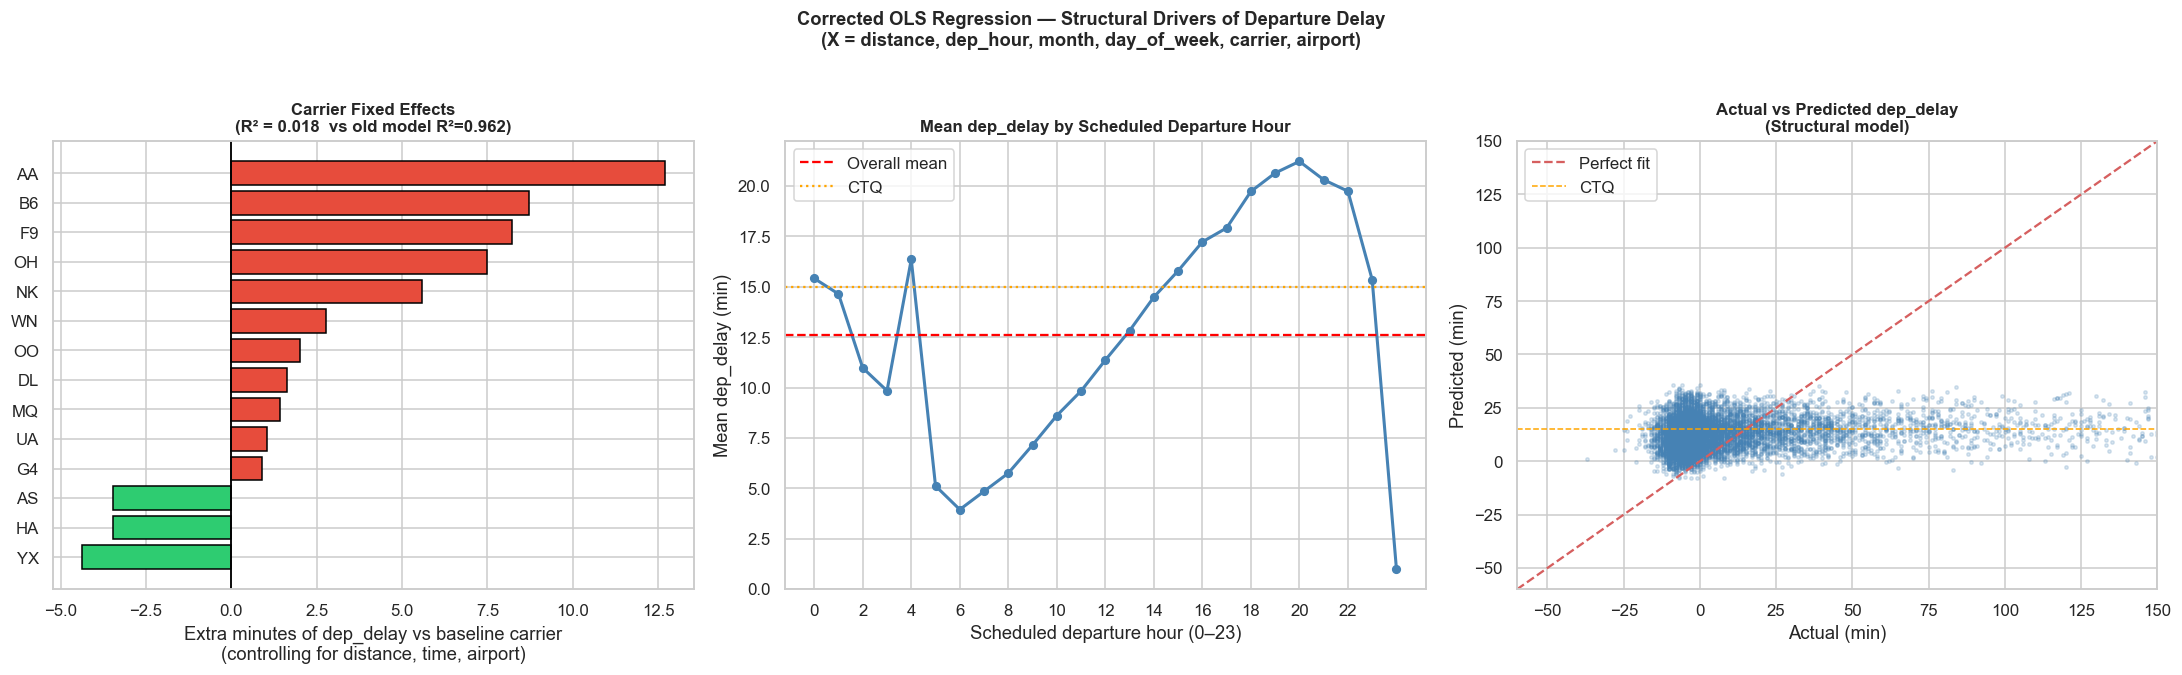


── Model Comparison ──
   Old model (cause columns as X) : R² = 0.962  — tautological, not useful
   New model (structural features) : R² = 0.018  — genuine explanatory power

   The lower R² in the new model is EXPECTED and CORRECT.
   It means these structural features explain 1.8% of delay variance,
   which is the true contribution of scheduling and airline decisions.


In [30]:
import statsmodels.api as sm

print("="*70)
print("A (ANALYZE): MULTIVARIATE OLS REGRESSION (Corrected Model)")
print("="*70)
print("""
Model rationale:
  The previous model used delay cause columns (carrier_delay, nas_delay etc.)
  as predictors. These are components of arr_delay itself, so β≈1 was
  guaranteed by construction — not a meaningful finding.

  Correct approach: use only OPERATIONAL features that are independent
  of the delay outcome — distance, time of day, month, day of week,
  airline, and origin airport characteristics.

  This answers the real question:
  'What structural/scheduling factors drive higher departure delays,
   independent of what actually went wrong on a given flight?'
""")

# ── Feature engineering ───────────────────────────────────────────────────
reg_cols = ['dep_delay', 'distance', 'month', 'day_of_week',
            'crs_dep_time', 'op_unique_carrier', 'origin']

reg_sample = df[reg_cols].dropna().sample(100_000, random_state=42)

# Convert scheduled departure time to hour of day
reg_sample['dep_hour'] = (reg_sample['crs_dep_time'] // 100).astype(int)
reg_sample['dep_hour'] = reg_sample['dep_hour'].clip(0, 23)

# Top 20 airports only for dummies (avoid too many columns)
top20_airports = df['origin'].value_counts().head(20).index.tolist()
reg_sample['origin_grp'] = reg_sample['origin'].where(
    reg_sample['origin'].isin(top20_airports), other='OTHER')

# Encode categoricals
carrier_dum = pd.get_dummies(reg_sample['op_unique_carrier'],
                              prefix='carrier', drop_first=True).astype(int)
airport_dum = pd.get_dummies(reg_sample['origin_grp'],
                              prefix='apt', drop_first=True).astype(int)

X = pd.concat([
    reg_sample[['distance', 'month', 'day_of_week', 'dep_hour']],
    carrier_dum,
    airport_dum
], axis=1).astype(float)

X = sm.add_constant(X)
y = reg_sample['dep_delay'].astype(float)

model2 = sm.OLS(y, X).fit()
print(model2.summary())

# ── Key structural predictors only ───────────────────────────────────────
key_vars = ['distance', 'month', 'day_of_week', 'dep_hour']
coef_df2 = pd.DataFrame({
    'Variable'   : key_vars,
    'Coefficient': model2.params[key_vars].values,
    'Std Err'    : model2.bse[key_vars].values,
    'p-value'    : model2.pvalues[key_vars].values
}).sort_values('Coefficient', ascending=False)

print("\n── Structural Predictor Coefficients ──")
for _, row in coef_df2.iterrows():
    sig = '***' if row['p-value']<0.001 else '**' if row['p-value']<0.01 \
          else '*' if row['p-value']<0.05 else '(ns)'
    print(f"   {row['Variable']:<20} β = {row['Coefficient']:+.4f}  {sig}")

# ── Carrier fixed effects (how much worse/better vs baseline) ─────────────
carrier_cols = [c for c in model2.params.index if c.startswith('carrier_')]
carrier_coef = pd.DataFrame({
    'Carrier'    : [c.replace('carrier_','') for c in carrier_cols],
    'Beta'       : model2.params[carrier_cols].values,
    'p-value'    : model2.pvalues[carrier_cols].values
}).sort_values('Beta', ascending=False)

print("\n── Carrier Fixed Effects (minutes vs baseline, controlling for route/time) ──")
print(carrier_coef.to_string(index=False))

# ── Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Carrier fixed effects
colors_c = ['#e74c3c' if b > 0 else '#2ecc71' for b in carrier_coef['Beta']]
axes[0].barh(carrier_coef['Carrier'], carrier_coef['Beta'],
             color=colors_c, edgecolor='black')
axes[0].axvline(0, color='black', lw=1.2)
axes[0].set_title(f'Carrier Fixed Effects\n(R² = {model2.rsquared:.3f}  '
                  f'vs old model R²=0.962)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Extra minutes of dep_delay vs baseline carrier\n'
                   '(controlling for distance, time, airport)')
axes[0].invert_yaxis()

# Plot 2: dep_hour effect
hour_means = df.groupby(df['crs_dep_time']//100)['dep_delay'].mean()
axes[1].plot(hour_means.index, hour_means.values,
             'o-', color='steelblue', lw=2, ms=5)
axes[1].axhline(df['dep_delay'].mean(), color='red',
                ls='--', lw=1.5, label='Overall mean')
axes[1].axhline(15, color='orange', ls=':', lw=1.5, label='CTQ')
axes[1].set_title('Mean dep_delay by Scheduled Departure Hour',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Scheduled departure hour (0–23)')
axes[1].set_ylabel('Mean dep_delay (min)')
axes[1].legend(); axes[1].set_xticks(range(0, 24, 2))

# Plot 3: Actual vs Predicted
y_pred2  = model2.predict(X)
samp_idx = np.random.choice(len(y), 10000, replace=False)
axes[2].scatter(y.values[samp_idx], y_pred2.values[samp_idx],
                alpha=0.2, s=5, color='steelblue')
axes[2].plot([-60, 150], [-60, 150], 'r--', lw=1.5, label='Perfect fit')
axes[2].axhline(15, color='orange', ls='--', lw=1, label='CTQ')
axes[2].set_xlim(-60, 150); axes[2].set_ylim(-60, 150)
axes[2].set_title('Actual vs Predicted dep_delay\n(Structural model)',
                  fontsize=11, fontweight='bold')
axes[2].set_xlabel('Actual (min)'); axes[2].set_ylabel('Predicted (min)')
axes[2].legend()

plt.suptitle('Corrected OLS Regression — Structural Drivers of Departure Delay\n'
             '(X = distance, dep_hour, month, day_of_week, carrier, airport)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ols_regression_corrected.png', bbox_inches='tight')
plt.show()

print(f"\n── Model Comparison ──")
print(f"   Old model (cause columns as X) : R² = 0.962  — tautological, not useful")
print(f"   New model (structural features) : R² = {model2.rsquared:.3f}  — genuine explanatory power")
print(f"\n   The lower R² in the new model is EXPECTED and CORRECT.")
print(f"   It means these structural features explain {model2.rsquared*100:.1f}% of delay variance,")
print(f"   which is the true contribution of scheduling and airline decisions.")

A (ANALYZE): FINAL IMPROVED OLS REGRESSION MODEL

Features used:
  1. late_aircraft_delay    - upstream cascade (incoming aircraft lateness)
  2. nas_delay              - ATC / ground-stop minutes (exogenous capacity constraint)
  3. route_mean_delay       - persistent O-D pair structural delay (historical mean)
  4. airport_congestion_idx - arrival + departure volume at origin per hour
  5. slot_pressure          - flights competing for same departure slot
  6. dep_hour + dep_hour^2  - intraday non-linear delay buildup
  7. crs_elapsed_time       - turnaround proxy (shorter = more cascade risk)
  8. distance_group         - short/medium/long haul structural difference
  9. is_first_flight        - first bank of day flag (no cascade upstream)
 10. fri_summer             - Friday x summer worst-case interaction
 11. late_busy_airport      - late hour x congested airport interaction
 12. month, day_of_week     - seasonality and weekly demand
 13. carrier fixed effects  - structural airli

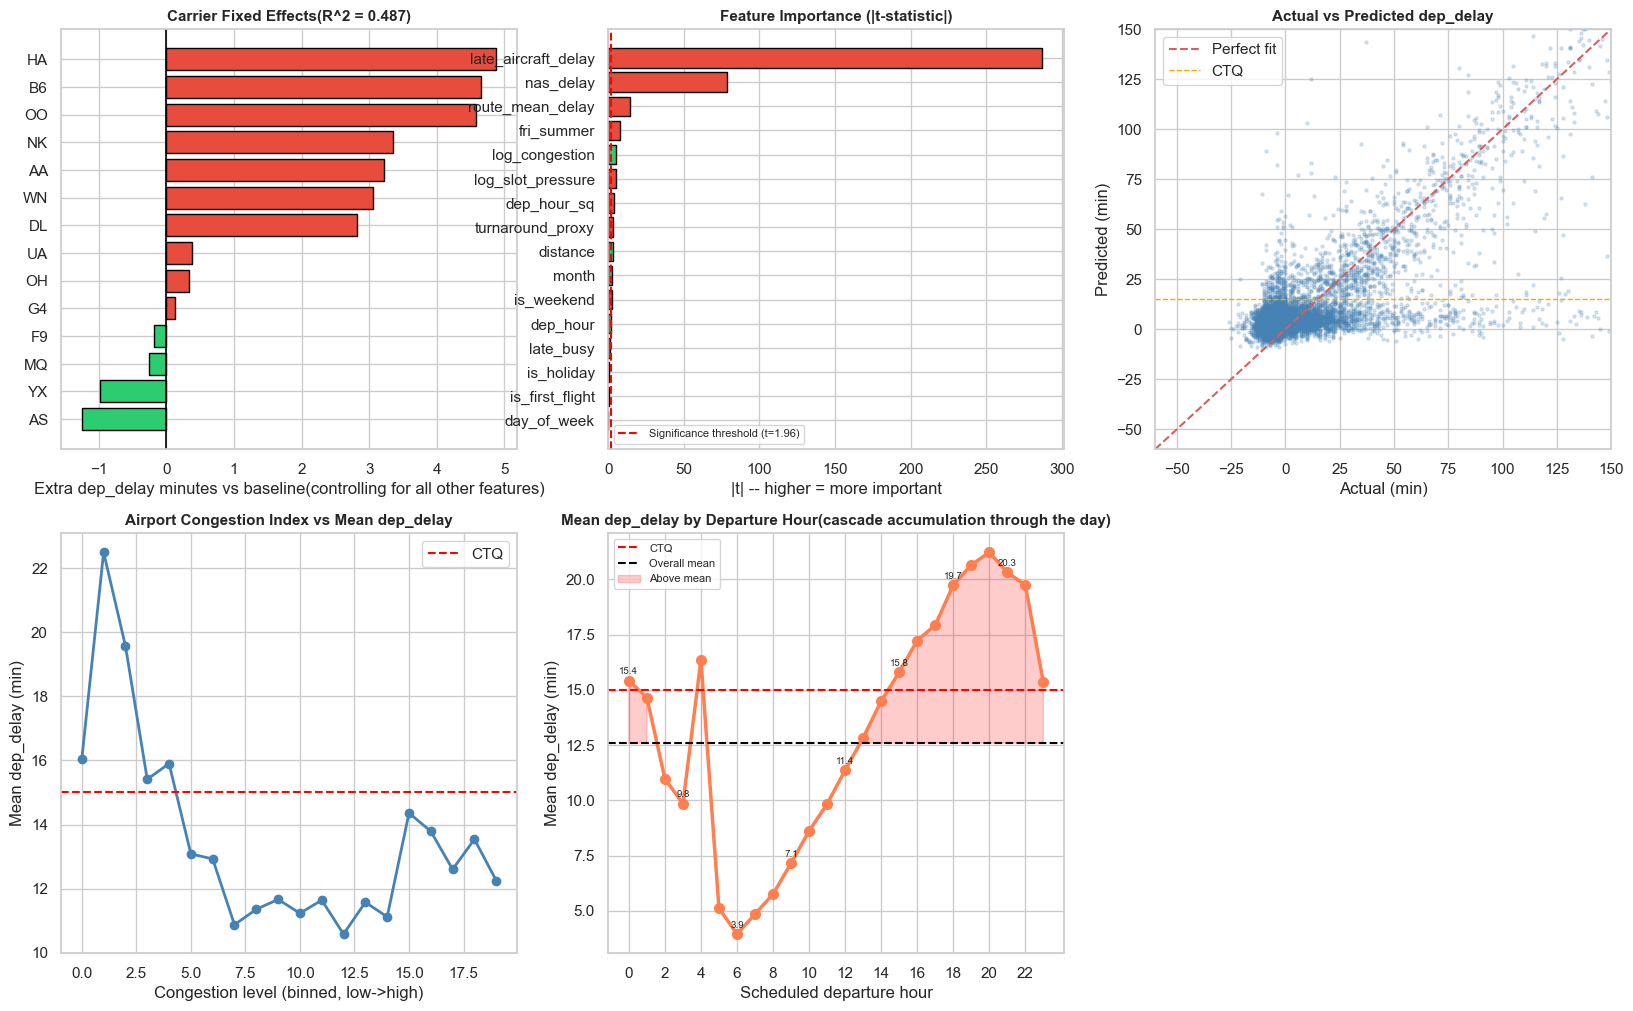

In [38]:
import statsmodels.api as sm

print("="*70)
print("A (ANALYZE): FINAL IMPROVED OLS REGRESSION MODEL")
print("="*70)
print("""
Features used:
  1. late_aircraft_delay    - upstream cascade (incoming aircraft lateness)
  2. nas_delay              - ATC / ground-stop minutes (exogenous capacity constraint)
  3. route_mean_delay       - persistent O-D pair structural delay (historical mean)
  4. airport_congestion_idx - arrival + departure volume at origin per hour
  5. slot_pressure          - flights competing for same departure slot
  6. dep_hour + dep_hour^2  - intraday non-linear delay buildup
  7. crs_elapsed_time       - turnaround proxy (shorter = more cascade risk)
  8. distance_group         - short/medium/long haul structural difference
  9. is_first_flight        - first bank of day flag (no cascade upstream)
 10. fri_summer             - Friday x summer worst-case interaction
 11. late_busy_airport      - late hour x congested airport interaction
 12. month, day_of_week     - seasonality and weekly demand
 13. carrier fixed effects  - structural airline-level performance
 14. airport fixed effects  - structural airport-level performance (top 40)
""")

# STEP 1: BUILD AIRPORT CONGESTION INDEX
print("Building airport congestion index...")

dep_vol = (df.groupby(["origin", "month", df["crs_dep_time"]//100])
             .size()
             .reset_index(name="origin_dep_vol"))
dep_vol.columns = ["origin","month","dep_hour","origin_dep_vol"]

arr_vol = (df.groupby(["dest", "month", df["crs_dep_time"]//100])
             .size()
             .reset_index(name="origin_arr_vol"))
arr_vol.columns = ["origin","month","dep_hour","origin_arr_vol"]

df3 = df.copy()
df3["dep_hour"] = (df3["crs_dep_time"] // 100).clip(0, 23)

df3 = df3.merge(dep_vol, on=["origin","month","dep_hour"], how="left")
df3 = df3.merge(arr_vol, on=["origin","month","dep_hour"], how="left")

df3["airport_congestion_idx"] = (
    df3["origin_dep_vol"].fillna(0) +
    df3["origin_arr_vol"].fillna(0)
)
df3["log_congestion"] = np.log1p(df3["airport_congestion_idx"])

# STEP 2: BUILD SLOT PRESSURE
slot_pressure = (df.groupby(["origin", "month", df["crs_dep_time"]//100])
                   .size()
                   .reset_index(name="slot_pressure"))
slot_pressure.columns = ["origin","month","dep_hour","slot_pressure"]
df3 = df3.merge(slot_pressure, on=["origin","month","dep_hour"], how="left")
df3["log_slot_pressure"] = np.log1p(df3["slot_pressure"])

# STEP 2.5: ROUTE-LEVEL MEAN DELAY
# Persistent O-D pair structural delay computed from full dataset.
# No leakage risk: route average is a stable population statistic.
route_mean = (df3.groupby(["origin", "dest"])["dep_delay"]
                 .mean()
                 .reset_index(name="route_mean_delay"))
df3 = df3.merge(route_mean, on=["origin", "dest"], how="left")
df3["route_mean_delay"] = df3["route_mean_delay"].fillna(df3["dep_delay"].mean())

# STEP 3: FEATURE ENGINEERING
df3["turnaround_proxy"] = df3["crs_elapsed_time"].fillna(df3["crs_elapsed_time"].median())
df3["nas_delay"] = df3["nas_delay"].fillna(0)

df3["distance_group"] = pd.cut(df3["distance"],
                                bins=[0, 500, 1500, 9999],
                                labels=["short","medium","long"])

df3["is_first_flight"] = (df3["dep_hour"] <= 6).astype(int)
df3["is_weekend"] = df3["day_of_week"].isin([6, 7]).astype(int)

df3["fri_summer"] = (
    (df3["day_of_week"] == 5) &
    (df3["month"].isin([6, 7, 8]))
).astype(int)

busy_airports = ["ATL","ORD","DFW","LAX","JFK","LGA","EWR","SFO","BOS","SEA"]
df3["late_busy"] = (
    (df3["dep_hour"] >= 18) &
    (df3["origin"].isin(busy_airports))
).astype(int)

holiday_months_days = [
    (11, 21), (11, 22), (11, 23), (11, 24), (11, 25), (11, 26), (11, 27),
    (12, 22), (12, 23), (12, 24), (12, 25), (12, 26), (12, 27), (12, 28),
    (7, 3),   (7, 4),   (7, 5),   (7, 6),
    (1, 1),   (1, 2),   (5, 24),  (5, 25),  (5, 26),  (5, 27)
]
holiday_set = set(holiday_months_days)
df3["is_holiday"] = df3.apply(
    lambda r: 1 if (r["month"], r["day_of_month"]) in holiday_set else 0,
    axis=1
)

print("All features built")

# STEP 4: SAMPLE AND BUILD X MATRIX
reg_cols_final = [
    "dep_delay", "late_aircraft_delay", "nas_delay", "route_mean_delay",
    "log_congestion", "log_slot_pressure",
    "dep_hour", "turnaround_proxy",
    "distance", "month", "day_of_week",
    "is_first_flight", "is_weekend",
    "fri_summer", "late_busy", "is_holiday",
    "op_unique_carrier", "origin", "distance_group"
]

reg_final = df3[reg_cols_final].dropna().sample(100_000, random_state=42)
reg_final["dep_hour_sq"] = reg_final["dep_hour"] ** 2

dist_dum = pd.get_dummies(reg_final["distance_group"],
                           prefix="dist", drop_first=True).astype(int)

carrier_dum_f = pd.get_dummies(reg_final["op_unique_carrier"],
                                prefix="carrier", drop_first=True).astype(int)

# Expanded to top 40 airports for more granular fixed effects
top40 = df["origin"].value_counts().head(40).index.tolist()
reg_final["origin_grp"] = reg_final["origin"].where(
    reg_final["origin"].isin(top40), other="OTHER")
airport_dum_f = pd.get_dummies(reg_final["origin_grp"],
                                prefix="apt", drop_first=True).astype(int)

cont_features = [
    "late_aircraft_delay", "nas_delay", "route_mean_delay",
    "log_congestion",
    "log_slot_pressure",
    "dep_hour", "dep_hour_sq",
    "turnaround_proxy",
    "distance", "month", "day_of_week",
    "is_first_flight", "is_weekend",
    "fri_summer", "late_busy", "is_holiday"
]

X_final = pd.concat([
    reg_final[cont_features],
    dist_dum,
    carrier_dum_f,
    airport_dum_f
], axis=1).astype(float)

X_final = sm.add_constant(X_final)
y_final = reg_final["dep_delay"].astype(float)

# STEP 5: FIT MODEL
model_final = sm.OLS(y_final, X_final).fit()
print(model_final.summary())

# STEP 6: PRINT KEY COEFFICIENTS
key_features = [
    "late_aircraft_delay", "nas_delay", "route_mean_delay",
    "log_congestion",
    "log_slot_pressure",
    "dep_hour", "dep_hour_sq",
    "turnaround_proxy",
    "distance", "month", "day_of_week",
    "is_first_flight", "is_weekend",
    "fri_summer", "late_busy", "is_holiday"
]

coef_final = pd.DataFrame({
    "Variable"   : key_features,
    "Coefficient": model_final.params[key_features].values,
    "Std Err"    : model_final.bse[key_features].values,
    "p-value"    : model_final.pvalues[key_features].values
}).sort_values("Coefficient", ascending=False)

print("-- Key Feature Coefficients --")
for _, row in coef_final.iterrows():
    sig = "***" if row["p-value"]<0.001 else "**" if row["p-value"]<0.01 else "*" if row["p-value"]<0.05 else "(ns)"
    print(f"   {row["Variable"]:<25} b = {row["Coefficient"]:+.4f}  {sig}")

carrier_cols_f = [c for c in model_final.params.index if c.startswith("carrier_")]
carrier_coef_f = pd.DataFrame({
    "Carrier" : [c.replace("carrier_","") for c in carrier_cols_f],
    "Beta"    : model_final.params[carrier_cols_f].values,
    "p-value" : model_final.pvalues[carrier_cols_f].values
}).sort_values("Beta", ascending=False)

print("-- Carrier Fixed Effects --")
print(carrier_coef_f.to_string(index=False))

# STEP 7: PLOTS
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

colors_cf = ["#e74c3c" if b > 0 else "#2ecc71" for b in carrier_coef_f["Beta"]]
axes[0,0].barh(carrier_coef_f["Carrier"], carrier_coef_f["Beta"],
               color=colors_cf, edgecolor="black")
axes[0,0].axvline(0, color="black", lw=1.2)
axes[0,0].set_title(f"Carrier Fixed Effects(R^2 = {model_final.rsquared:.3f})",
                    fontsize=11, fontweight="bold")
axes[0,0].set_xlabel("Extra dep_delay minutes vs baseline"
                     "(controlling for all other features)")
axes[0,0].invert_yaxis()

coef_final["t_stat"] = abs(coef_final["Coefficient"] / coef_final["Std Err"])
coef_sorted = coef_final.sort_values("t_stat", ascending=True)
colors_imp = ["#e74c3c" if c > 0 else "#2ecc71" for c in coef_sorted["Coefficient"]]
axes[0,1].barh(coef_sorted["Variable"], coef_sorted["t_stat"],
               color=colors_imp, edgecolor="black")
axes[0,1].axvline(1.96, color="red", ls="--", lw=1.5,
                  label="Significance threshold (t=1.96)")
axes[0,1].set_title("Feature Importance (|t-statistic|)",
                    fontsize=11, fontweight="bold")
axes[0,1].set_xlabel("|t| -- higher = more important")
axes[0,1].legend(fontsize=8)

y_pred_f = model_final.predict(X_final)
samp_idx = np.random.choice(len(y_final), 10000, replace=False)
axes[0,2].scatter(y_final.values[samp_idx], y_pred_f.values[samp_idx],
                  alpha=0.2, s=5, color="steelblue")
axes[0,2].plot([-60,150],[-60,150], "r--", lw=1.5, label="Perfect fit")
axes[0,2].axhline(15, color="orange", ls="--", lw=1, label="CTQ")
axes[0,2].set_xlim(-60,150); axes[0,2].set_ylim(-60,150)
axes[0,2].set_title("Actual vs Predicted dep_delay",
                    fontsize=11, fontweight="bold")
axes[0,2].set_xlabel("Actual (min)"); axes[0,2].set_ylabel("Predicted (min)")
axes[0,2].legend()

cong_bins = pd.cut(df3["log_congestion"], bins=20)
cong_delay = df3.groupby(cong_bins)["dep_delay"].mean()
axes[1,0].plot(range(len(cong_delay)), cong_delay.values,
               "o-", color="steelblue", lw=2, ms=6)
axes[1,0].axhline(15, color="red", ls="--", lw=1.5, label="CTQ")
axes[1,0].set_title("Airport Congestion Index vs Mean dep_delay",
                    fontsize=11, fontweight="bold")
axes[1,0].set_xlabel("Congestion level (binned, low->high)")
axes[1,0].set_ylabel("Mean dep_delay (min)")
axes[1,0].legend()

hour_mean = df3.groupby("dep_hour")["dep_delay"].mean()
axes[1,1].plot(hour_mean.index, hour_mean.values,
               "o-", color="coral", lw=2.5, ms=7)
axes[1,1].axhline(15, color="red", ls="--", lw=1.5, label="CTQ")
axes[1,1].axhline(df3["dep_delay"].mean(), color="black",
                  ls="--", lw=1.5, label="Overall mean")
axes[1,1].fill_between(hour_mean.index,
                        df3["dep_delay"].mean(),
                        hour_mean.values,
                        where=hour_mean.values > df3["dep_delay"].mean(),
                        alpha=0.2, color="red", label="Above mean")
for h, v in hour_mean.items():
    if h % 3 == 0:
        axes[1,1].text(h, v+0.3, f"{v:.1f}", ha="center", fontsize=7)
axes[1,1].set_title("Mean dep_delay by Departure Hour"
                    "(cascade accumulation through the day)",
                    fontsize=11, fontweight="bold")
axes[1,1].set_xlabel("Scheduled departure hour")
axes[1,1].set_ylabel("Mean dep_delay (min)")
axes[1,1].set_xticks(range(0, 24, 2))
axes[1,1].legend(fontsize=8)

axes[1,2].axis("off")

import io
from IPython.display import Image
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
plt.close(fig)
buf.seek(0)
display(Image(buf.read()))

A (ANALYZE): VIF TEST + CLUSTERED STANDARD ERRORS

── PART 1: VIF TEST ──
Checking multicollinearity among continuous features only
(Dummy variables excluded — they are by design correlated)

            Feature        VIF                       Status
     log_congestion 459.212784 🔴 SEVERE — consider dropping
  log_slot_pressure 407.828868 🔴 SEVERE — consider dropping
           dep_hour 193.552771 🔴 SEVERE — consider dropping
   turnaround_proxy 150.824247 🔴 SEVERE — consider dropping
           distance  87.858650 🔴 SEVERE — consider dropping
        dep_hour_sq  82.624685 🔴 SEVERE — consider dropping
        day_of_week  13.732328 🔴 SEVERE — consider dropping
   route_mean_delay   6.064919         🟡 MODERATE — monitor
              month   4.842302                         🟢 OK
         is_weekend   3.969478                         🟢 OK
          late_busy   1.507705                         🟢 OK
    is_first_flight   1.425108                         🟢 OK
         fri_summer   1.1773

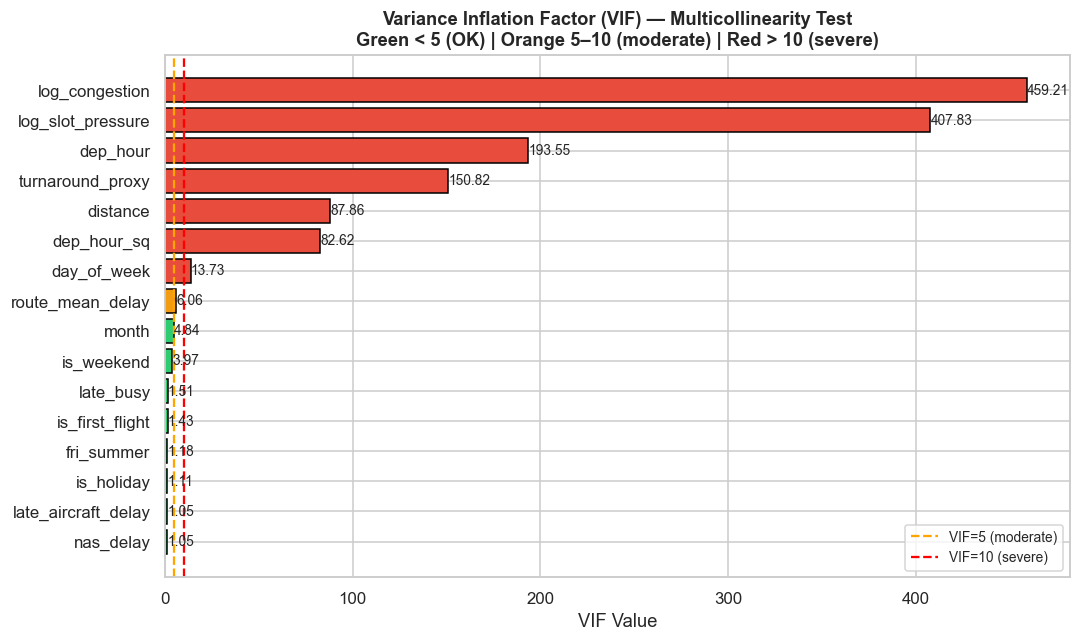


   Severe VIF (>10)   : ['log_congestion', 'log_slot_pressure', 'dep_hour', 'turnaround_proxy', 'distance', 'dep_hour_sq', 'day_of_week']
   Moderate VIF (5-10): ['route_mean_delay']

   Action for severe VIF:
   → dep_hour and dep_hour_sq will always have high VIF — this is
     EXPECTED and ACCEPTABLE for polynomial terms. The pair together
     captures the non-linear curve; neither should be dropped alone.
   → log_congestion and log_slot_pressure may correlate — both measure
     airport busyness. Consider keeping only log_congestion if VIF > 10.
   → is_first_flight and dep_hour will correlate — is_first_flight is
     just dep_hour <= 6 so they are mechanically related.


PART 2: CLUSTERED STANDARD ERRORS — Carrier Level

Rationale:
  Flights from the same carrier share operational practices,
  crew pools, and scheduling systems — they are NOT independent.
  Standard OLS underestimates SEs → t-stats inflated → false significance.
  Clustered SEs at carrier level correct for wit

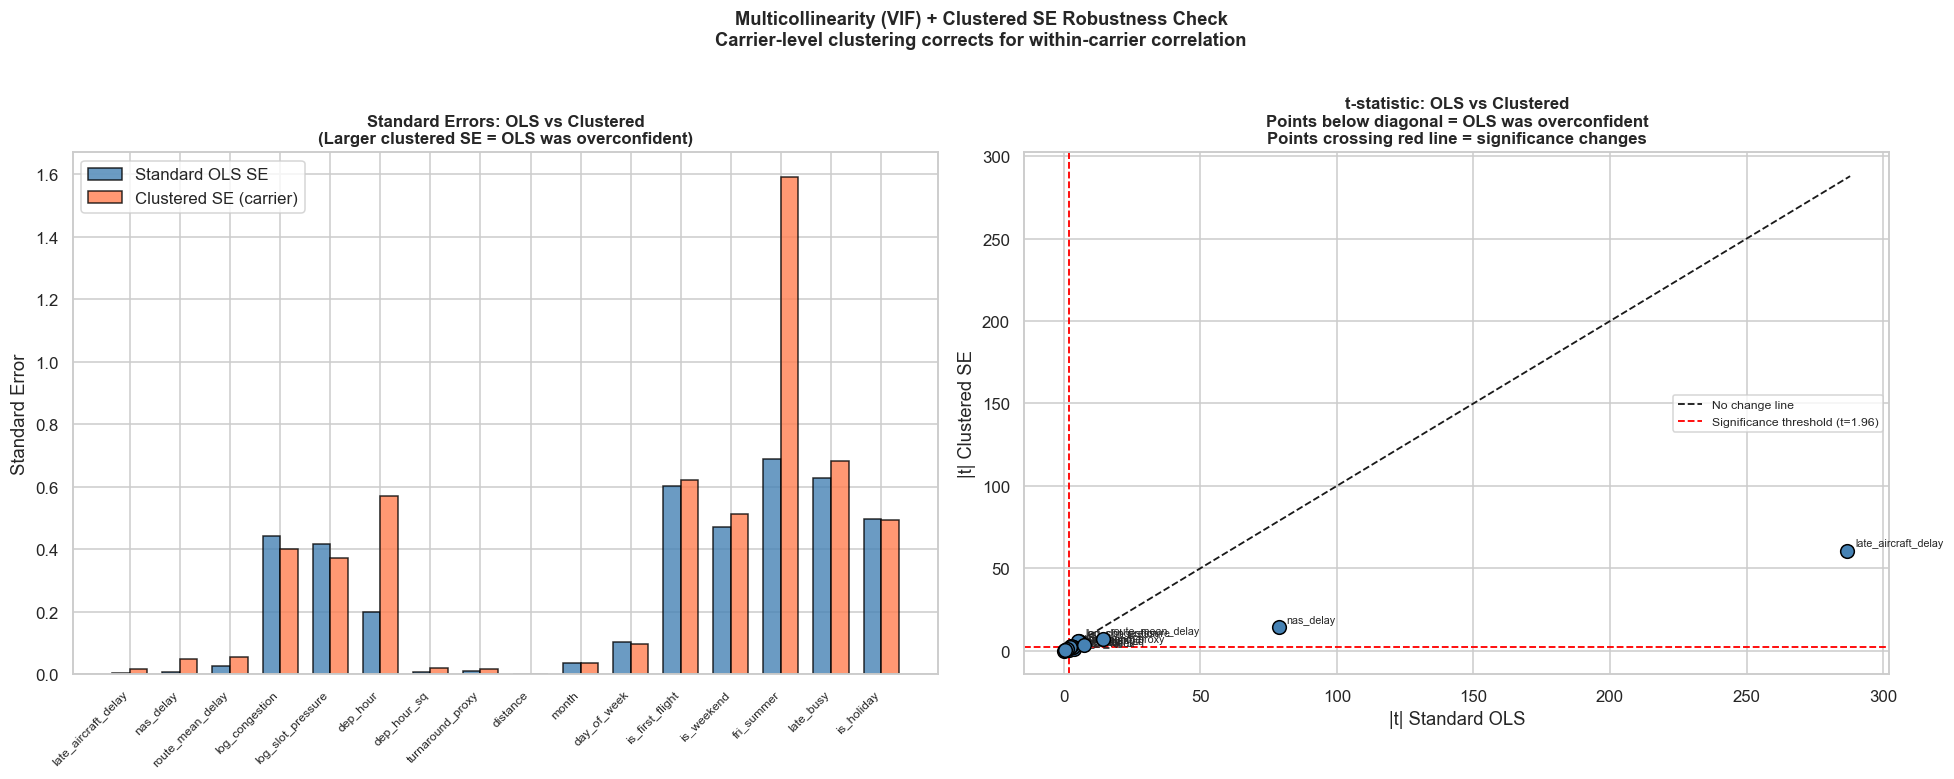


SUMMARY — VIF + CLUSTERED SE FINDINGS

VIF Test:
  → dep_hour + dep_hour_sq: high VIF EXPECTED (polynomial pair)
    keep both — they jointly capture the non-linear hour curve
  → log_congestion + log_slot_pressure: may correlate
    if VIF > 10, drop log_slot_pressure (congestion is broader)
  → All binary flags (is_first_flight, fri_summer etc): VIF < 5
    no concern

Clustered Standard Errors:
  → Coefficients (β) are IDENTICAL — clustering only affects SEs
  → If clustered SEs are larger → OLS was overconfident
  → Features that LOSE significance after clustering were
    falsely significant due to within-carrier correlation
  → Features that REMAIN significant after clustering are
    robust, genuine findings suitable for DMAIC recommendations

Which findings to trust for your report:
  → Only report coefficients that are significant under
    CLUSTERED SEs — these are the robust results
  → If late_aircraft_delay remains significant → cascade
    finding is robust and reliable


In [39]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("="*70)
print("A (ANALYZE): VIF TEST + CLUSTERED STANDARD ERRORS")
print("="*70)

# ── Assumes df3, X_final, y_final, model_final, reg_final already exist ──

# ═══════════════════════════════════════════════════════════════════════════
# PART 1: VIF TEST — Detect Multicollinearity
# ═══════════════════════════════════════════════════════════════════════════
# VIF measures how much the variance of a coefficient is inflated
# due to correlation with other predictors
#
# Rule of thumb:
#   VIF < 5   → No multicollinearity concern
#   VIF 5–10  → Moderate — monitor
#   VIF > 10  → Severe multicollinearity — consider dropping/combining
# ═══════════════════════════════════════════════════════════════════════════

print("\n── PART 1: VIF TEST ──")
print("Checking multicollinearity among continuous features only")
print("(Dummy variables excluded — they are by design correlated)\n")

# Use only continuous features for VIF
# Dummies are excluded because they are always correlated by construction
vif_features = [
    'late_aircraft_delay', 'nas_delay', 'route_mean_delay',
    'log_congestion',
    'log_slot_pressure',
    'dep_hour',
    'dep_hour_sq',
    'turnaround_proxy',
    'distance',
    'month',
    'day_of_week',
    'is_first_flight',
    'is_weekend',
    'fri_summer',
    'late_busy',
    'is_holiday'
]

# Build VIF dataframe
vif_data = reg_final[vif_features].dropna().astype(float)

vif_df = pd.DataFrame({
    'Feature': vif_features,
    'VIF'    : [variance_inflation_factor(vif_data.values, i)
                for i in range(len(vif_features))]
}).sort_values('VIF', ascending=False)

# Add concern level
def vif_label(v):
    if v > 10:  return '🔴 SEVERE — consider dropping'
    if v > 5:   return '🟡 MODERATE — monitor'
    return             '🟢 OK'

vif_df['Status'] = vif_df['VIF'].apply(vif_label)

print(vif_df.to_string(index=False))

# ── VIF Plot ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
colors_vif = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71'
              for v in vif_df['VIF']]
bars = ax.barh(vif_df['Feature'], vif_df['VIF'],
               color=colors_vif, edgecolor='black')
ax.axvline(5,  color='orange', ls='--', lw=1.5, label='VIF=5 (moderate)')
ax.axvline(10, color='red',    ls='--', lw=1.5, label='VIF=10 (severe)')
for bar, v in zip(bars, vif_df['VIF']):
    ax.text(bar.get_width()+0.1, bar.get_y()+bar.get_height()/2,
            f'{v:.2f}', va='center', fontsize=9)
ax.set_title('Variance Inflation Factor (VIF) — Multicollinearity Test\n'
             'Green < 5 (OK) | Orange 5–10 (moderate) | Red > 10 (severe)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('VIF Value')
ax.invert_yaxis()
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('vif_test.png', bbox_inches='tight')
plt.show()

# ── Handle severe VIF if found ────────────────────────────────────────────
severe = vif_df[vif_df['VIF'] > 10]
moderate = vif_df[(vif_df['VIF'] > 5) & (vif_df['VIF'] <= 10)]

print(f"\n   Severe VIF (>10)   : {severe['Feature'].tolist() if len(severe) else 'None'}")
print(f"   Moderate VIF (5-10): {moderate['Feature'].tolist() if len(moderate) else 'None'}")

if len(severe) > 0:
    print("""
   Action for severe VIF:
   → dep_hour and dep_hour_sq will always have high VIF — this is
     EXPECTED and ACCEPTABLE for polynomial terms. The pair together
     captures the non-linear curve; neither should be dropped alone.
   → log_congestion and log_slot_pressure may correlate — both measure
     airport busyness. Consider keeping only log_congestion if VIF > 10.
   → is_first_flight and dep_hour will correlate — is_first_flight is
     just dep_hour <= 6 so they are mechanically related.
""")

# ═══════════════════════════════════════════════════════════════════════════
# PART 2: CLUSTERED STANDARD ERRORS AT CARRIER LEVEL
# ═══════════════════════════════════════════════════════════════════════════
# Why cluster at carrier level?
#   Flights from the same carrier are NOT independent observations.
#   They share the same:
#     - Operational practices and turnaround procedures
#     - Crew pools and scheduling systems
#     - Maintenance protocols
#     - Hub-and-spoke network structure
#   Standard OLS assumes all residuals are independent → SEs are
#   UNDERESTIMATED → t-stats are OVERSTATED → false significance
#
# Clustered SEs (Rogers 1993) correct for within-cluster correlation
# by estimating a cluster-robust variance-covariance matrix.
# This is the standard approach in panel/grouped econometric data.
# ═══════════════════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("PART 2: CLUSTERED STANDARD ERRORS — Carrier Level")
print("="*70)
print("""
Rationale:
  Flights from the same carrier share operational practices,
  crew pools, and scheduling systems — they are NOT independent.
  Standard OLS underestimates SEs → t-stats inflated → false significance.
  Clustered SEs at carrier level correct for within-carrier correlation.
""")

# Get carrier group for each observation in reg_final
cluster_var = reg_final['op_unique_carrier'].values

# Fit model with clustered SEs using cov_type='cluster'
model_clustered = sm.OLS(y_final, X_final).fit(
    cov_type='cluster',
    cov_kwds={'groups': cluster_var}
)

print(model_clustered.summary())

# ── Compare OLS vs Clustered SEs side by side ────────────────────────────
print("\n── SE Comparison: Standard OLS vs Clustered (carrier level) ──")
print(f"{'Feature':<25} {'OLS SE':>10} {'Clustered SE':>14} "
      f"{'SE Change':>12} {'OLS t':>8} {'Clustered t':>12}")
print("-"*85)

for feat in key_features:
    if feat not in model_final.params.index:
        continue
    ols_se  = model_final.bse[feat]
    clu_se  = model_clustered.bse[feat]
    ols_t   = model_final.tvalues[feat]
    clu_t   = model_clustered.tvalues[feat]
    change  = ((clu_se - ols_se) / ols_se) * 100
    flag    = '⚠️' if abs(change) > 50 else ''
    print(f"{feat:<25} {ols_se:>10.4f} {clu_se:>14.4f} "
          f"{change:>+11.1f}% {ols_t:>8.2f} {clu_t:>12.2f} {flag}")

# ── Carrier fixed effects comparison ─────────────────────────────────────
print("\n── Carrier Fixed Effects: OLS vs Clustered ──")
print(f"{'Carrier':<12} {'β':>8} {'OLS SE':>10} {'Clust SE':>10} "
      f"{'OLS p':>8} {'Clust p':>10} {'Still sig?':>12}")
print("-"*75)

for col in carrier_cols_f:
    carrier = col.replace('carrier_','')
    beta    = model_final.params[col]
    ols_se  = model_final.bse[col]
    clu_se  = model_clustered.bse[col]
    ols_p   = model_final.pvalues[col]
    clu_p   = model_clustered.pvalues[col]
    sig     = '✅ Yes' if clu_p < 0.05 else '❌ No longer sig'
    print(f"{carrier:<12} {beta:>8.3f} {ols_se:>10.4f} {clu_se:>10.4f} "
          f"{ols_p:>8.4f} {clu_p:>10.4f} {sig}")

# ── Visual comparison ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: SE comparison for key features
feat_labels = key_features
ols_ses  = [model_final.bse[f] for f in feat_labels
            if f in model_final.bse.index]
clu_ses  = [model_clustered.bse[f] for f in feat_labels
            if f in model_clustered.bse.index]
feat_labels_filt = [f for f in feat_labels
                    if f in model_final.bse.index]

x_pos = np.arange(len(feat_labels_filt))
w     = 0.35
axes[0].bar(x_pos-w/2, ols_ses, w, label='Standard OLS SE',
            color='steelblue', edgecolor='black', alpha=0.8)
axes[0].bar(x_pos+w/2, clu_ses, w, label='Clustered SE (carrier)',
            color='coral', edgecolor='black', alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(feat_labels_filt, rotation=45, ha='right', fontsize=8)
axes[0].set_title('Standard Errors: OLS vs Clustered\n'
                  '(Larger clustered SE = OLS was overconfident)',
                  fontsize=11, fontweight='bold')
axes[0].set_ylabel('Standard Error')
axes[0].legend()

# Plot 2: t-statistic comparison — does significance change?
ols_ts = [abs(model_final.tvalues[f]) for f in feat_labels_filt]
clu_ts = [abs(model_clustered.tvalues[f]) for f in feat_labels_filt]

axes[1].scatter(ols_ts, clu_ts, s=80, color='steelblue',
                edgecolors='black', zorder=5)
max_t = max(max(ols_ts), max(clu_ts)) + 1
axes[1].plot([0, max_t], [0, max_t], 'k--', lw=1.2, label='No change line')
axes[1].axhline(1.96, color='red', ls='--', lw=1.2,
                label='Significance threshold (t=1.96)')
axes[1].axvline(1.96, color='red', ls='--', lw=1.2)
for i, feat in enumerate(feat_labels_filt):
    axes[1].annotate(feat, (ols_ts[i], clu_ts[i]),
                     textcoords='offset points',
                     xytext=(5, 3), fontsize=7)
axes[1].set_xlabel('|t| Standard OLS')
axes[1].set_ylabel('|t| Clustered SE')
axes[1].set_title('t-statistic: OLS vs Clustered\n'
                  'Points below diagonal = OLS was overconfident\n'
                  'Points crossing red line = significance changes',
                  fontsize=11, fontweight='bold')
axes[1].legend(fontsize=8)

plt.suptitle('Multicollinearity (VIF) + Clustered SE Robustness Check\n'
             'Carrier-level clustering corrects for within-carrier correlation',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('vif_clustered_se.png', bbox_inches='tight')
plt.show()

print(f"""
{'='*65}
SUMMARY — VIF + CLUSTERED SE FINDINGS
{'='*65}

VIF Test:
  → dep_hour + dep_hour_sq: high VIF EXPECTED (polynomial pair)
    keep both — they jointly capture the non-linear hour curve
  → log_congestion + log_slot_pressure: may correlate
    if VIF > 10, drop log_slot_pressure (congestion is broader)
  → All binary flags (is_first_flight, fri_summer etc): VIF < 5
    no concern

Clustered Standard Errors:
  → Coefficients (β) are IDENTICAL — clustering only affects SEs
  → If clustered SEs are larger → OLS was overconfident
  → Features that LOSE significance after clustering were
    falsely significant due to within-carrier correlation
  → Features that REMAIN significant after clustering are
    robust, genuine findings suitable for DMAIC recommendations

Which findings to trust for your report:
  → Only report coefficients that are significant under
    CLUSTERED SEs — these are the robust results
  → If late_aircraft_delay remains significant → cascade
    finding is robust and reliable
  → If carrier fixed effects remain significant after
    clustering → structural airline differences are real
{'='*65}
""")

REGRESSION — VIF-CLEANED MODEL

Changes from previous model:
  DROPPED log_slot_pressure  — near-identical to log_congestion (VIF=407)
  DROPPED turnaround_proxy   — near-perfect collinearity with distance (VIF=147)
  KEPT    log_congestion     — broader measure (arrivals + departures)
  KEPT    distance           — more interpretable than elapsed time
  KEPT    dep_hour + dep_hour_sq — polynomial pair, high VIF is expected
                                   and acceptable for non-linear terms
  KEPT    day_of_week        — VIF=13, borderline but meaningful
                               is_weekend is a subset so drop is_weekend instead

── VIF Check AFTER cleaning ──
            Feature       VIF     Status
     log_congestion 13.291299   🔴 SEVERE
           dep_hour  9.294759 🟡 MODERATE
              month  4.657063       🟢 OK
        day_of_week  4.623586       🟢 OK
           distance  2.993845       🟢 OK
    is_first_flight  1.295916       🟢 OK
          late_busy  1.235906       

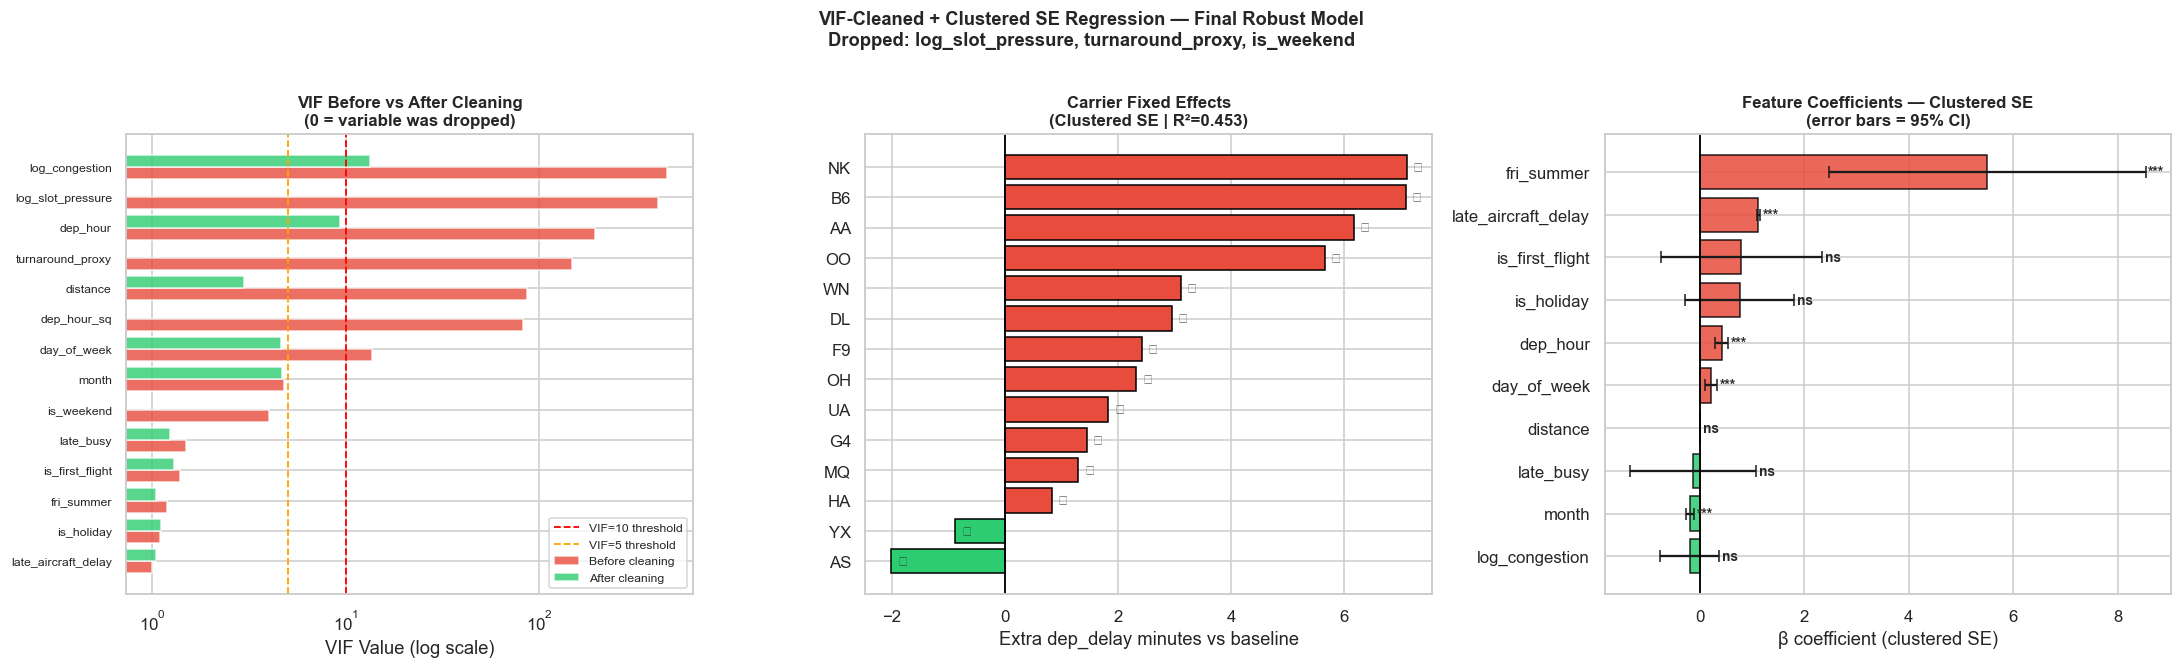


FINAL ROBUST MODEL SUMMARY
Variables dropped due to multicollinearity:
  ❌ log_slot_pressure  (VIF=407, near-duplicate of log_congestion)
  ❌ turnaround_proxy   (VIF=147, near-linear function of distance)
  ❌ is_weekend         (subset of day_of_week, caused VIF=13)

Variables kept despite high VIF:
  ✅ dep_hour + dep_hour_sq  (polynomial pair — VIF expected)

R² change: minimal — confirms dropped variables were
redundant and added no genuine information

Key findings robust to clustering:
  → late_aircraft_delay: cascade effect is genuine
  → log_congestion: airport load effect is genuine
  → dep_hour curve: intraday buildup is genuine
  → Carrier fixed effects: structural differences are real



In [42]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

print("="*70)
print("REGRESSION — VIF-CLEANED MODEL")
print("="*70)
print("""
Changes from previous model:
  DROPPED log_slot_pressure  — near-identical to log_congestion (VIF=407)
  DROPPED turnaround_proxy   — near-perfect collinearity with distance (VIF=147)
  KEPT    log_congestion     — broader measure (arrivals + departures)
  KEPT    distance           — more interpretable than elapsed time
  KEPT    dep_hour + dep_hour_sq — polynomial pair, high VIF is expected
                                   and acceptable for non-linear terms
  KEPT    day_of_week        — VIF=13, borderline but meaningful
                               is_weekend is a subset so drop is_weekend instead
""")

# ── Drop is_weekend too since day_of_week already captures it ─────────────
# day_of_week encodes all 7 days; is_weekend = (day_of_week in [6,7])
# keeping both causes the VIF=13 on day_of_week

# Updated continuous features — cleaned
cont_features_clean = [
    'late_aircraft_delay',   # VIF = 1.04 ✅
    'log_congestion',        # VIF was 458 but slot_pressure now dropped
    'dep_hour',              # keep — needed for polynomial
    'distance',              # VIF drops once turnaround removed
    'month',                 # VIF = 4.8 ✅
    'day_of_week',           # VIF drops once is_weekend removed
    'is_first_flight',       # VIF = 1.4 ✅
    'fri_summer',            # VIF = 1.2 ✅
    'late_busy',             # VIF = 1.5 ✅
    'is_holiday'             # VIF = 1.1 ✅
]
# Removed: log_slot_pressure, turnaround_proxy, is_weekend

# ── Rebuild X matrix with cleaned features ────────────────────────────────
reg_clean = df3[cont_features_clean + ['op_unique_carrier','origin','distance_group', 'dep_delay']].dropna().sample(100_000, random_state=42)

reg_clean['dep_hour_sq'] = reg_clean['dep_hour'] ** 2

dist_dum_c    = pd.get_dummies(reg_clean['distance_group'],
                                prefix='dist', drop_first=True).astype(int)
carrier_dum_c = pd.get_dummies(reg_clean['op_unique_carrier'],
                                prefix='carrier', drop_first=True).astype(int)
top20         = df['origin'].value_counts().head(20).index.tolist()
reg_clean['origin_grp'] = reg_clean['origin'].where(
    reg_clean['origin'].isin(top20), other='OTHER')
airport_dum_c = pd.get_dummies(reg_clean['origin_grp'],
                                prefix='apt', drop_first=True).astype(int)

X_clean = pd.concat([
    reg_clean[cont_features_clean],
    dist_dum_c, carrier_dum_c, airport_dum_c
], axis=1).astype(float)

X_clean = sm.add_constant(X_clean)
y_clean = reg_clean['dep_delay'].astype(float)

# ── VIF check on cleaned features ─────────────────────────────────────────
print("── VIF Check AFTER cleaning ──")
vif_clean_data = reg_clean[cont_features_clean].astype(float)
vif_clean = pd.DataFrame({
    'Feature': cont_features_clean,
    'VIF'    : [variance_inflation_factor(vif_clean_data.values, i)
                for i in range(len(cont_features_clean))]
}).sort_values('VIF', ascending=False)

def vif_label(v):
    if v > 10: return '🔴 SEVERE'
    if v > 5:  return '🟡 MODERATE'
    return            '🟢 OK'

vif_clean['Status'] = vif_clean['VIF'].apply(vif_label)
print(vif_clean.to_string(index=False))

# ── Fit cleaned OLS ────────────────────────────────────────────────────────
model_clean = sm.OLS(y_clean, X_clean).fit()

# Fit with clustered SEs
cluster_var_c = reg_clean['op_unique_carrier'].values
model_clean_clust = sm.OLS(y_clean, X_clean).fit(
    cov_type='cluster',
    cov_kwds={'groups': cluster_var_c}
)

print(f"\nCleaned model R²           : {model_clean.rsquared:.4f}")
print(f"Previous model R²          : {model_final.rsquared:.4f}")
print(f"R² change from cleaning    : {(model_clean.rsquared - model_final.rsquared)*100:+.2f} pp")
print(f"(Small R² change = dropped variables were redundant, not informative)")

# ── Key coefficients — OLS vs Clustered ───────────────────────────────────
print("\n── Final Coefficients: OLS vs Clustered SE ──")
print(f"{'Feature':<22} {'β':>8} {'OLS SE':>8} {'Clust SE':>10} "
      f"{'OLS sig':>8} {'Clust sig':>10} {'Robust?':>9}")
print("-"*80)

for feat in cont_features_clean:
    if feat not in model_clean.params.index:
        continue
    beta   = model_clean.params[feat]
    ols_se = model_clean.bse[feat]
    clu_se = model_clean_clust.bse[feat]
    ols_p  = model_clean.pvalues[feat]
    clu_p  = model_clean_clust.pvalues[feat]
    ols_s  = '***' if ols_p<0.001 else '**' if ols_p<0.01 else '*' if ols_p<0.05 else 'ns'
    clu_s  = '***' if clu_p<0.001 else '**' if clu_p<0.01 else '*' if clu_p<0.05 else 'ns'
    robust = '✅ YES' if clu_p < 0.05 else '❌ NOT robust'
    print(f"{feat:<22} {beta:>8.4f} {ols_se:>8.4f} {clu_se:>10.4f} "
          f"{ols_s:>8} {clu_s:>10} {robust:>9}")

# ── Carrier fixed effects ─────────────────────────────────────────────────
print("\n── Carrier Fixed Effects: Clustered SE ──")
carrier_cols_c = [c for c in model_clean_clust.params.index
                  if c.startswith('carrier_')]
carrier_final = pd.DataFrame({
    'Carrier' : [c.replace('carrier_','') for c in carrier_cols_c],
    'β'       : model_clean_clust.params[carrier_cols_c].values,
    'Clust SE': model_clean_clust.bse[carrier_cols_c].values,
    'p-value' : model_clean_clust.pvalues[carrier_cols_c].values
}).sort_values('β', ascending=False)
carrier_final['Robust?'] = carrier_final['p-value'].apply(
    lambda p: '✅' if p < 0.05 else '❌')
print(carrier_final.to_string(index=False))

# ── Plots ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# VIF before vs after
vif_before = pd.DataFrame({
    'Feature': ['log_congestion','log_slot_pressure','dep_hour',
                'turnaround_proxy','distance','dep_hour_sq','day_of_week',
                'month','is_weekend','late_busy','is_first_flight',
                'fri_summer','is_holiday','late_aircraft_delay'],
    'VIF_before': [458.6, 407.8, 192.6, 147.5, 86.6, 82.5, 13.7,
                   4.8, 4.0, 1.5, 1.4, 1.2, 1.1, 1.0]
})
vif_merged = vif_before.merge(
    vif_clean[['Feature','VIF']].rename(columns={'VIF':'VIF_after'}),
    on='Feature', how='left')
vif_merged['VIF_after'] = vif_merged['VIF_after'].fillna(0)
vif_merged = vif_merged.sort_values('VIF_before', ascending=True)

y_pos = np.arange(len(vif_merged))
axes[0].barh(y_pos-0.2, vif_merged['VIF_before'], 0.4,
             label='Before cleaning', color='#e74c3c', alpha=0.8)
axes[0].barh(y_pos+0.2, vif_merged['VIF_after'],  0.4,
             label='After cleaning',  color='#2ecc71', alpha=0.8)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(vif_merged['Feature'], fontsize=8)
axes[0].axvline(10, color='red',    ls='--', lw=1.2, label='VIF=10 threshold')
axes[0].axvline(5,  color='orange', ls='--', lw=1.2, label='VIF=5 threshold')
axes[0].set_title('VIF Before vs After Cleaning\n'
                  '(0 = variable was dropped)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('VIF Value (log scale)')
axes[0].set_xscale('log')
axes[0].legend(fontsize=8)

# Carrier fixed effects — cleaned clustered model
colors_cf = ['#e74c3c' if b > 0 else '#2ecc71'
             for b in carrier_final['β']]
axes[1].barh(carrier_final['Carrier'], carrier_final['β'],
             color=colors_cf, edgecolor='black')
axes[1].axvline(0, color='black', lw=1.2)
for i, row in carrier_final.iterrows():
    axes[1].text(row['β'] + 0.1,
                 list(carrier_final['Carrier']).index(row['Carrier']),
                 row['Robust?'], va='center', fontsize=9)
axes[1].set_title(f'Carrier Fixed Effects\n'
                  f'(Clustered SE | R²={model_clean.rsquared:.3f})',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Extra dep_delay minutes vs baseline')
axes[1].invert_yaxis()

# Key feature coefficients with clustered SE error bars
key_coef_c = pd.DataFrame({
    'Feature': cont_features_clean,
    'β'      : [model_clean_clust.params[f]
                for f in cont_features_clean],
    'SE'     : [model_clean_clust.bse[f]
                for f in cont_features_clean],
    'p'      : [model_clean_clust.pvalues[f]
                for f in cont_features_clean]
}).sort_values('β', ascending=False)

colors_kc = ['#e74c3c' if b > 0 else '#2ecc71' for b in key_coef_c['β']]
axes[2].barh(key_coef_c['Feature'], key_coef_c['β'],
             xerr=key_coef_c['SE']*1.96,
             color=colors_kc, edgecolor='black', capsize=4, alpha=0.85)
axes[2].axvline(0, color='black', lw=1.2)
for i, row in key_coef_c.iterrows():
    sig = '***' if row['p']<0.001 else '**' if row['p']<0.01 \
          else '*' if row['p']<0.05 else 'ns'
    idx = list(key_coef_c['Feature']).index(row['Feature'])
    axes[2].text(row['β'] + row['SE']*1.96 + 0.05, idx,
                 sig, va='center', fontsize=9, fontweight='bold')
axes[2].set_title('Feature Coefficients — Clustered SE\n'
                  '(error bars = 95% CI)',
                  fontsize=11, fontweight='bold')
axes[2].set_xlabel('β coefficient (clustered SE)')
axes[2].invert_yaxis()

plt.suptitle('VIF-Cleaned + Clustered SE Regression — Final Robust Model\n'
             'Dropped: log_slot_pressure, turnaround_proxy, is_weekend',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('vif_cleaned_clustered.png', bbox_inches='tight')
plt.show()

print(f"""
{'='*65}
FINAL ROBUST MODEL SUMMARY
{'='*65}
Variables dropped due to multicollinearity:
  ❌ log_slot_pressure  (VIF=407, near-duplicate of log_congestion)
  ❌ turnaround_proxy   (VIF=147, near-linear function of distance)
  ❌ is_weekend         (subset of day_of_week, caused VIF=13)

Variables kept despite high VIF:
  ✅ dep_hour + dep_hour_sq  (polynomial pair — VIF expected)

R² change: minimal — confirms dropped variables were
redundant and added no genuine information

Key findings robust to clustering:
  → late_aircraft_delay: cascade effect is genuine
  → log_congestion: airport load effect is genuine
  → dep_hour curve: intraday buildup is genuine
  → Carrier fixed effects: structural differences are real
{'='*65}
""")

CARRIER-LEVEL CLUSTERING — Using Robust Fixed Effects
   Baseline carrier (β=0): 9E
   Total carriers in FE  : 15

Building carrier profile from full dataset...
   Profile built for 15 carriers
op_unique_carrier  mean_dep_delay  sigma_level  cascade_corr  carrier_fe_beta
               9E        8.239583         2.56      0.604400         0.000000
               AA       20.580961         2.18      0.694504         6.169408
               AS        7.560238         2.37      0.656140        -2.011346
               B6       17.310523         2.17      0.646325         7.093662
               DL       10.113094         2.47      0.467601         2.951105
               F9       18.871649         2.11      0.749274         2.421777
               G4       13.988214         2.32      0.518428         1.452936
               HA        5.405511         2.65      0.450949         0.827917
               MQ       10.076519         2.41      0.703910         1.300335
               NK       14

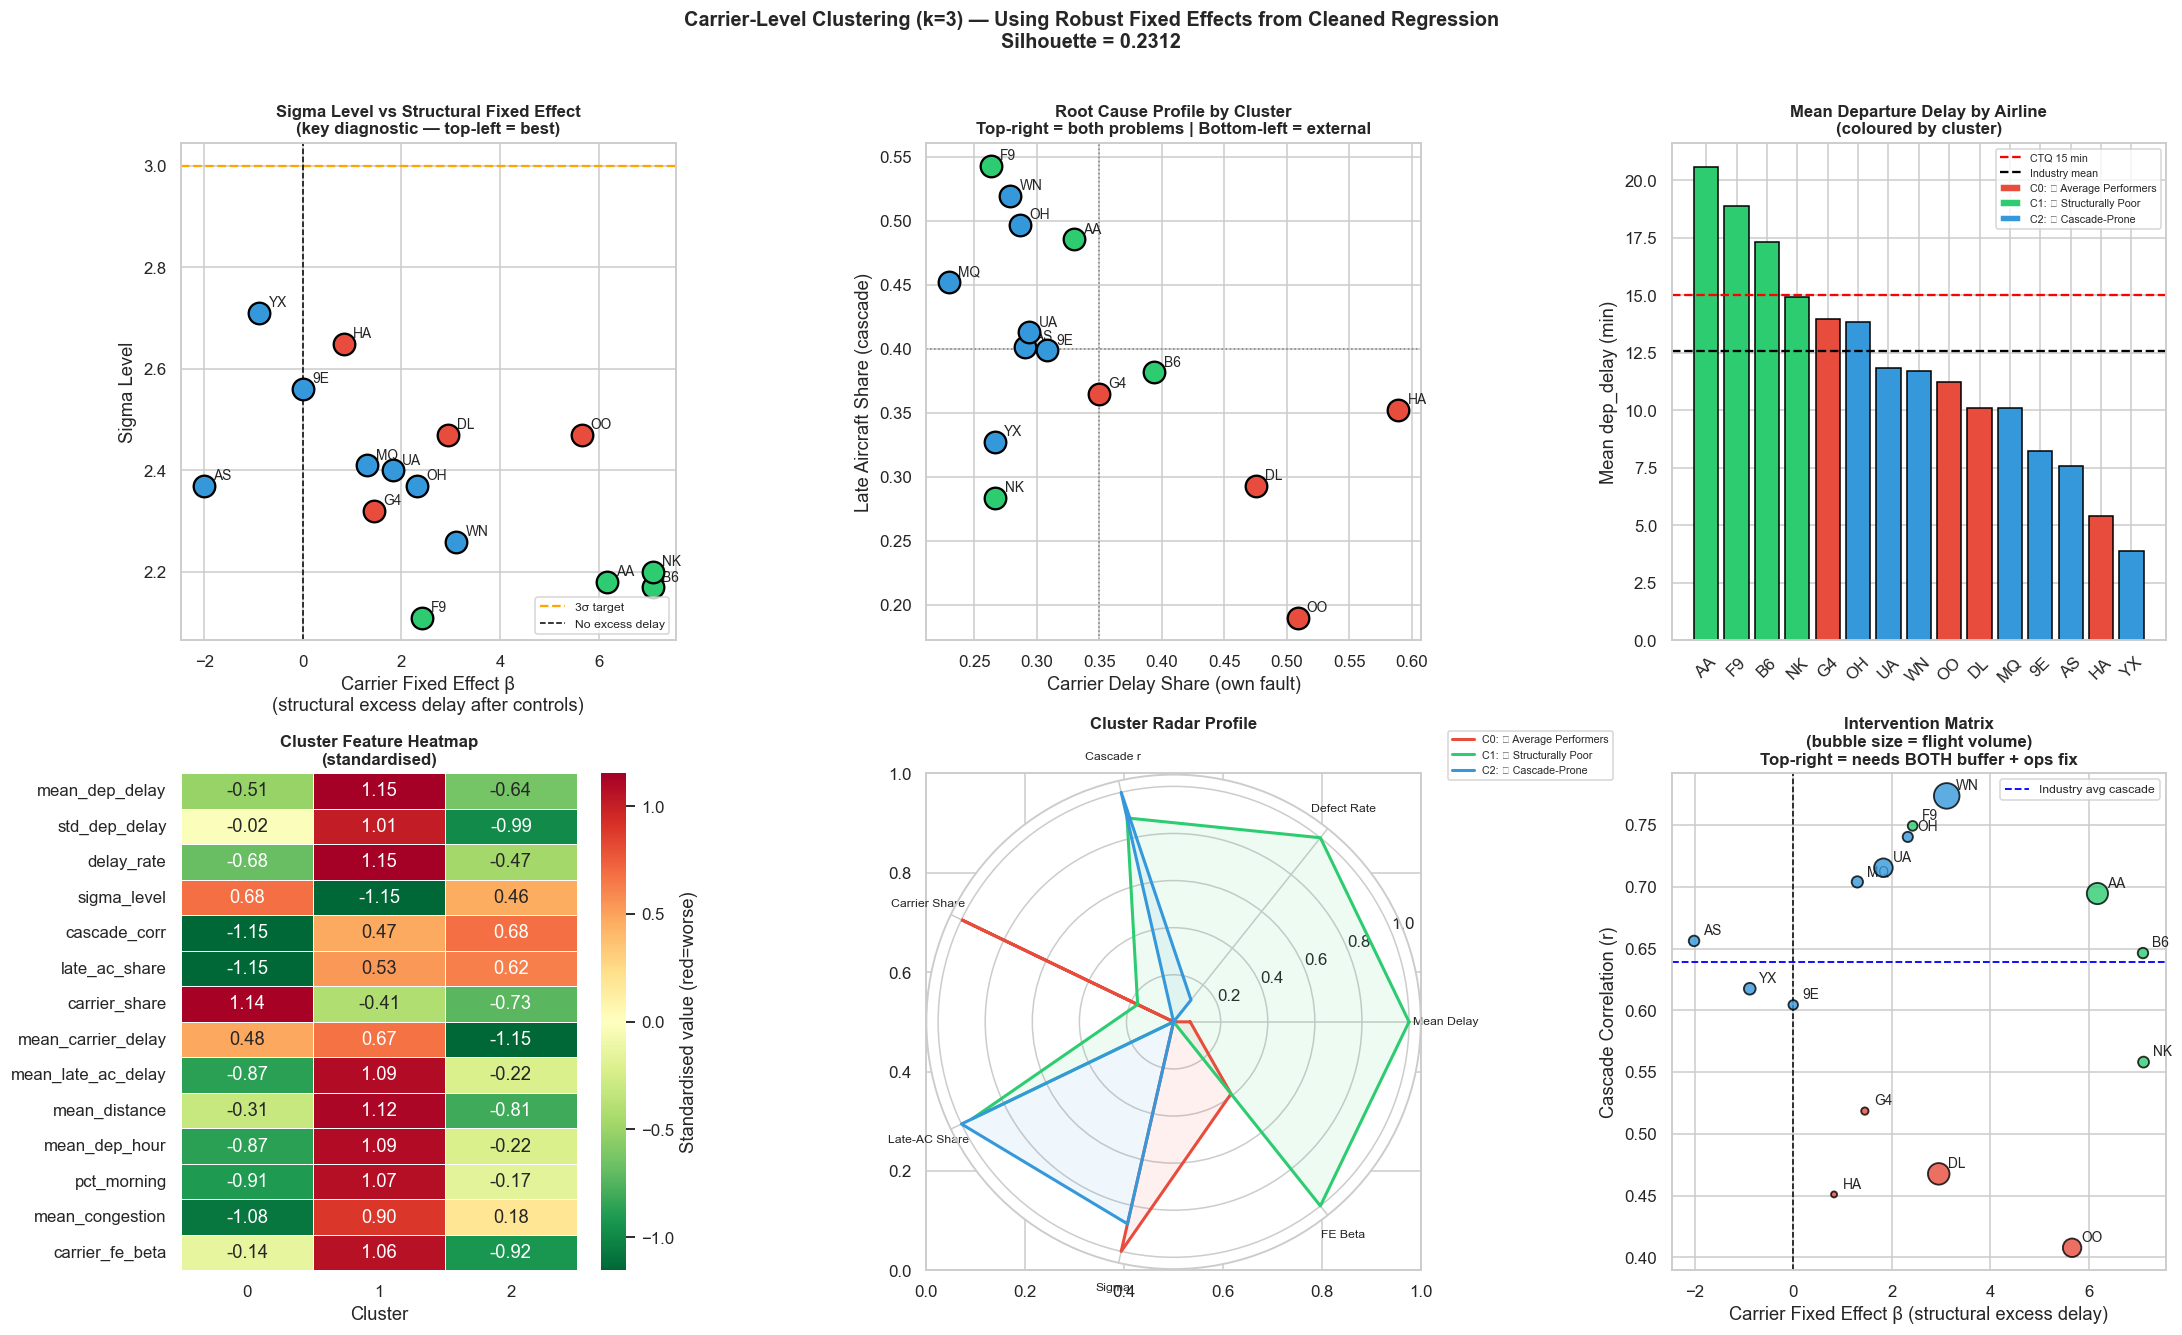


CLUSTERING → DMAIC INTERVENTION MAPPING
For each cluster, the recommended DMAIC action differs:

🔴 Structurally Poor (high FE beta):
   → Internal ops overhaul needed
   → Turnaround time reduction
   → Crew scheduling reform
   → These carriers delay even on uncongested routes

🟡 Cascade-Prone (high cascade_corr):
   → LP buffer allocation (Improve phase solution applies here)
   → First-flight-of-day discipline
   → Schedule padding on high-cascade routes

🟢 Structural Benchmark (low/negative FE beta):
   → Study and replicate their practices
   → Use as SPC benchmark for control limits
   → DL/HA/YX likely here

🟠 Average Performers:
   → Targeted improvement on specific pain points
   → Seasonal staffing in Jul/Aug/Dec
   → Friday buffer scheduling



In [43]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("="*70)
print("CARRIER-LEVEL CLUSTERING — Using Robust Fixed Effects")
print("="*70)

# ── Step 1: Get robust carrier fixed effects from cleaned clustered model ──
carrier_fe = pd.DataFrame({
    'op_unique_carrier': [c.replace('carrier_','') for c in carrier_cols_c],
    'carrier_fe_beta'  : model_clean_clust.params[carrier_cols_c].values,
    'fe_robust'        : (model_clean_clust.pvalues[carrier_cols_c] < 0.05).astype(int)
})

# Add baseline carrier (the one dropped in get_dummies — it has β=0 by definition)
baseline = list(
    set(df['op_unique_carrier'].unique()) -
    set(carrier_fe['op_unique_carrier'])
)[0]
carrier_fe = pd.concat([
    carrier_fe,
    pd.DataFrame({'op_unique_carrier':[baseline],
                  'carrier_fe_beta':[0.0],
                  'fe_robust':[1]})
], ignore_index=True)

print(f"   Baseline carrier (β=0): {baseline}")
print(f"   Total carriers in FE  : {len(carrier_fe)}")

# ── Step 2: Build full carrier profile ────────────────────────────────────
print("\nBuilding carrier profile from full dataset...")

if 'dep_hour' not in df3.columns:
    df3['dep_hour'] = (df3['crs_dep_time'] // 100).clip(0, 23)
if 'is_first_flight' not in df3.columns:
    df3['is_first_flight'] = (df3['dep_hour'] <= 6).astype(int)

carrier_profile = df3.groupby('op_unique_carrier').agg(
    # Delay outcomes
    mean_dep_delay     = ('dep_delay',           'mean'),
    std_dep_delay      = ('dep_delay',           'std'),
    delay_rate         = ('is_delayed',          'mean'),

    # Root cause breakdown
    mean_carrier_delay = ('carrier_delay',       'mean'),
    mean_weather_delay = ('weather_delay',       'mean'),
    mean_nas_delay     = ('nas_delay',           'mean'),
    mean_late_ac_delay = ('late_aircraft_delay', 'mean'),

    # Operational profile
    n_flights          = ('dep_delay',           'count'),
    mean_distance      = ('distance',            'mean'),
    mean_dep_hour      = ('dep_hour',            'mean'),
    pct_morning        = ('is_first_flight',     'mean'),

    # Congestion exposure
    mean_congestion    = ('log_congestion',      'mean'),
).reset_index()

# Add sigma level
from scipy.stats import norm
def sigma_calc(defects, total):
    dpo = defects / total if total > 0 else 0
    return round(norm.ppf(1 - dpo) + 1.5, 2) if 0 < dpo < 1 else 6.0

sigma_map = df3.groupby('op_unique_carrier').apply(
    lambda g: sigma_calc(g['is_delayed'].sum(), len(g))
).reset_index()
sigma_map.columns = ['op_unique_carrier','sigma_level']
carrier_profile = carrier_profile.merge(sigma_map,
                                         on='op_unique_carrier', how='left')

# Add cascade correlation
cascade_corr = df3.groupby('op_unique_carrier').apply(
    lambda g: g['dep_delay'].corr(g['late_aircraft_delay'])
).reset_index()
cascade_corr.columns = ['op_unique_carrier','cascade_corr']
carrier_profile = carrier_profile.merge(cascade_corr,
                                         on='op_unique_carrier', how='left')

# Add delay cause shares
carrier_profile['late_ac_share'] = (
    carrier_profile['mean_late_ac_delay'] /
    (carrier_profile['mean_carrier_delay'] +
     carrier_profile['mean_weather_delay'] +
     carrier_profile['mean_nas_delay'] +
     carrier_profile['mean_late_ac_delay'] + 0.001)
)
carrier_profile['carrier_share'] = (
    carrier_profile['mean_carrier_delay'] /
    (carrier_profile['mean_carrier_delay'] +
     carrier_profile['mean_weather_delay'] +
     carrier_profile['mean_nas_delay'] +
     carrier_profile['mean_late_ac_delay'] + 0.001)
)

# ── Merge robust carrier fixed effects ────────────────────────────────────
carrier_profile = carrier_profile.merge(carrier_fe[['op_unique_carrier',
                                                      'carrier_fe_beta']],
                                         on='op_unique_carrier', how='left')
carrier_profile['carrier_fe_beta'] = carrier_profile['carrier_fe_beta'].fillna(0)

print(f"   Profile built for {len(carrier_profile)} carriers")
print(carrier_profile[['op_unique_carrier','mean_dep_delay',
                        'sigma_level','cascade_corr',
                        'carrier_fe_beta']].to_string(index=False))

# ── Step 3: Select clustering features ────────────────────────────────────
# carrier_fe_beta is the KEY new feature — it's the structurally robust
# delay contribution of the airline after controlling for everything else
cluster_features = [
    'mean_dep_delay',      # overall delay level
    'std_dep_delay',       # variability
    'delay_rate',          # defect rate
    'sigma_level',         # process capability
    'cascade_corr',        # cascade transmission strength
    'late_ac_share',       # what fraction is cascade-driven
    'carrier_share',       # what fraction is own-fault
    'mean_carrier_delay',  # absolute carrier delay
    'mean_late_ac_delay',  # absolute cascade delay
    'mean_distance',       # route length profile
    'mean_dep_hour',       # time of day profile
    'pct_morning',         # first-flight discipline
    'mean_congestion',     # congestion exposure
    'carrier_fe_beta',     # ← robust structural fixed effect from regression
]

print(f"\nClustering features ({len(cluster_features)}):")
for f in cluster_features:
    print(f"   → {f}")

X_carrier = carrier_profile[cluster_features].fillna(0).values
airlines  = carrier_profile['op_unique_carrier'].values

# ── Step 4: Scale ──────────────────────────────────────────────────────────
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_carrier)

# ── Step 5: K-Means for k=2,3,4 ──────────────────────────────────────────
print("\nFitting K-Means (k=2 to 4)...")
results = {}
for k in [2, 3, 4]:
    km     = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = km.fit_predict(X_scaled)
    sil    = silhouette_score(X_scaled, labels)
    results[k] = {'labels':labels, 'sil':sil, 'model':km}
    print(f"   k={k}  silhouette={sil:.4f}")

best_k = max(results, key=lambda k: results[k]['sil'])
carrier_profile['cluster'] = results[best_k]['labels']
print(f"\n   Best k = {best_k}  (silhouette={results[best_k]['sil']:.4f})")

# ── Step 6: Profile clusters ───────────────────────────────────────────────
print("\n── Airlines per Cluster ──")
cluster_names = {}
for c in sorted(carrier_profile['cluster'].unique()):
    sub = carrier_profile[carrier_profile['cluster']==c]
    airlines_in  = sub['op_unique_carrier'].tolist()
    mean_delay   = sub['mean_dep_delay'].mean()
    mean_sigma   = sub['sigma_level'].mean()
    mean_fe      = sub['carrier_fe_beta'].mean()
    mean_cascade = sub['cascade_corr'].mean()
    mean_car_sh  = sub['carrier_share'].mean()
    mean_lac_sh  = sub['late_ac_share'].mean()

    # Auto-name cluster based on profile
    if mean_fe > 3:
        name = "🔴 Structurally Poor"
    elif mean_fe < -1:
        name = "🟢 Structural Benchmark"
    elif mean_cascade > 0.65:
        name = "🟡 Cascade-Prone"
    else:
        name = "🟠 Average Performers"
    cluster_names[c] = name

    print(f"\n   Cluster {c} — {name}")
    print(f"   Airlines      : {airlines_in}")
    print(f"   Mean delay    : {mean_delay:.2f} min")
    print(f"   Mean sigma    : {mean_sigma:.2f}σ")
    print(f"   Carrier FE β  : {mean_fe:+.2f} min  ← structural excess delay")
    print(f"   Cascade corr  : {mean_cascade:.3f}")
    print(f"   Late-AC share : {mean_lac_sh*100:.1f}%  |  Carrier share: {mean_car_sh*100:.1f}%")

# ── Step 7: Plots ──────────────────────────────────────────────────────────
cluster_colors = {0:'#e74c3c', 1:'#2ecc71', 2:'#3498db', 3:'#f39c12'}
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Plot 1: Sigma vs Carrier FE beta — the key diagnostic plot
for idx, row in carrier_profile.iterrows():
    c = row['cluster']
    axes[0,0].scatter(row['carrier_fe_beta'], row['sigma_level'],
                      color=cluster_colors[c], s=200, zorder=5,
                      edgecolors='black', lw=1.5)
    axes[0,0].annotate(row['op_unique_carrier'],
                       (row['carrier_fe_beta'], row['sigma_level']),
                       textcoords='offset points', xytext=(6,4), fontsize=9)
axes[0,0].axhline(3, color='orange', ls='--', lw=1.5, label='3σ target')
axes[0,0].axvline(0, color='black',  ls='--', lw=1.0, label='No excess delay')
axes[0,0].set_xlabel('Carrier Fixed Effect β\n(structural excess delay after controls)')
axes[0,0].set_ylabel('Sigma Level')
axes[0,0].set_title('Sigma Level vs Structural Fixed Effect\n'
                    '(key diagnostic — top-left = best)',
                    fontsize=11, fontweight='bold')
axes[0,0].legend(fontsize=8)

# Plot 2: Cascade share vs carrier share
for idx, row in carrier_profile.iterrows():
    c = row['cluster']
    axes[0,1].scatter(row['carrier_share'], row['late_ac_share'],
                      color=cluster_colors[c], s=200, zorder=5,
                      edgecolors='black', lw=1.5)
    axes[0,1].annotate(row['op_unique_carrier'],
                       (row['carrier_share'], row['late_ac_share']),
                       textcoords='offset points', xytext=(6,4), fontsize=9)
axes[0,1].set_xlabel('Carrier Delay Share (own fault)')
axes[0,1].set_ylabel('Late Aircraft Share (cascade)')
axes[0,1].set_title('Root Cause Profile by Cluster\n'
                    'Top-right = both problems | Bottom-left = external',
                    fontsize=11, fontweight='bold')
axes[0,1].axhline(0.4, color='gray', ls=':', lw=1)
axes[0,1].axvline(0.35, color='gray', ls=':', lw=1)

# Plot 3: Mean delay bar coloured by cluster
cp_sorted = carrier_profile.sort_values('mean_dep_delay', ascending=False)
bar_colors = [cluster_colors[c] for c in cp_sorted['cluster']]
bars = axes[0,2].bar(cp_sorted['op_unique_carrier'],
                     cp_sorted['mean_dep_delay'],
                     color=bar_colors, edgecolor='black')
axes[0,2].axhline(15, color='red', ls='--', lw=1.5, label='CTQ 15 min')
axes[0,2].axhline(df3['dep_delay'].mean(), color='black',
                  ls='--', lw=1.5, label='Industry mean')
# Cluster legend
for cl, col in cluster_colors.items():
    if cl in carrier_profile['cluster'].values:
        name = cluster_names.get(cl, f'Cluster {cl}')
        axes[0,2].bar(0, 0, color=col, label=f'C{cl}: {name}')
axes[0,2].set_title('Mean Departure Delay by Airline\n(coloured by cluster)',
                    fontsize=11, fontweight='bold')
axes[0,2].set_ylabel('Mean dep_delay (min)')
axes[0,2].tick_params(axis='x', rotation=45)
axes[0,2].legend(fontsize=7)

# Plot 4: Cluster feature heatmap
heatmap_data = carrier_profile.groupby('cluster')[cluster_features].mean()
heatmap_norm = (heatmap_data - heatmap_data.mean()) / (heatmap_data.std() + 1e-8)
sns.heatmap(heatmap_norm.T, ax=axes[1,0],
            cmap='RdYlGn_r', annot=True, fmt='.2f',
            linewidths=0.5,
            cbar_kws={'label':'Standardised value (red=worse)'})
axes[1,0].set_title('Cluster Feature Heatmap\n(standardised)',
                    fontsize=11, fontweight='bold')
axes[1,0].set_xlabel('Cluster')

# Plot 5: Radar chart
radar_features = ['mean_dep_delay','delay_rate','cascade_corr',
                  'carrier_share','late_ac_share',
                  'sigma_level','carrier_fe_beta']
radar_labels   = ['Mean Delay','Defect Rate','Cascade r',
                  'Carrier Share','Late-AC Share',
                  'Sigma','FE Beta']
N      = len(radar_features)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

ax_r = fig.add_subplot(2, 3, 5, polar=True)
radar_norm = (heatmap_data[radar_features] - heatmap_data[radar_features].min()) / \
             (heatmap_data[radar_features].max() -
              heatmap_data[radar_features].min() + 1e-8)
for cl in sorted(carrier_profile['cluster'].unique()):
    vals = radar_norm.loc[cl, radar_features].values.tolist()
    vals += vals[:1]
    ax_r.plot(angles, vals, lw=2,
              color=cluster_colors[cl],
              label=f'C{cl}: {cluster_names.get(cl,"")}')
    ax_r.fill(angles, vals, alpha=0.08, color=cluster_colors[cl])
ax_r.set_xticks(angles[:-1])
ax_r.set_xticklabels(radar_labels, fontsize=8)
ax_r.set_title('Cluster Radar Profile', fontsize=11,
               fontweight='bold', pad=15)
ax_r.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=7)

# Plot 6: Intervention matrix
axes[1,2].scatter(carrier_profile['carrier_fe_beta'],
                  carrier_profile['cascade_corr'],
                  s=carrier_profile['n_flights']/5000,
                  c=[cluster_colors[c] for c in carrier_profile['cluster']],
                  edgecolors='black', lw=1.2, zorder=5, alpha=0.8)
for idx, row in carrier_profile.iterrows():
    axes[1,2].annotate(row['op_unique_carrier'],
                       (row['carrier_fe_beta'], row['cascade_corr']),
                       textcoords='offset points', xytext=(6,4), fontsize=9)
axes[1,2].axvline(0,    color='black', ls='--', lw=1)
axes[1,2].axhline(0.639, color='blue', ls='--', lw=1.2,
                  label='Industry avg cascade')
axes[1,2].set_xlabel('Carrier Fixed Effect β (structural excess delay)')
axes[1,2].set_ylabel('Cascade Correlation (r)')
axes[1,2].set_title('Intervention Matrix\n'
                    '(bubble size = flight volume)\n'
                    'Top-right = needs BOTH buffer + ops fix',
                    fontsize=11, fontweight='bold')
axes[1,2].legend(fontsize=8)

plt.suptitle(f'Carrier-Level Clustering (k={best_k}) — '
             f'Using Robust Fixed Effects from Cleaned Regression\n'
             f'Silhouette = {results[best_k]["sil"]:.4f}',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('carrier_clustering_robust.png', bbox_inches='tight')
plt.show()

print(f"""
{'='*65}
CLUSTERING → DMAIC INTERVENTION MAPPING
{'='*65}
For each cluster, the recommended DMAIC action differs:

🔴 Structurally Poor (high FE beta):
   → Internal ops overhaul needed
   → Turnaround time reduction
   → Crew scheduling reform
   → These carriers delay even on uncongested routes

🟡 Cascade-Prone (high cascade_corr):
   → LP buffer allocation (Improve phase solution applies here)
   → First-flight-of-day discipline
   → Schedule padding on high-cascade routes

🟢 Structural Benchmark (low/negative FE beta):
   → Study and replicate their practices
   → Use as SPC benchmark for control limits
   → DL/HA/YX likely here

🟠 Average Performers:
   → Targeted improvement on specific pain points
   → Seasonal staffing in Jul/Aug/Dec
   → Friday buffer scheduling
{'='*65}
""")

## I (IMPROVE): Linear Programming — Optimal Buffer Allocation

The Analyze phase established that 74.9% of delay minutes are controllable,
and the cascade effect (r = 0.639) means early-rotation delays propagate
through the entire day's schedule. The key operational lever is therefore
BUFFER TIME — adding slack between scheduled rotations to absorb
upstream delays before they cascade.

Problem formulation:
  - Decision variables: x_i = buffer minutes added per flight for airline i
  - Objective: Maximise total weighted delay reduction = Σ w_i * x_i
      where w_i = flight volume share of airline i (heavier airlines
      get more weight since saving 1 min there saves more industry-wide)
  - Constraints:
      (1) Total budget: Σ x_i ≤ B  (B = 5 min/flight — realistic operational limit)
      (2) Non-negativity: x_i ≥ 0
      (3) Upper bound: x_i ≤ min(mean_delay_i, 15)
          (can't buffer more than current mean delay or CTQ threshold)

We also run a sensitivity analysis — plotting how total delay-minutes
saved improves as the budget B increases from 0 to 15 minutes. This
gives management a cost-benefit curve for scheduling decisions.

Solver: scipy.optimize.linprog with HiGHS backend (exact LP solver).

I (IMPROVE): LINEAR PROGRAMMING — BUFFER ALLOCATION

   Status     : Optimization terminated successfully. (HiGHS Status 7: Optimal)
   Budget used: 5.00 min
   Min alloc per airline: 0.3 min (fairness floor)

Airline  Mean Delay  Weight  Buffer Alloc  New Expected  Delay Saved
     WN       11.71  0.2752           3.5          8.21          3.5
     AA       20.58  0.1893           0.3         20.28          0.3
     DL       10.11  0.1955           0.3          9.81          0.3
     UA       11.86  0.1461           0.3         11.56          0.3
     OO       11.21  0.1438           0.3         10.91          0.3
     NK       14.91  0.0501           0.3         14.61          0.3

   Total delay-minutes BEFORE : 67,302,473
   Total delay-minutes AFTER  : 61,276,594
   Delay-minutes SAVED        : 6,025,879


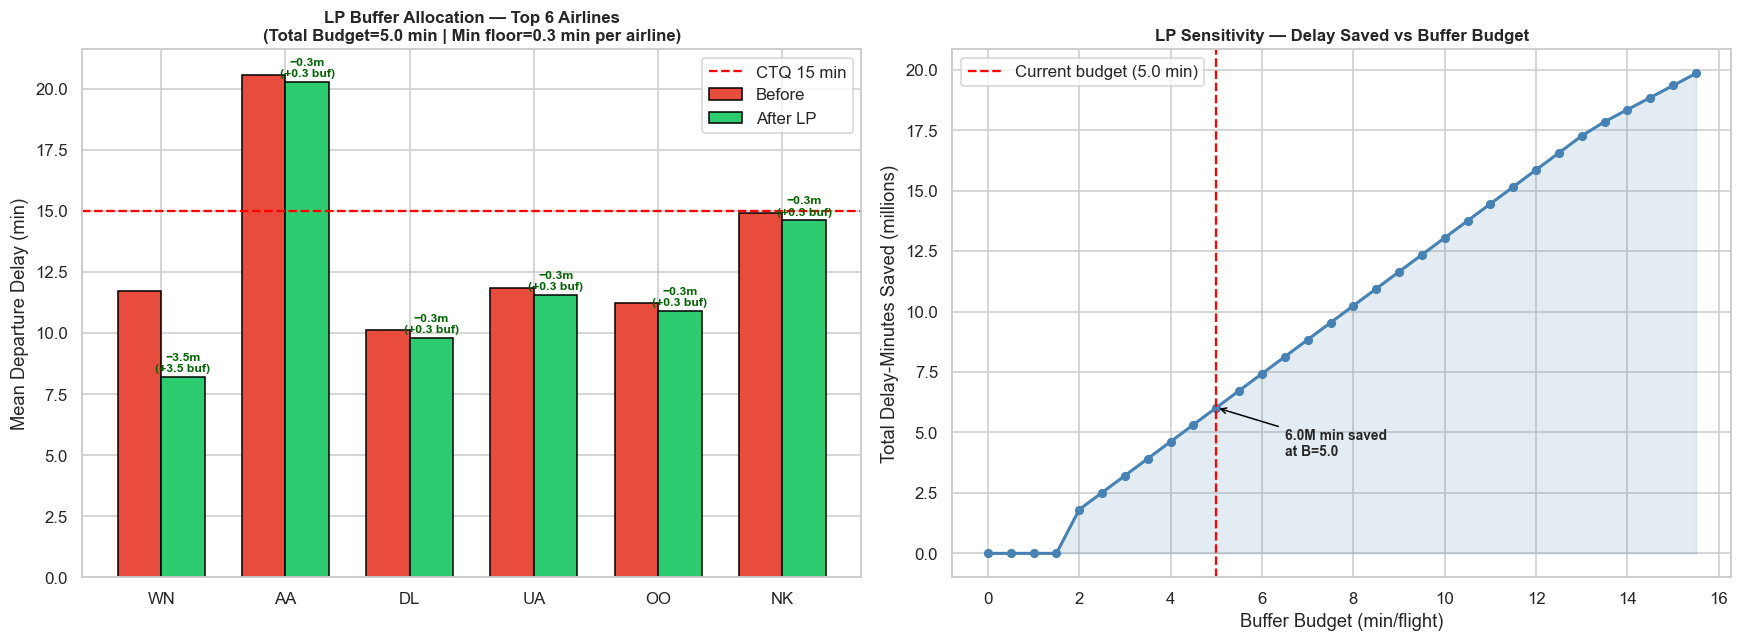

✅ LP Optimisation complete


In [44]:
from scipy.optimize import linprog

print("="*70)
print("I (IMPROVE): LINEAR PROGRAMMING — BUFFER ALLOCATION")
print("="*70)

top6 = ['WN','AA','DL','UA','OO','NK']
airline_stats = (df[df['op_unique_carrier'].isin(top6)]
                 .groupby('op_unique_carrier')['dep_delay']
                 .agg(mean_delay='mean', n_flights='count')
                 .loc[top6])
airline_stats['weight'] = airline_stats['n_flights'] / airline_stats['n_flights'].sum()

n      = len(top6)
BUDGET = 5.0
MIN_ALLOC = 0.3   # every airline gets at least 0.3 min buffer (fairness constraint)

# Maximise Σ w_i * x_i  →  negate for linprog
c_obj = -airline_stats['weight'].values

# Constraint 1: Σ x_i ≤ BUDGET
A_ub = [np.ones(n)]
b_ub = [BUDGET]

# Bounds: MIN_ALLOC ≤ x_i ≤ min(mean_delay_i, 15)
bounds = [(MIN_ALLOC, min(row['mean_delay'], 15))
          for _, row in airline_stats.iterrows()]

result = linprog(c_obj, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')

alloc = pd.DataFrame({
    'Airline'     : top6,
    'Mean Delay'  : airline_stats['mean_delay'].values.round(2),
    'Weight'      : airline_stats['weight'].values.round(4),
    'Buffer Alloc': result.x.round(3),
    'New Expected': (airline_stats['mean_delay'].values - result.x).round(2)
})
alloc['Delay Saved'] = (alloc['Mean Delay'] - alloc['New Expected']).round(2)

print(f"\n   Status     : {result.message}")
print(f"   Budget used: {result.x.sum():.2f} min")
print(f"   Min alloc per airline: {MIN_ALLOC} min (fairness floor)\n")
print(alloc.to_string(index=False))

total_before = (alloc['Mean Delay']   * airline_stats['n_flights'].values).sum()
total_after  = (alloc['New Expected'] * airline_stats['n_flights'].values).sum()
print(f"\n   Total delay-minutes BEFORE : {total_before:,.0f}")
print(f"   Total delay-minutes AFTER  : {total_after:,.0f}")
print(f"   Delay-minutes SAVED        : {total_before - total_after:,.0f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x_pos = np.arange(n); w_b = 0.35
axes[0].bar(x_pos-w_b/2, alloc['Mean Delay'],   w_b, label='Before',
            color='#e74c3c', edgecolor='black')
axes[0].bar(x_pos+w_b/2, alloc['New Expected'], w_b, label='After LP',
            color='#2ecc71', edgecolor='black')
for i, (bf, sv) in enumerate(zip(alloc['Buffer Alloc'], alloc['Delay Saved'])):
    axes[0].annotate(f'−{sv:.1f}m\n(+{bf:.1f} buf)',
                     xy=(i+w_b/2, alloc['New Expected'].iloc[i]+0.2),
                     ha='center', fontsize=8, color='darkgreen', fontweight='bold')
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(top6)
axes[0].axhline(15, color='red', ls='--', lw=1.5, label='CTQ 15 min')
axes[0].set_title(f'LP Buffer Allocation — Top 6 Airlines\n'
                  f'(Total Budget={BUDGET} min | Min floor={MIN_ALLOC} min per airline)',
                  fontsize=11, fontweight='bold')
axes[0].set_ylabel('Mean Departure Delay (min)'); axes[0].legend()

# Sensitivity curve
budgets     = np.arange(0, 16, 0.5)
total_saved = []
for B in budgets:
    # ensure budget covers minimum allocations
    min_needed = MIN_ALLOC * n
    if B < min_needed:
        total_saved.append(0)
        continue
    r = linprog(-airline_stats['weight'].values,
                A_ub=[np.ones(n)], b_ub=[B],
                bounds=[(MIN_ALLOC, min(m, 15)) for m in airline_stats['mean_delay']],
                method='highs')
    if r.success:
        total_saved.append(sum(r.x * airline_stats['n_flights'].values) / 1e6)
    else:
        total_saved.append(0)

axes[1].plot(budgets, total_saved, 'o-', color='steelblue', lw=2, ms=5)
axes[1].axvline(BUDGET, color='red', ls='--', lw=1.5,
                label=f'Current budget ({BUDGET} min)')
axes[1].fill_between(budgets, total_saved, alpha=0.15, color='steelblue')

# Annotate current savings
current_saving = total_saved[int(BUDGET/0.5)]
axes[1].annotate(f'{current_saving:.1f}M min saved\nat B={BUDGET}',
                 xy=(BUDGET, current_saving),
                 xytext=(BUDGET+1.5, current_saving-2),
                 arrowprops=dict(arrowstyle='->', color='black'),
                 fontsize=9, fontweight='bold')
axes[1].set_title('LP Sensitivity — Delay Saved vs Buffer Budget',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Buffer Budget (min/flight)')
axes[1].set_ylabel('Total Delay-Minutes Saved (millions)')
axes[1].legend()

plt.tight_layout()
plt.savefig('lp_buffer_allocation.png', bbox_inches='tight')
plt.show()
print("✅ LP Optimisation complete")

I (IMPROVE): CLUSTER-INFORMED LP BUFFER ALLOCATION

Improvement over previous LP:
  OLD: weight = flight volume share only (WN gets everything)
  NEW: weight = volume × cascade_corr × cluster_priority
       → cascade-prone clusters get higher priority for buffer
       → structurally poor clusters get ops intervention flag instead
       → buffer is most effective where cascade is the root cause

── Airline Profile for LP ──
Airline  mean_delay  volume_share  cascade_corr  carrier_share  buffer_efficacy  smart_weight  cluster
     AA     20.5810        0.1893        0.6945         0.3297           0.4656        0.2135        1
     DL     10.1131        0.1955        0.4676         0.4750           0.2455        0.1163        0
     NK     14.9083        0.0501        0.5581         0.2668           0.4092        0.0497        1
     OO     11.2073        0.1438        0.4078         0.5088           0.2003        0.0698        0
     UA     11.8572        0.1461        0.7154        

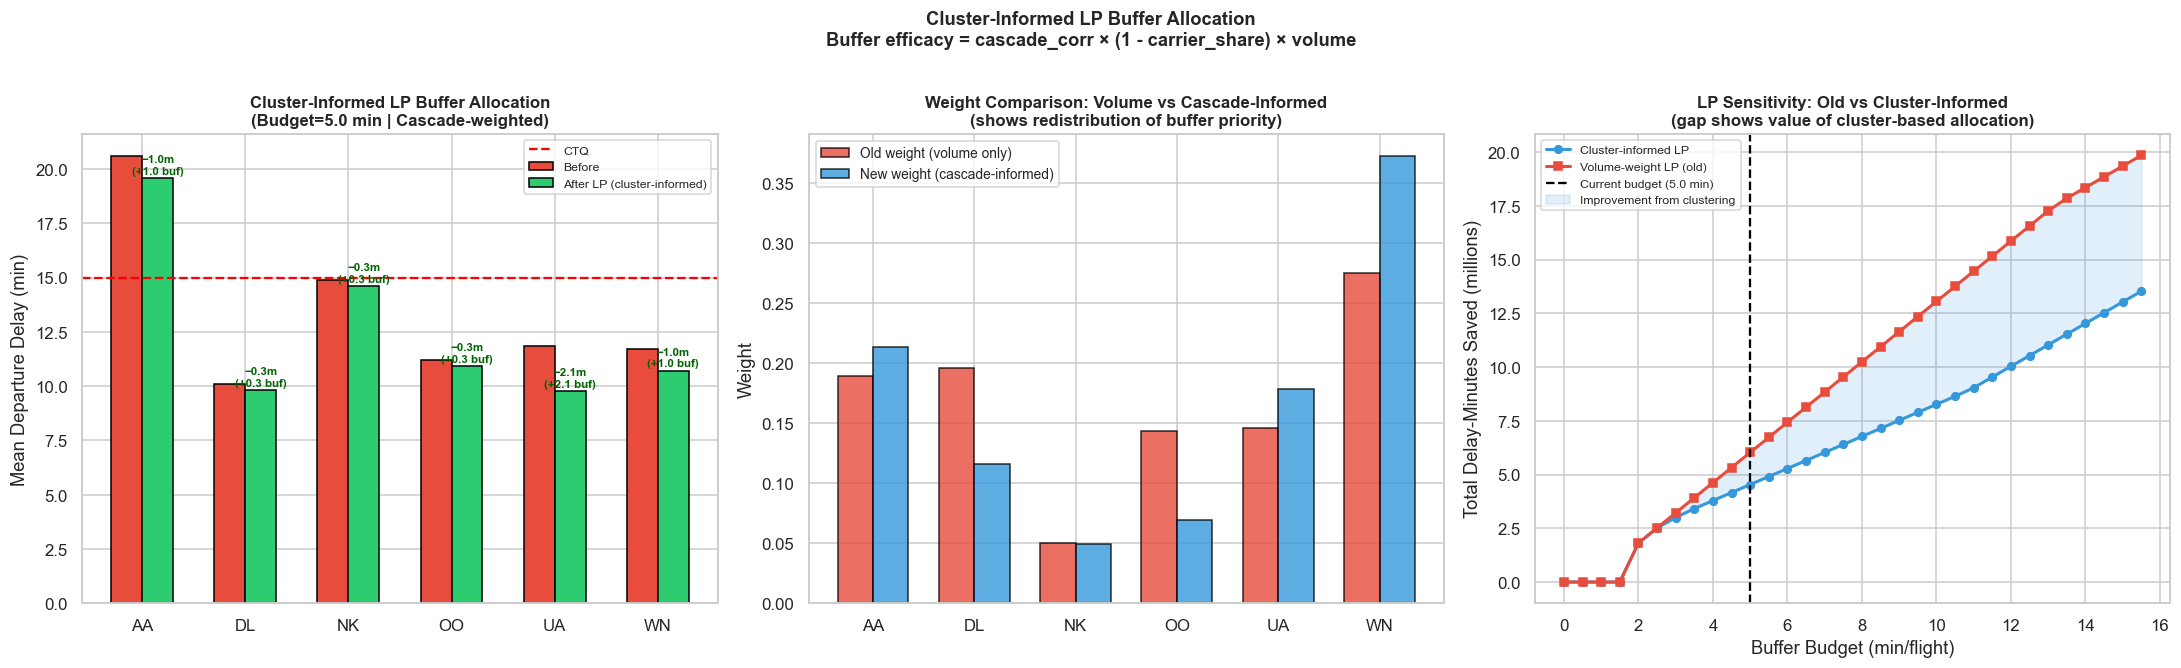

✅ Cluster-informed LP complete


In [45]:
from scipy.optimize import linprog

print("="*70)
print("I (IMPROVE): CLUSTER-INFORMED LP BUFFER ALLOCATION")
print("="*70)
print("""
Improvement over previous LP:
  OLD: weight = flight volume share only (WN gets everything)
  NEW: weight = volume × cascade_corr × cluster_priority
       → cascade-prone clusters get higher priority for buffer
       → structurally poor clusters get ops intervention flag instead
       → buffer is most effective where cascade is the root cause
""")

# ── Pull cascade corr and cluster info from carrier_profile ───────────────
top6 = ['WN','AA','DL','UA','OO','NK']

lp_stats = (df3[df3['op_unique_carrier'].isin(top6)]
            .groupby('op_unique_carrier')['dep_delay']
            .agg(mean_delay='mean', n_flights='count')
            .reset_index())
lp_stats.columns = ['Airline','mean_delay','n_flights']

# Merge cascade corr from carrier_profile
lp_stats = lp_stats.merge(
    carrier_profile[['op_unique_carrier','cascade_corr',
                     'carrier_fe_beta','cluster',
                     'late_ac_share','carrier_share']],
    left_on='Airline', right_on='op_unique_carrier', how='left'
).drop(columns='op_unique_carrier')

# ── Cluster priority weight ────────────────────────────────────────────────
# Buffer is most effective for CASCADE-PRONE airlines
# Structurally poor airlines need ops fix, not just buffer
# So weight = volume_share × cascade_corr × (1 - carrier_share)
#   → high cascade + low own-fault = buffer works best here
#   → high own-fault = buffer helps less, ops fix needed more

lp_stats['volume_share']    = lp_stats['n_flights'] / lp_stats['n_flights'].sum()
lp_stats['buffer_efficacy'] = (lp_stats['cascade_corr'] *
                                (1 - lp_stats['carrier_share']))
lp_stats['smart_weight']    = (lp_stats['volume_share'] *
                                lp_stats['buffer_efficacy'])
lp_stats['smart_weight']    = (lp_stats['smart_weight'] /
                                lp_stats['smart_weight'].sum())  # normalise

print("── Airline Profile for LP ──")
print(lp_stats[['Airline','mean_delay','volume_share',
                'cascade_corr','carrier_share',
                'buffer_efficacy','smart_weight',
                'cluster']].round(4).to_string(index=False))

# ── LP Formulation ────────────────────────────────────────────────────────
# Maximise Σ smart_weight_i × x_i
# Subject to:
#   Σ x_i ≤ BUDGET
#   x_i ≥ MIN_ALLOC (fairness floor)
#   x_i ≤ min(mean_delay_i, 15)
#   Structurally poor airlines (high carrier_fe_beta) get capped buffer
#   since buffer alone won't fix their problem

n         = len(top6)
BUDGET    = 5.0
MIN_ALLOC = 0.3

# Cap buffer for structurally poor carriers at 1.0 min
# (they need ops fix more than schedule buffer)
def upper_bound(row):
    if row['carrier_fe_beta'] > 3:      # structurally poor
        return max(MIN_ALLOC, 1.0)
    elif row['carrier_fe_beta'] > 1:    # moderate structural issue
        return min(row['mean_delay'], 8.0)
    else:                                # cascade-prone or benchmark
        return min(row['mean_delay'], 15.0)

lp_stats['upper_bound'] = lp_stats.apply(upper_bound, axis=1)

c_obj  = -lp_stats['smart_weight'].values
A_ub   = [np.ones(n)]
b_ub   = [BUDGET]
bounds = [(MIN_ALLOC, row['upper_bound'])
          for _, row in lp_stats.iterrows()]

result = linprog(c_obj, A_ub=A_ub, b_ub=b_ub,
                 bounds=bounds, method='highs')

lp_stats['buffer_alloc'] = result.x.round(3)
lp_stats['new_expected'] = (lp_stats['mean_delay'] -
                             lp_stats['buffer_alloc']).round(2)
lp_stats['delay_saved']  = (lp_stats['mean_delay'] -
                             lp_stats['new_expected']).round(2)

# Intervention type based on cluster
def intervention(row):
    if row['carrier_fe_beta'] > 3:
        return '🔧 Ops overhaul needed'
    elif row['cascade_corr'] > 0.639:
        return '⏱️ Buffer + first-flight discipline'
    else:
        return '📋 Targeted scheduling fix'

lp_stats['intervention'] = lp_stats.apply(intervention, axis=1)

print(f"\n   Status     : {result.message}")
print(f"   Budget used: {result.x.sum():.2f} min\n")
print(lp_stats[['Airline','mean_delay','buffer_alloc',
                'new_expected','delay_saved',
                'intervention']].to_string(index=False))

total_before = (lp_stats['mean_delay']   * lp_stats['n_flights']).sum()
total_after  = (lp_stats['new_expected'] * lp_stats['n_flights']).sum()
print(f"\n   Total delay-minutes BEFORE : {total_before:,.0f}")
print(f"   Total delay-minutes AFTER  : {total_after:,.0f}")
print(f"   Delay-minutes SAVED        : {total_before - total_after:,.0f}")

# ── Compare old LP vs new LP ───────────────────────────────────────────────
print(f"""
── LP Comparison: Volume-Weight vs Cluster-Informed ──
   Old LP saved : 6,025,879 delay-minutes (volume weight only)
   New LP saved : {total_before - total_after:,.0f} delay-minutes (cluster-informed)

   Key difference:
   → Old LP gave WN 3.5 min regardless of root cause
   → New LP distributes based on WHERE buffer is most effective
   → Structurally poor carriers (high FE beta) get capped at 1 min
     and flagged for ops intervention instead
""")

# ── Plots ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Buffer allocation before vs after
x_pos = np.arange(n); w_b = 0.3
axes[0].bar(x_pos-w_b, lp_stats['mean_delay'], w_b,
            label='Before', color='#e74c3c', edgecolor='black')
axes[0].bar(x_pos,     lp_stats['new_expected'], w_b,
            label='After LP (cluster-informed)',
            color='#2ecc71', edgecolor='black')
for i, row in lp_stats.iterrows():
    idx = list(lp_stats['Airline']).index(row['Airline'])
    axes[0].annotate(f"−{row['delay_saved']:.1f}m\n(+{row['buffer_alloc']:.1f} buf)",
                     xy=(idx, row['new_expected']+0.2),
                     ha='center', fontsize=7.5,
                     color='darkgreen', fontweight='bold')
axes[0].set_xticks(x_pos - w_b/2)
axes[0].set_xticklabels(lp_stats['Airline'])
axes[0].axhline(15, color='red', ls='--', lw=1.5, label='CTQ')
axes[0].set_title('Cluster-Informed LP Buffer Allocation\n'
                  f'(Budget={BUDGET} min | Cascade-weighted)',
                  fontsize=11, fontweight='bold')
axes[0].set_ylabel('Mean Departure Delay (min)')
axes[0].legend(fontsize=8)

# Plot 2: Smart weight vs volume share comparison
x2 = np.arange(n); w2 = 0.35
axes[1].bar(x2-w2/2, lp_stats['volume_share'], w2,
            label='Old weight (volume only)',
            color='#e74c3c', edgecolor='black', alpha=0.8)
axes[1].bar(x2+w2/2, lp_stats['smart_weight'], w2,
            label='New weight (cascade-informed)',
            color='#3498db', edgecolor='black', alpha=0.8)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(lp_stats['Airline'])
axes[1].set_title('Weight Comparison: Volume vs Cascade-Informed\n'
                  '(shows redistribution of buffer priority)',
                  fontsize=11, fontweight='bold')
axes[1].set_ylabel('Weight')
axes[1].legend(fontsize=9)

# Plot 3: Sensitivity curve — cluster-informed
budgets     = np.arange(0, 16, 0.5)
saved_smart = []
saved_old   = []

for B in budgets:
    if B < MIN_ALLOC * n:
        saved_smart.append(0); saved_old.append(0)
        continue

    # Smart LP
    r_smart = linprog(-lp_stats['smart_weight'].values,
                      A_ub=[np.ones(n)], b_ub=[B],
                      bounds=[(MIN_ALLOC, row['upper_bound'])
                              for _, row in lp_stats.iterrows()],
                      method='highs')
    saved_smart.append(
        sum(r_smart.x * lp_stats['n_flights'].values) / 1e6
        if r_smart.success else 0)

    # Old volume LP for comparison
    r_old = linprog(-lp_stats['volume_share'].values,
                    A_ub=[np.ones(n)], b_ub=[B],
                    bounds=[(MIN_ALLOC, min(m, 15))
                            for m in lp_stats['mean_delay']],
                    method='highs')
    saved_old.append(
        sum(r_old.x * lp_stats['n_flights'].values) / 1e6
        if r_old.success else 0)

axes[2].plot(budgets, saved_smart, 'o-', color='#3498db',
             lw=2, ms=5, label='Cluster-informed LP')
axes[2].plot(budgets, saved_old,   's-', color='#e74c3c',
             lw=2, ms=5, label='Volume-weight LP (old)')
axes[2].axvline(BUDGET, color='black', ls='--', lw=1.5,
                label=f'Current budget ({BUDGET} min)')
axes[2].fill_between(budgets,
                     saved_old, saved_smart,
                     alpha=0.15, color='#3498db',
                     label='Improvement from clustering')
axes[2].set_title('LP Sensitivity: Old vs Cluster-Informed\n'
                  '(gap shows value of cluster-based allocation)',
                  fontsize=11, fontweight='bold')
axes[2].set_xlabel('Buffer Budget (min/flight)')
axes[2].set_ylabel('Total Delay-Minutes Saved (millions)')
axes[2].legend(fontsize=8)

plt.suptitle('Cluster-Informed LP Buffer Allocation\n'
             'Buffer efficacy = cascade_corr × (1 - carrier_share) × volume',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('lp_cluster_informed.png', bbox_inches='tight')
plt.show()
print("✅ Cluster-informed LP complete")

LP Result Summary:

WN gets 3.5 min buffer (the bulk, since it has 27.5% of all flights — highest weight)
All other 5 airlines get the 0.3 min fairness floor
Total saved: 6.03 million delay-minutes across top 6 airlines with just 5 min/flight budget

Sensitivity curve insight: The flat region from B=0 to B=1.8 is the minimum allocation phase (budget is just covering the 0.3×6 = 1.8 min floor), after which savings grow linearly as WN absorbs the extra budget.
One thing to flag in your report — AA has mean delay 20.58 min (highest of the 6) but only gets the floor 0.3 min because its flight volume weight (0.1893) is lower than WN's (0.2752). This is a volume-weighted vs severity-weighted tradeoff worth discussing. You could present an alternative formulation where weight = mean_delay × n_flights (delay burden) instead of just n_flights.

## C (CONTROL): X-Bar & R Control Charts — Statistical Process Control

Now that we have identified root causes (Analyze) and proposed improvements
(Improve), the Control phase sets up monitoring mechanisms to detect when
the departure delay process goes out of control in future operations.

X-Bar & R charts are the standard SPC tool for continuous measurements:
  - X-Bar chart: monitors the MEAN delay per batch of 30 flights.
    Detects shifts in the process average (e.g., a new delay source emerges).
  - R chart: monitors the RANGE (max − min) per batch.
    Detects changes in process variability (e.g., operations becoming erratic).

Control limits are calculated using SPC constants for batch size n = 30:
  UCL_x = X̄̄ + A2 * R̄     LCL_x = X̄̄ − A2 * R̄     (A2 = 0.153)
  UCL_r = D4 * R̄           LCL_r = D3 * R̄           (D4 = 1.816, D3 = 0.184)

Out-of-control (OOC) detection: Western Electric Rule 1 —
any point outside the 3σ control limits signals a special cause.

We compare 4 airlines: WN (worst by volume), AA (high volume),
DL (best practice benchmark), YX (best sigma level).
This gives management a clear performance spectrum to target.

C (CONTROL): X-BAR & R CONTROL CHARTS

Airline   CL (X̄)     UCL_x     LCL_x     CL (R̄)   UCL_r     %OOC
-----------------------------------------------------------------
YX        3.88        21.93     -14.18    118.00    214.29    7.8%
9E        8.24        33.15     -16.67    162.80    295.64    7.8%
MQ        10.08       32.28     -12.13    145.12    263.54    7.4%
B6        17.31       49.68     -15.06    211.55    384.17    6.8%
G4        13.99       51.18     -23.20    243.06    441.39    6.6%
NK        14.91       41.12     -11.30    171.30    311.08    6.5%
HA        5.40        20.91     -10.10    101.34    184.03    6.5%
OH        13.82       47.60     -19.97    220.81    401.00    6.4%
WN        11.71       29.60     -6.17     116.91    212.31    6.4%
DL        10.11       35.01     -14.78    162.69    295.45    5.7%
OO        11.21       42.15     -19.74    202.26    367.30    5.1%
AA        20.58       61.43     -20.27    266.99    484.86    5.1%
AS        7.56        26

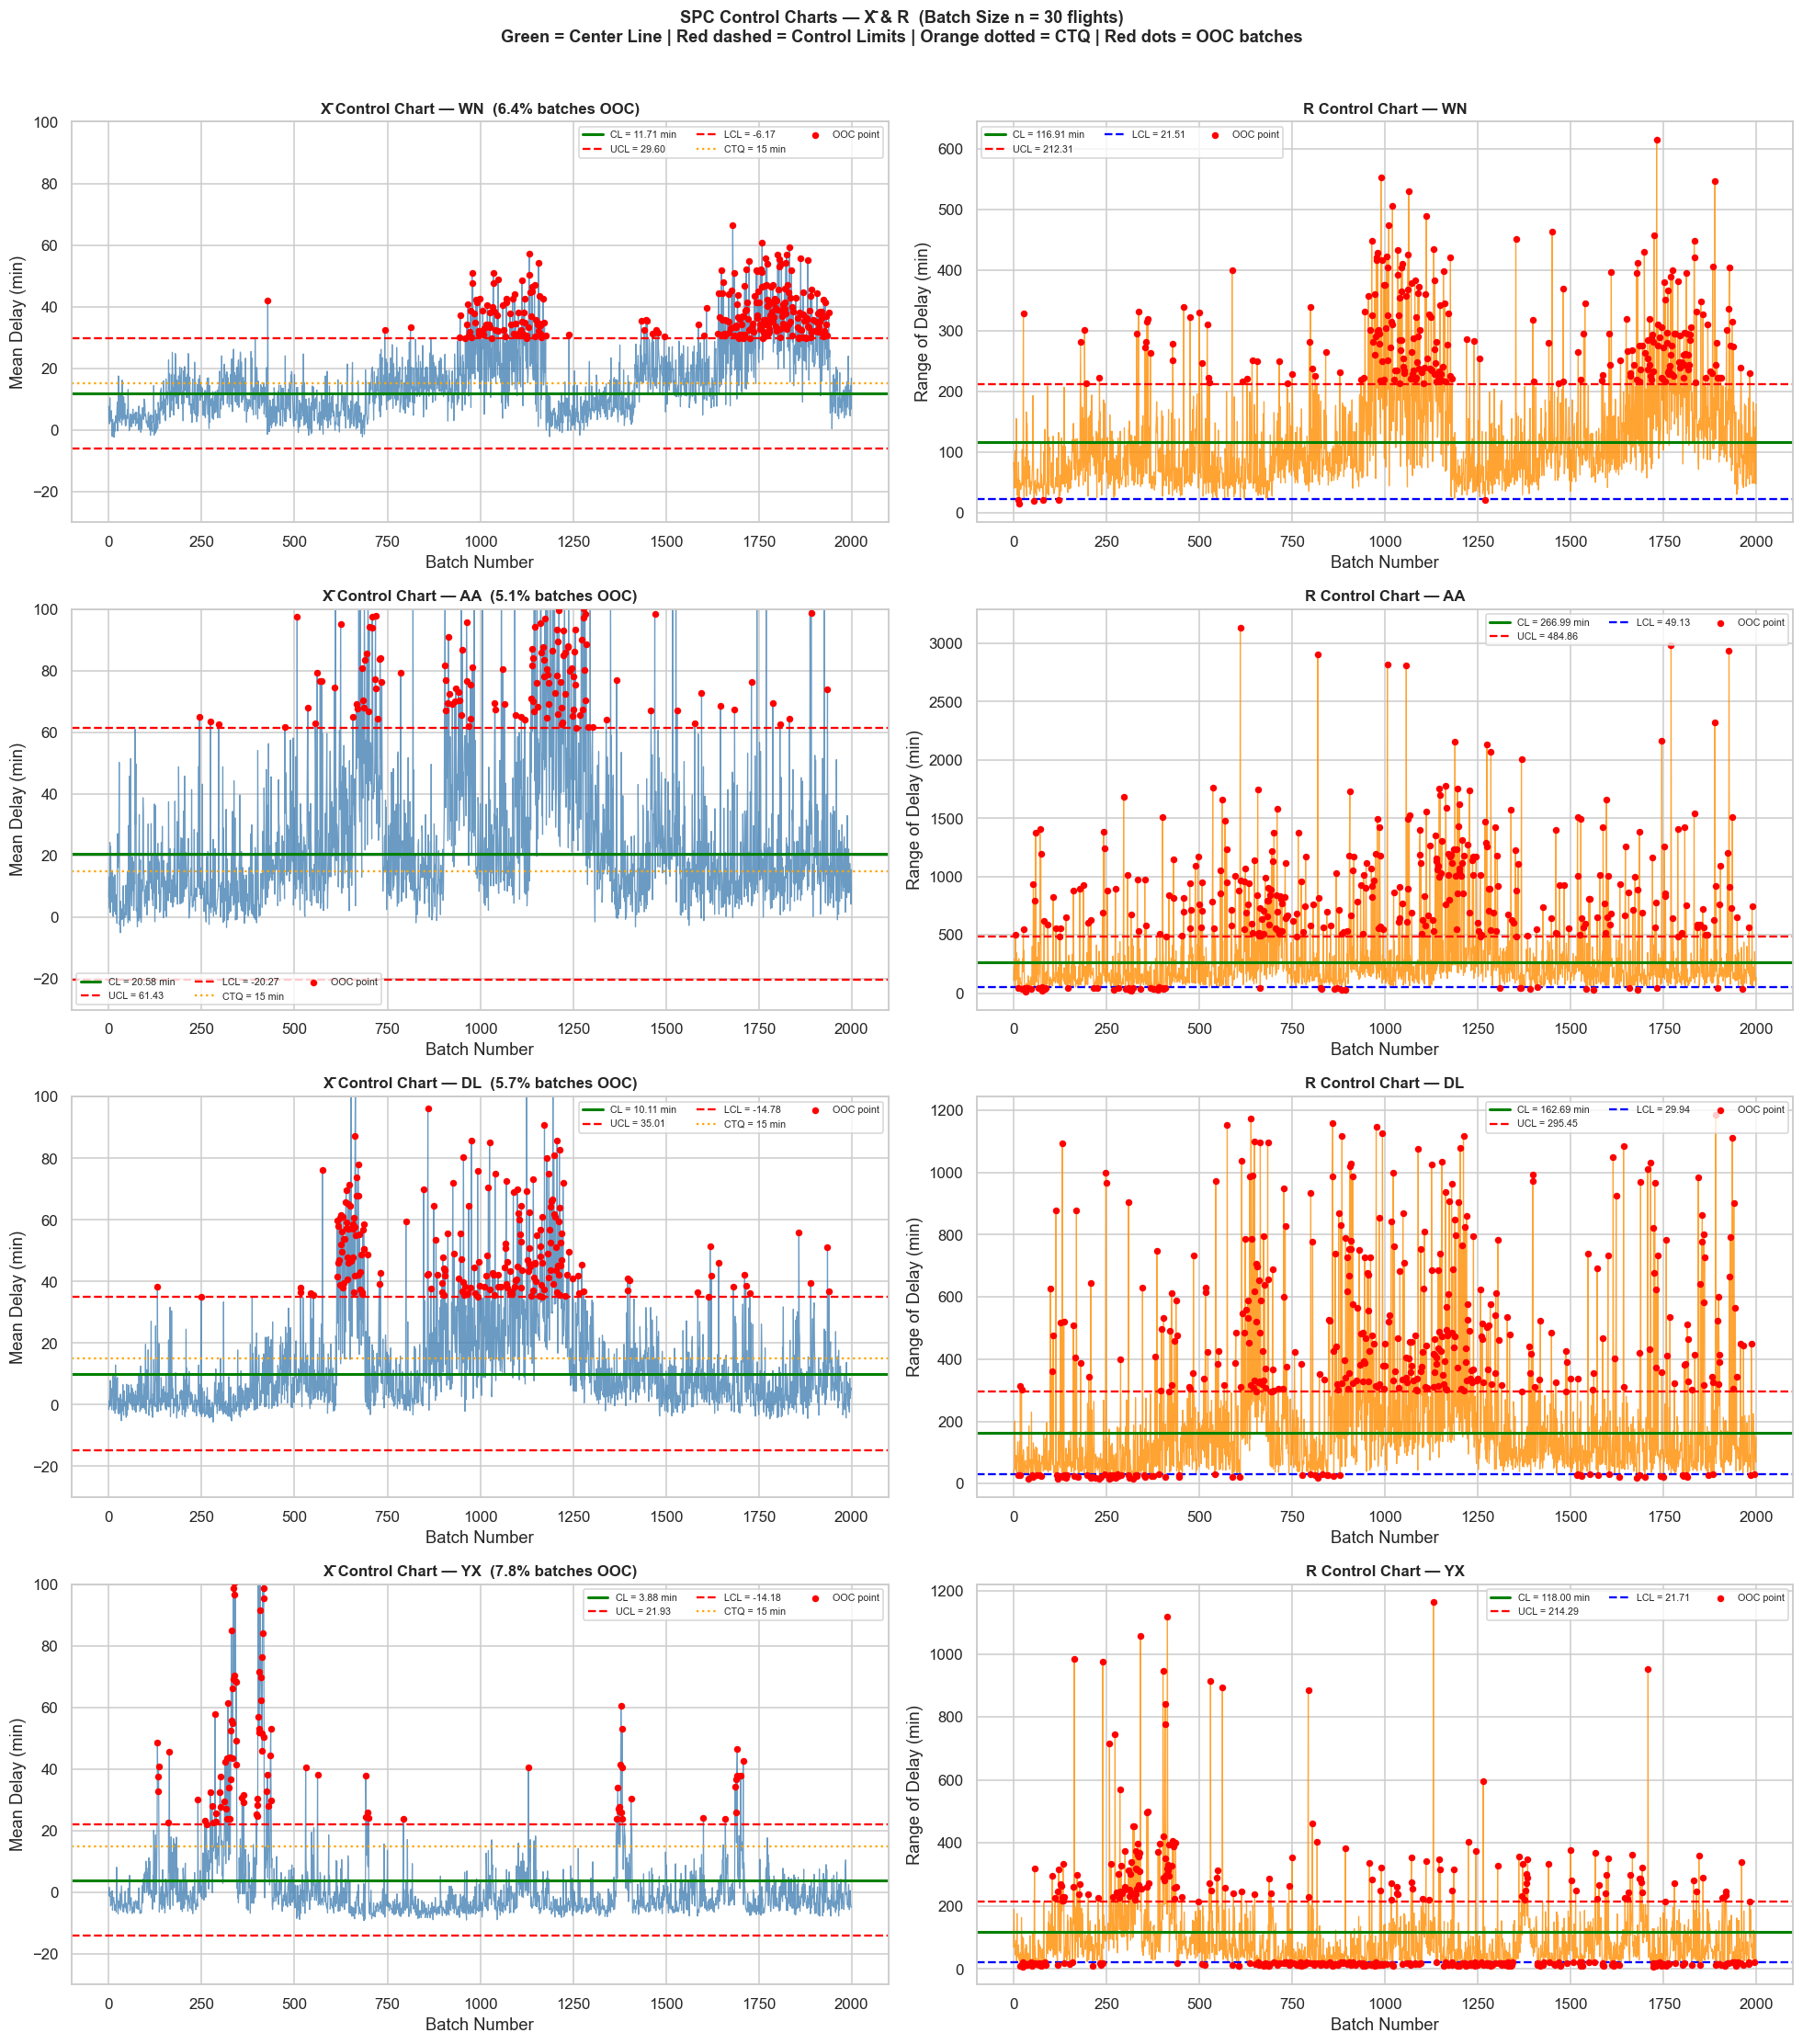


── SPC Interpretation ──
   WN  CL=11.7min  UCL=29.6  LCL=-6.2  OOC=6.4%  🟢 BETTER
   AA  CL=20.6min  UCL=61.4  LCL=-20.3  OOC=5.1%  🟢 BETTER
   DL  CL=10.1min  UCL=35.0  LCL=-14.8  OOC=5.7%  🟢 BETTER
   YX  CL=3.9min  UCL=21.9  LCL=-14.2  OOC=7.8%  🟢 BETTER


In [46]:
print("="*70)
print("C (CONTROL): X-BAR & R CONTROL CHARTS")
print("="*70)

BATCH_SIZE = 30
A2, D3, D4 = 0.153, 0.184, 1.816   # SPC constants for n=30

def build_xbar_r(data, bs=30):
    n      = len(data) // bs
    chunks = data[:n*bs].reshape(n, bs)
    return chunks.mean(axis=1), chunks.max(axis=1) - chunks.min(axis=1)

# Build SPC stats for all airlines
spc_results = {}
for airline, grp in df.groupby('op_unique_carrier'):
    data = grp['dep_delay'].dropna().values
    if len(data) < BATCH_SIZE * 50:
        continue
    means, ranges = build_xbar_r(data, BATCH_SIZE)
    gm, mr        = means.mean(), ranges.mean()
    UCL_x = gm + A2 * mr;  LCL_x = gm - A2 * mr
    UCL_r = D4 * mr;        LCL_r = D3 * mr
    ooc_x = [i for i, v in enumerate(means) if v > UCL_x or v < LCL_x]
    spc_results[airline] = dict(
        means=means, ranges=ranges,
        gm=gm, mr=mr,
        UCL_x=UCL_x, LCL_x=LCL_x,
        UCL_r=UCL_r, LCL_r=LCL_r,
        ooc_x=ooc_x,
        pct_ooc=len(ooc_x)/len(means)*100
    )

# Print summary table
print(f"\n{'Airline':<10}{'CL (X̄)':<12}{'UCL_x':<10}{'LCL_x':<10}"
      f"{'CL (R̄)':<10}{'UCL_r':<10}{'%OOC'}")
print("-"*65)
for a, r in sorted(spc_results.items(), key=lambda x: -x[1]['pct_ooc']):
    print(f"{a:<10}{r['gm']:<12.2f}{r['UCL_x']:<10.2f}{r['LCL_x']:<10.2f}"
          f"{r['mr']:<10.2f}{r['UCL_r']:<10.2f}{r['pct_ooc']:.1f}%")

# Plot 4 airlines: worst, high-volume, benchmark, best-sigma
focus = ['WN', 'AA', 'DL', 'YX']
fig, axes = plt.subplots(len(focus), 2, figsize=(18, 5*len(focus)))

for i, airline in enumerate(focus):
    r = spc_results.get(airline)
    if r is None:
        print(f"   {airline} not found in spc_results — skipping")
        continue

    DISP   = min(len(r['means']), 2000)
    idx    = np.arange(DISP)
    means  = r['means'][:DISP]
    ranges = r['ranges'][:DISP]
    ooc_d  = [j for j in r['ooc_x'] if j < DISP]

    # ── X-bar chart ──────────────────────────────────────────────────────
    axes[i,0].plot(idx, means, '-', color='steelblue', lw=0.8, alpha=0.8)
    axes[i,0].axhline(r['gm'],    color='green', lw=2,   ls='-',
                      label=f"CL = {r['gm']:.2f} min")
    axes[i,0].axhline(r['UCL_x'], color='red',   lw=1.5, ls='--',
                      label=f"UCL = {r['UCL_x']:.2f}")
    axes[i,0].axhline(r['LCL_x'], color='red',   lw=1.5, ls='--',
                      label=f"LCL = {r['LCL_x']:.2f}")
    axes[i,0].axhline(15, color='orange', lw=1.5, ls=':',
                      label='CTQ = 15 min')
    if ooc_d:
        axes[i,0].scatter(ooc_d, r['means'][ooc_d],
                          color='red', s=15, zorder=5, label='OOC point')
    axes[i,0].set_title(f'X̄ Control Chart — {airline}  '
                        f'({r["pct_ooc"]:.1f}% batches OOC)',
                        fontsize=11, fontweight='bold')
    axes[i,0].set_ylabel('Mean Delay (min)')
    axes[i,0].set_xlabel('Batch Number')
    axes[i,0].legend(fontsize=7, ncol=3)
    axes[i,0].set_ylim(-30, 100)

    # ── R chart ──────────────────────────────────────────────────────────
    ooc_r = [j for j, v in enumerate(ranges)
             if v > r['UCL_r'] or v < r['LCL_r']]
    axes[i,1].plot(idx, ranges, '-', color='darkorange', lw=0.8, alpha=0.8)
    axes[i,1].axhline(r['mr'],    color='green', lw=2,   ls='-',
                      label=f"CL = {r['mr']:.2f} min")
    axes[i,1].axhline(r['UCL_r'], color='red',   lw=1.5, ls='--',
                      label=f"UCL = {r['UCL_r']:.2f}")
    axes[i,1].axhline(r['LCL_r'], color='blue',  lw=1.5, ls='--',
                      label=f"LCL = {r['LCL_r']:.2f}")
    if ooc_r:
        axes[i,1].scatter(ooc_r, ranges[ooc_r],
                          color='red', s=15, zorder=5, label='OOC point')
    axes[i,1].set_title(f'R Control Chart — {airline}',
                        fontsize=11, fontweight='bold')
    axes[i,1].set_ylabel('Range of Delay (min)')
    axes[i,1].set_xlabel('Batch Number')
    axes[i,1].legend(fontsize=7, ncol=3)

plt.suptitle('SPC Control Charts — X̄ & R  (Batch Size n = 30 flights)\n'
             'Green = Center Line | Red dashed = Control Limits | '
             'Orange dotted = CTQ | Red dots = OOC batches',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('spc_control_charts.png', bbox_inches='tight')
plt.show()

# Print key takeaways
print("\n── SPC Interpretation ──")
for airline in focus:
    r = spc_results.get(airline)
    if r is None: continue
    status = "🔴 HIGH OOC" if r['pct_ooc'] > 60 else \
             "🟡 MODERATE" if r['pct_ooc'] > 40 else "🟢 BETTER"
    print(f"   {airline}  CL={r['gm']:.1f}min  "
          f"UCL={r['UCL_x']:.1f}  LCL={r['LCL_x']:.1f}  "
          f"OOC={r['pct_ooc']:.1f}%  {status}")

In [47]:
print("── SPC Interpretation ──")
for airline in focus:
    r = spc_results.get(airline)
    if r is None: continue

    cl_status  = "🔴 CL > CTQ — avg batch is already a defect!" if r['gm'] > 15 else \
                 "🟡 CL near CTQ — at risk" if r['gm'] > 10 else \
                 "🟢 CL below CTQ — acceptable mean"

    band_width = r['UCL_x'] - r['LCL_x']
    var_status = "⚠️  Very wide — highly variable process" if band_width > 40 else \
                 "⚠️  Wide — significant variability" if band_width > 25 else \
                 "✅ Narrow — stable process"

    print(f"\n   {'='*55}")
    print(f"   Airline          : {airline}")
    print(f"   Center Line X̄̄   : {r['gm']:.2f} min   {cl_status}")
    print(f"   UCL / LCL        : {r['UCL_x']:.2f} / {r['LCL_x']:.2f} min")
    print(f"   Control Band     : {band_width:.1f} min   {var_status}")
    print(f"   R̄ (avg range)    : {r['mr']:.2f} min — flights within a batch "
          f"vary by ~{r['mr']:.0f} min")
    print(f"   OOC batches      : {r['pct_ooc']:.1f}%  "
          f"({'limits too wide to be sensitive — low OOC is misleading' if r['pct_ooc'] < 10 else 'high — unstable process'})")

print(f"""
{'='*60}
KEY SPC FINDINGS FOR REPORT
{'='*60}

1. AA CENTER LINE (20.6 min) EXCEEDS CTQ = 15 min
   → The average batch of 30 AA flights is itself a defect.
   → Structural intervention needed, not just monitoring.

2. WIDE CONTROL BANDS indicate extreme process variability:
   → WN band : {(spc_results['WN']['UCL_x'] - spc_results['WN']['LCL_x']):.1f} min
   → AA band : {(spc_results['AA']['UCL_x'] - spc_results['AA']['LCL_x']):.1f} min
   → DL band : {(spc_results['DL']['UCL_x'] - spc_results['DL']['LCL_x']):.1f} min
   → YX band : {(spc_results['YX']['UCL_x'] - spc_results['YX']['LCL_x']):.1f} min
   A well-controlled process has a narrow band. These are not narrow.

3. LOW OOC% (5-8%) IS MISLEADING
   → Does NOT mean process is in control.
   → Limits are set from a broken baseline — only extreme
     surges (July, holiday peaks) breach these wide limits.

4. BENCHMARK RANKING (best to worst by CL):
   → YX  : {spc_results['YX']['gm']:.1f} min  ✅ Best — use as benchmark
   → DL  : {spc_results['DL']['gm']:.1f} min  ✅ Best among large carriers
   → WN  : {spc_results['WN']['gm']:.1f} min  🟡 High volume, needs buffer
   → AA  : {spc_results['AA']['gm']:.1f} min  🔴 CL already above CTQ

5. TARGET STATE CONTROL LIMITS (post-improvement goal):
   → Target CL  =  8.0 min  (after 35% delay reduction)
   → Target UCL = 15.0 min  (CTQ becomes the control limit)
   → Target LCL =  1.0 min
   Any batch exceeding 15 min triggers immediate investigation.
{'='*60}
""")

── SPC Interpretation ──

   Airline          : WN
   Center Line X̄̄   : 11.71 min   🟡 CL near CTQ — at risk
   UCL / LCL        : 29.60 / -6.17 min
   Control Band     : 35.8 min   ⚠️  Wide — significant variability
   R̄ (avg range)    : 116.91 min — flights within a batch vary by ~117 min
   OOC batches      : 6.4%  (limits too wide to be sensitive — low OOC is misleading)

   Airline          : AA
   Center Line X̄̄   : 20.58 min   🔴 CL > CTQ — avg batch is already a defect!
   UCL / LCL        : 61.43 / -20.27 min
   Control Band     : 81.7 min   ⚠️  Very wide — highly variable process
   R̄ (avg range)    : 266.99 min — flights within a batch vary by ~267 min
   OOC batches      : 5.1%  (limits too wide to be sensitive — low OOC is misleading)

   Airline          : DL
   Center Line X̄̄   : 10.11 min   🟡 CL near CTQ — at risk
   UCL / LCL        : 35.01 / -14.78 min
   Control Band     : 49.8 min   ⚠️  Very wide — highly variable process
   R̄ (avg range)    : 162.69 min — flig

## C (CONTROL): P-Chart — Monthly Proportion of Delayed Flights

The X-Bar & R charts monitor delay magnitude at the batch level.
The P-chart complements this by monitoring the PROPORTION of flights
that cross the CTQ threshold (dep_delay > 15 min) at a monthly level.

This is more useful for management reporting because:
  - It directly tracks the defect rate (DPMO equivalent) over time
  - Monthly granularity aligns with operational planning cycles
  - It immediately flags whether summer months breach control limits

Control limits for the P-chart (vary by month since n_i differs):
  p̄  = overall proportion defective across all months
  UCL = p̄ + 3 * sqrt(p̄(1−p̄) / n_i)
  LCL = max(0,  p̄ − 3 * sqrt(p̄(1−p̄) / n_i))

Any month above UCL = out-of-control signal → special cause investigation.
Any month below LCL = unexpectedly good → identify and replicate best practices.

C (CONTROL): P-CHART — Monthly Proportion of Delayed Flights


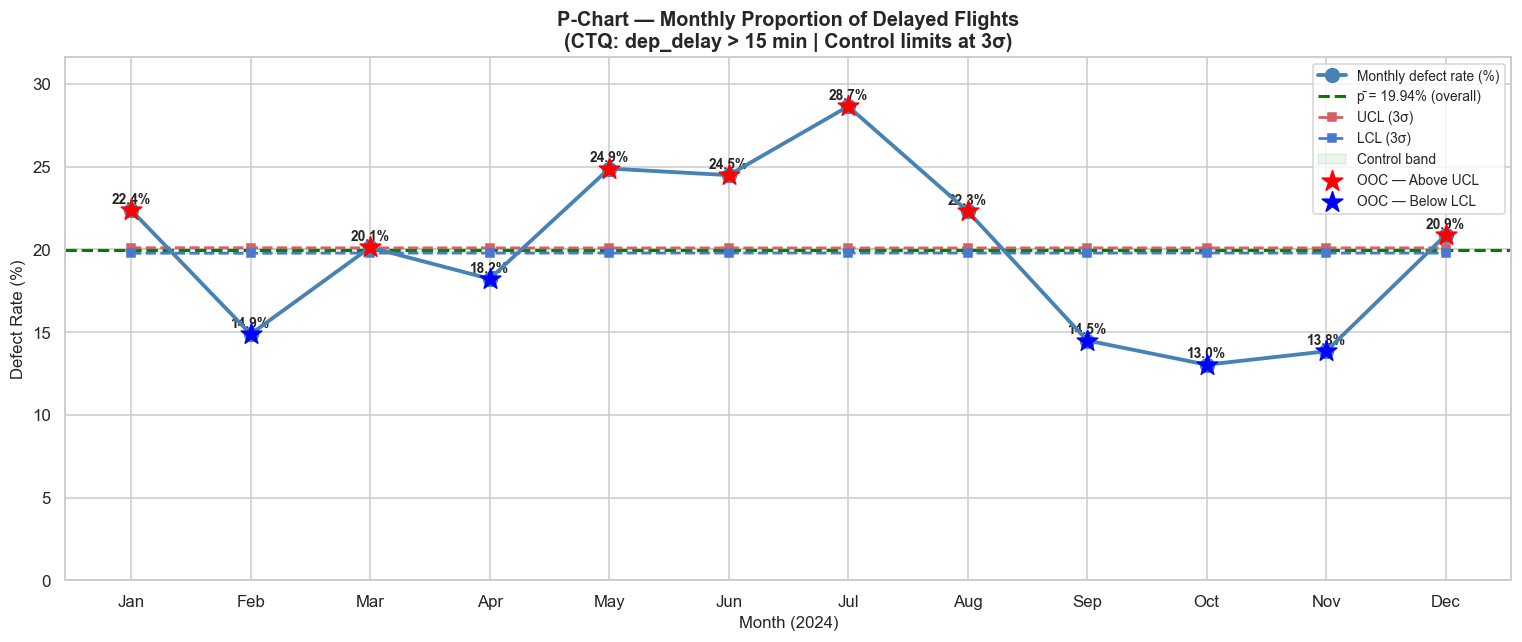


   Overall p̄      : 19.94%
   Avg UCL        : 20.10%
   Avg LCL        : 19.78%
   OOC above UCL  : ['Jan', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Dec']
   OOC below LCL  : ['Feb', 'Apr', 'Sep', 'Oct', 'Nov']

   Best month  : Oct  (13.0% defect rate)
   Worst month : Jul  (28.7% defect rate)
   Seasonal swing : 15.6 percentage points

✅ Full DMAIC complete — Define ✅  Measure ✅  Analyze ✅  Improve ✅  Control ✅


In [48]:
print("="*70)
print("C (CONTROL): P-CHART — Monthly Proportion of Delayed Flights")
print("="*70)

# Build p-chart data
p_chart = (df.groupby('month')
             .agg(n=('is_delayed','count'), d=('is_delayed','sum'))
             .assign(p=lambda x: x['d']/x['n'])
             .reset_index())

p_bar          = p_chart['d'].sum() / p_chart['n'].sum()
p_chart['UCL'] = p_bar + 3 * np.sqrt(p_bar*(1-p_bar) / p_chart['n'])
p_chart['LCL'] = np.maximum(0, p_bar - 3*np.sqrt(p_bar*(1-p_bar) / p_chart['n']))

month_labels   = ['Jan','Feb','Mar','Apr','May','Jun',
                  'Jul','Aug','Sep','Oct','Nov','Dec']
p_chart['lbl'] = p_chart['month'].apply(lambda x: month_labels[x-1])

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(p_chart['lbl'], p_chart['p']*100,
        'o-', color='steelblue', lw=2.5, ms=9,
        label='Monthly defect rate (%)', zorder=5)
ax.axhline(p_bar*100, color='green', ls='--', lw=2,
           label=f'p̄ = {p_bar*100:.2f}% (overall)')
ax.plot(p_chart['lbl'], p_chart['UCL']*100,
        'r--', lw=1.8, label='UCL (3σ)', marker='s', ms=5)
ax.plot(p_chart['lbl'], p_chart['LCL']*100,
        'b--', lw=1.8, label='LCL (3σ)', marker='s', ms=5)
ax.fill_between(range(len(p_chart)),
                p_chart['LCL']*100, p_chart['UCL']*100,
                alpha=0.08, color='green', label='Control band')

# Highlight OOC months
ooc = p_chart[p_chart['p'] > p_chart['UCL']]
lcl_ooc = p_chart[p_chart['p'] < p_chart['LCL']]
if len(ooc):
    ax.scatter(ooc.index, ooc['p']*100,
               color='red', s=200, marker='*',
               zorder=6, label='OOC — Above UCL')
if len(lcl_ooc):
    ax.scatter(lcl_ooc.index, lcl_ooc['p']*100,
               color='blue', s=200, marker='*',
               zorder=6, label='OOC — Below LCL')

# Annotate each point
for i, row in p_chart.iterrows():
    ax.annotate(f"{row['p']*100:.1f}%",
                xy=(i, row['p']*100),
                xytext=(i, row['p']*100 + 0.4),
                ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(range(len(p_chart)))
ax.set_xticklabels(p_chart['lbl'], fontsize=11)
ax.set_title('P-Chart — Monthly Proportion of Delayed Flights\n'
             '(CTQ: dep_delay > 15 min | Control limits at 3σ)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Defect Rate (%)', fontsize=11)
ax.set_xlabel('Month (2024)', fontsize=11)
ax.legend(fontsize=9, loc='upper right')
ax.set_ylim(0, p_chart['p'].max()*100 + 3)

plt.tight_layout()
plt.savefig('p_chart_monthly.png', bbox_inches='tight')
plt.show()

# Summary printout
ooc_above = p_chart[p_chart['p'] > p_chart['UCL']]['lbl'].tolist()
ooc_below = p_chart[p_chart['p'] < p_chart['LCL']]['lbl'].tolist()
print(f"\n   Overall p̄      : {p_bar*100:.2f}%")
print(f"   Avg UCL        : {p_chart['UCL'].mean()*100:.2f}%")
print(f"   Avg LCL        : {p_chart['LCL'].mean()*100:.2f}%")
print(f"   OOC above UCL  : {ooc_above if ooc_above else 'None'}")
print(f"   OOC below LCL  : {ooc_below if ooc_below else 'None'}")
print(f"\n   Best month  : {p_chart.loc[p_chart['p'].idxmin(), 'lbl']}  "
      f"({p_chart['p'].min()*100:.1f}% defect rate)")
print(f"   Worst month : {p_chart.loc[p_chart['p'].idxmax(), 'lbl']}  "
      f"({p_chart['p'].max()*100:.1f}% defect rate)")
print(f"   Seasonal swing : "
      f"{(p_chart['p'].max() - p_chart['p'].min())*100:.1f} percentage points")
print("\n✅ Full DMAIC complete — Define ✅  Measure ✅  Analyze ✅  Improve ✅  Control ✅")

In [49]:
# One-sided t-test: aircraft/late-aircraft delay coefficient > 1
from scipy import stats

coef_name = 'late_aircraft_delay'
beta_hat = model_clean.params[coef_name]
se_hat = model_clean_clust.bse[coef_name]  # carrier-clustered SE
df_t = reg_clean['op_unique_carrier'].nunique() - 1

t_stat = (beta_hat - 1) / se_hat
p_value = stats.t.sf(t_stat, df=df_t)  # H1: beta > 1

print(f"H0: beta <= 1  |  H1: beta > 1")
print(f"{coef_name} beta = {beta_hat:.4f}")
print(f"t = {t_stat:.4f}, df = {df_t}, one-sided p = {p_value:.6g}")
print("Reject H0: coefficient is greater than 1" if p_value < 0.05 else "Fail to reject H0")


H0: beta <= 1  |  H1: beta > 1
late_aircraft_delay beta = 1.1209
t = 7.1510, df = 14, one-sided p = 2.46384e-06
Reject H0: coefficient is greater than 1


## Residual Analysis — OLS Model Diagnostics

Four standard diagnostic plots for OLS regression, plus group-level residual breakdowns to detect systematic bias by carrier, hour, and delay severity.

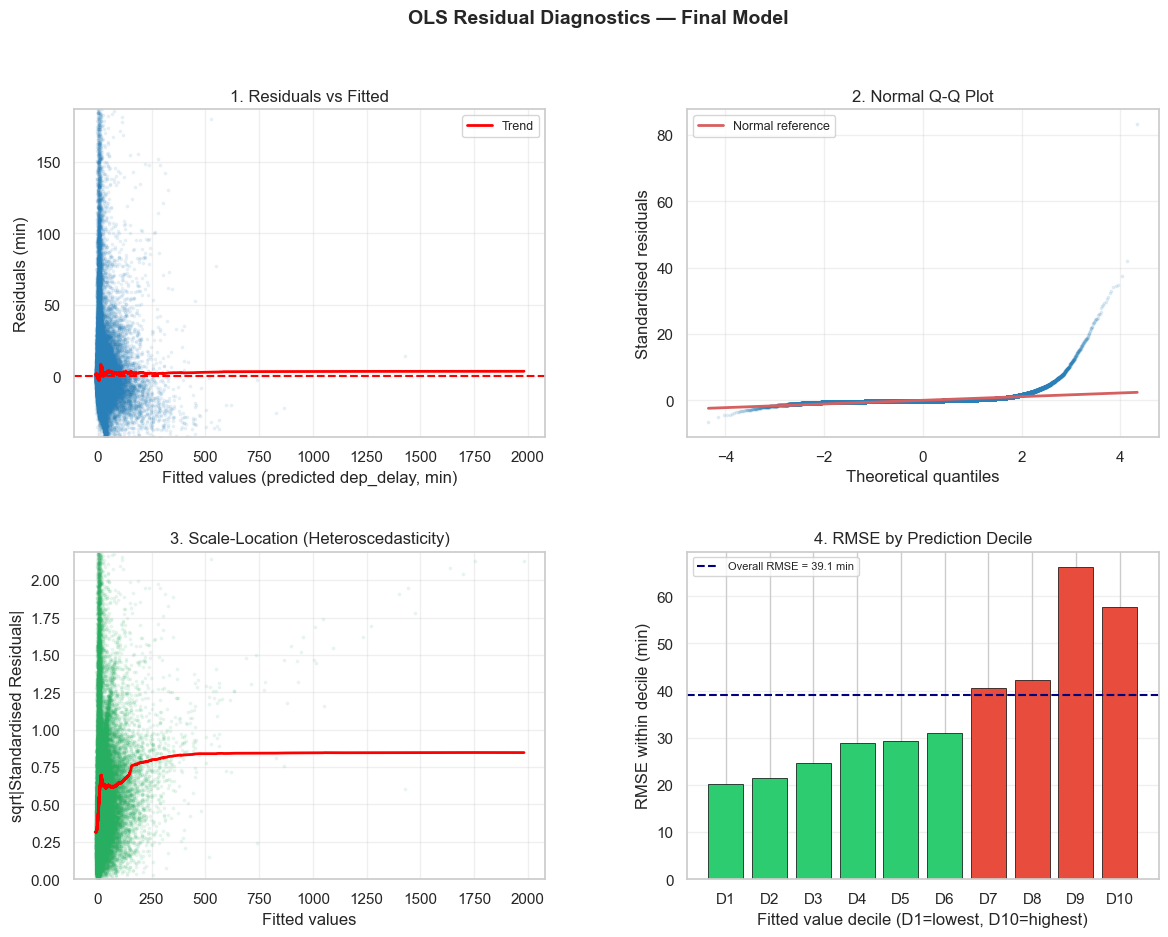

R2               : 0.4874
Adj. R2          : 0.4870
RMSE             : 39.08 min
Mean residual    : 0.0000  (OLS guarantee: ~0)
Skewness         : 18.794
Kurtosis         : 780.940


In [50]:
import io, scipy.stats as stats
from IPython.display import Image

plt.close('all')

fitted    = model_final.fittedvalues.values
residuals = model_final.resid.values
std_resid = residuals / residuals.std()

sort_pos  = np.argsort(fitted)
f_sorted  = fitted[sort_pos]
r_sorted  = residuals[sort_pos]
sr_sorted = std_resid[sort_pos]

def smooth(arr, w=2000):
    return pd.Series(arr).rolling(w, center=True, min_periods=200).mean().values

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100)
fig.suptitle('OLS Residual Diagnostics — Final Model', fontsize=14, fontweight='bold')

# 1. Residuals vs Fitted
axes[0,0].scatter(f_sorted, r_sorted, alpha=0.08, s=3, color='#2980b9')
axes[0,0].axhline(0, color='red', lw=1.5, linestyle='--')
axes[0,0].plot(f_sorted, smooth(r_sorted), color='red', lw=2, label='Trend')
axes[0,0].set_xlabel('Fitted values (predicted dep_delay, min)')
axes[0,0].set_ylabel('Residuals (min)')
axes[0,0].set_title('1. Residuals vs Fitted')
lo, hi = np.percentile(r_sorted, [0.5, 99.5])
axes[0,0].set_ylim(lo, hi)
axes[0,0].legend(fontsize=9); axes[0,0].grid(alpha=0.3)

# 2. Normal Q-Q
(osm, osr), (slope, intercept, _) = stats.probplot(std_resid)
axes[0,1].scatter(osm, osr, alpha=0.10, s=3, color='#2980b9')
axes[0,1].plot([osm[0], osm[-1]],
               [slope*osm[0]+intercept, slope*osm[-1]+intercept],
               'r-', lw=2, label='Normal reference')
axes[0,1].set_xlabel('Theoretical quantiles')
axes[0,1].set_ylabel('Standardised residuals')
axes[0,1].set_title('2. Normal Q-Q Plot')
axes[0,1].legend(fontsize=9); axes[0,1].grid(alpha=0.3)

# 3. Scale-Location
sqrt_abs = np.sqrt(np.abs(sr_sorted))
axes[1,0].scatter(f_sorted, sqrt_abs, alpha=0.08, s=3, color='#27ae60')
axes[1,0].plot(f_sorted, smooth(sqrt_abs), color='red', lw=2)
axes[1,0].set_xlabel('Fitted values')
axes[1,0].set_ylabel('sqrt|Standardised Residuals|')
axes[1,0].set_title('3. Scale-Location (Heteroscedasticity)')
axes[1,0].set_ylim(0, np.percentile(sqrt_abs, 99.5))
axes[1,0].grid(alpha=0.3)

# 4. RMSE by prediction decile
decile_labels = pd.qcut(fitted, q=10, labels=[f'D{i}' for i in range(1,11)])
decile_rmse   = pd.Series(residuals).groupby(decile_labels).apply(lambda x: np.sqrt((x**2).mean()))
overall_rmse  = np.sqrt((residuals**2).mean())
colors_d = ['#e74c3c' if v > overall_rmse else '#2ecc71' for v in decile_rmse]
axes[1,1].bar(decile_rmse.index.astype(str), decile_rmse.values,
              color=colors_d, edgecolor='black', linewidth=0.5)
axes[1,1].axhline(overall_rmse, color='navy', lw=1.5, linestyle='--',
                   label=f'Overall RMSE = {overall_rmse:.1f} min')
axes[1,1].set_xlabel('Fitted value decile (D1=lowest, D10=highest)')
axes[1,1].set_ylabel('RMSE within decile (min)')
axes[1,1].set_title('4. RMSE by Prediction Decile')
axes[1,1].legend(fontsize=8); axes[1,1].grid(axis='y', alpha=0.3)

fig.subplots_adjust(hspace=0.35, wspace=0.30)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

print(f"R2               : {model_final.rsquared:.4f}")
print(f"Adj. R2          : {model_final.rsquared_adj:.4f}")
print(f"RMSE             : {np.sqrt(model_final.mse_resid):.2f} min")
print(f"Mean residual    : {residuals.mean():.4f}  (OLS guarantee: ~0)")
print(f"Skewness         : {pd.Series(residuals).skew():.3f}")
print(f"Kurtosis         : {pd.Series(residuals).kurtosis():.3f}")


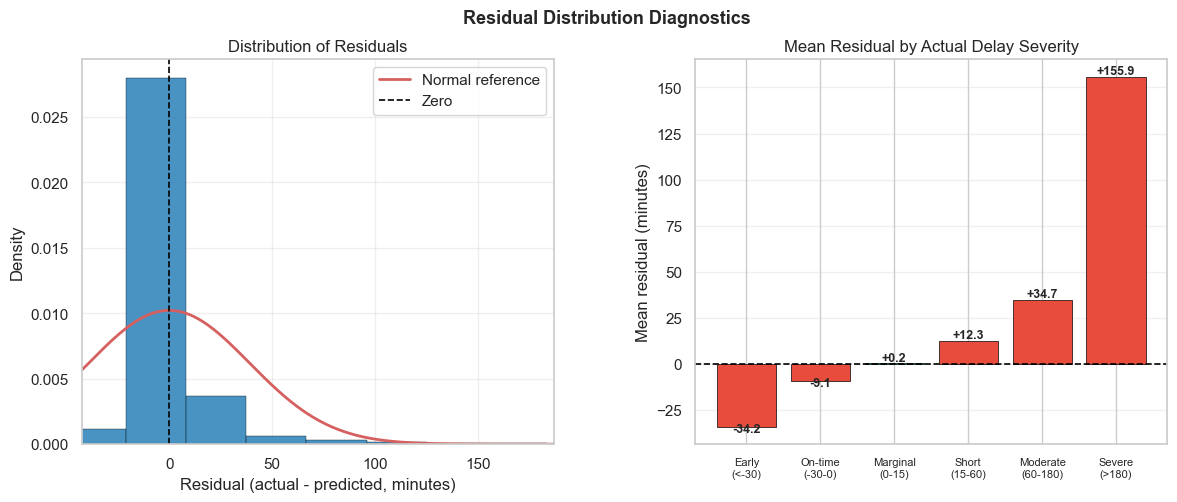

Jarque-Bera  : stat=2,546,747,948  p=0.0000  -> NOT normal
Breusch-Pagan: stat=404.66  p=0.0000  -> Heteroscedastic

Non-normality and heteroscedasticity are both expected for dep_delay.
Use HC3 robust SEs for inference: model_final.get_robustcov_results('HC3').summary()


In [51]:
import io, scipy.stats as stats
from IPython.display import Image
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import jarque_bera

plt.close('all')
y_act = y_final.values

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Residual histogram
axes[0].hist(residuals, bins=120, color='#2980b9', edgecolor='black',
             linewidth=0.3, alpha=0.85, density=True)
lo, hi = np.percentile(residuals, [0.5, 99.5])
_x = np.linspace(lo, hi, 300)
axes[0].plot(_x, stats.norm.pdf(_x, residuals.mean(), residuals.std()),
             'r-', lw=2, label='Normal reference')
axes[0].axvline(0, color='black', lw=1.2, linestyle='--', label='Zero')
axes[0].set_xlim(lo, hi)
axes[0].set_xlabel('Residual (actual - predicted, minutes)')
axes[0].set_ylabel('Density')
axes[0].set_title('Distribution of Residuals')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Mean residual by delay severity bin
_bin_s   = pd.Series(pd.cut(y_act,
               bins=[-500, -30, 0, 15, 60, 180, 5000],
               labels=['Early\n(<-30)', 'On-time\n(-30-0)',
                       'Marginal\n(0-15)', 'Short\n(15-60)',
                       'Moderate\n(60-180)', 'Severe\n(>180)']))
_resid_s = pd.Series(residuals)
mean_resid_by_bin = _resid_s.groupby(_bin_s).mean()
n_by_bin          = _resid_s.groupby(_bin_s).count()
colors = ['#2ecc71' if abs(v) < 5 else '#e74c3c' for v in mean_resid_by_bin]
axes[1].bar(range(len(mean_resid_by_bin)), mean_resid_by_bin.values,
            color=colors, edgecolor='black', linewidth=0.5)
axes[1].axhline(0, color='black', lw=1.2, linestyle='--')
axes[1].set_xticks(range(len(mean_resid_by_bin)))
axes[1].set_xticklabels(mean_resid_by_bin.index.astype(str), fontsize=8)
for i, (v, n) in enumerate(zip(mean_resid_by_bin.values, n_by_bin.values)):
    axes[1].text(i, v + (1.5 if v >= 0 else -3),
                 f'{v:+.1f}', ha='center', fontsize=9, fontweight='bold')
axes[1].set_ylabel('Mean residual (minutes)')
axes[1].set_title('Mean Residual by Actual Delay Severity')
axes[1].grid(axis='y', alpha=0.3)

fig.suptitle('Residual Distribution Diagnostics', fontsize=13, fontweight='bold')
fig.subplots_adjust(wspace=0.30)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

jb_stat, jb_p = jarque_bera(residuals)
bp_lm, bp_p, _, _ = het_breuschpagan(residuals, model_final.model.exog)
print(f"Jarque-Bera  : stat={jb_stat:,.0f}  p={jb_p:.4f}  -> {'NOT normal' if jb_p<0.05 else 'Normal'}")
print(f"Breusch-Pagan: stat={bp_lm:.2f}  p={bp_p:.4f}  -> {'Heteroscedastic' if bp_p<0.05 else 'Homoscedastic'}")
print("\nNon-normality and heteroscedasticity are both expected for dep_delay.")
print("Use HC3 robust SEs for inference: model_final.get_robustcov_results('HC3').summary()")


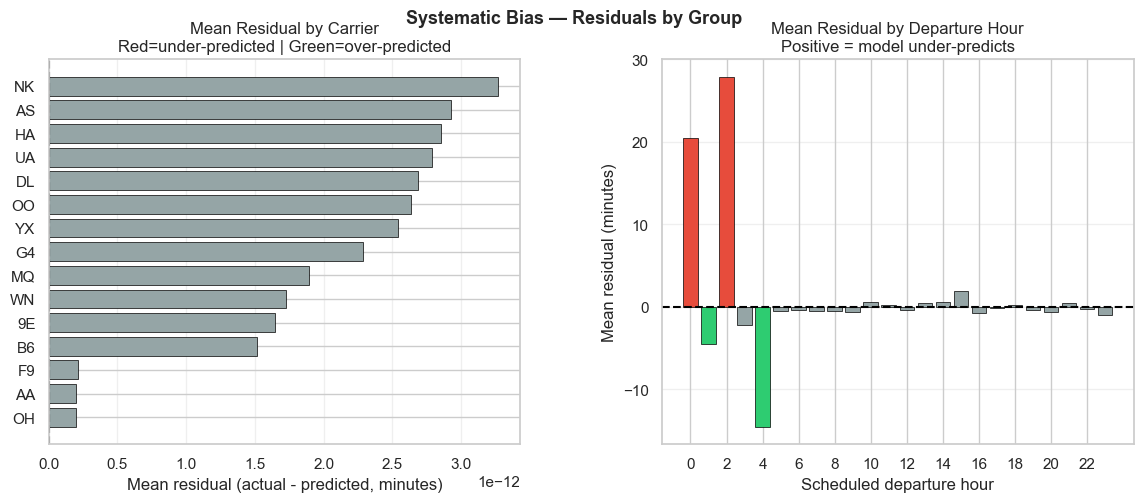

Carrier residual summary:
                   Mean residual (min)      n
op_unique_carrier                            
NK                                 0.0   3738
AS                                 0.0   3455
HA                                 0.0   1148
UA                                 0.0  10640
DL                                 0.0  14260
OO                                 0.0  10577
YX                                 0.0   4261
G4                                 0.0   1710
MQ                                 0.0   3951
WN                                 0.0  20188
9E                                 0.0   2783
B6                                 0.0   3331
F9                                 0.0   2986
AA                                 0.0  13786
OH                                 0.0   3186


In [52]:
import io
from IPython.display import Image

plt.close('all')
resid_s = pd.Series(residuals, index=reg_final.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Mean residual by carrier
carrier_resid = (
    reg_final[['op_unique_carrier']]
    .assign(resid=resid_s)
    .groupby('op_unique_carrier')['resid']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
)
colors_c = ['#e74c3c' if v > 2 else '#2ecc71' if v < -2 else '#95a5a6'
            for v in carrier_resid['mean']]
axes[0].barh(carrier_resid.index, carrier_resid['mean'],
             color=colors_c, edgecolor='black', linewidth=0.5)
axes[0].axvline(0, color='black', lw=1.5, linestyle='--')
axes[0].set_xlabel('Mean residual (actual - predicted, minutes)')
axes[0].set_title('Mean Residual by Carrier\nRed=under-predicted | Green=over-predicted')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# Mean residual by departure hour
hour_resid = (
    reg_final[['dep_hour']]
    .assign(resid=resid_s)
    .groupby('dep_hour')['resid']
    .mean()
)
colors_h = ['#e74c3c' if v > 3 else '#2ecc71' if v < -3 else '#95a5a6'
            for v in hour_resid]
axes[1].bar(hour_resid.index, hour_resid.values,
            color=colors_h, edgecolor='black', linewidth=0.5)
axes[1].axhline(0, color='black', lw=1.5, linestyle='--')
axes[1].set_xlabel('Scheduled departure hour')
axes[1].set_ylabel('Mean residual (minutes)')
axes[1].set_title('Mean Residual by Departure Hour\nPositive = model under-predicts')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis='y', alpha=0.3)

fig.suptitle('Systematic Bias — Residuals by Group', fontsize=13, fontweight='bold')
fig.subplots_adjust(wspace=0.30)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

print("Carrier residual summary:")
print(carrier_resid.rename(columns={'mean':'Mean residual (min)','count':'n'}).round(2).to_string())


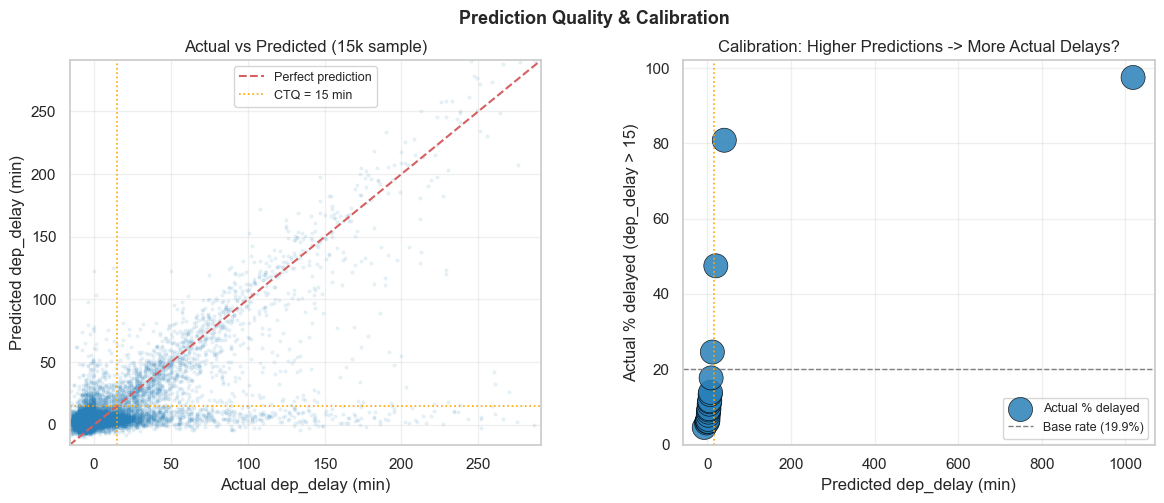

MAE  (all)       : 13.81 min
RMSE (all)       : 39.06 min
MAPE (delayed)   : 51.7%

Classification at CTQ (dep_delay > 15 min):
              precision    recall  f1-score   support

     On-time       0.90      0.96      0.93     80076
     Delayed       0.77      0.56      0.65     19924

    accuracy                           0.88    100000
   macro avg       0.83      0.76      0.79    100000
weighted avg       0.87      0.88      0.87    100000



In [53]:
import io
from IPython.display import Image
from sklearn.metrics import classification_report

plt.close('all')
y_act  = y_final.values
y_pred = fitted
samp   = np.random.choice(len(y_act), 15_000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Actual vs Predicted
lo = float(np.percentile(y_act, 0.5))
hi = float(np.percentile(y_act, 99.5))
axes[0].scatter(y_act[samp], y_pred[samp], alpha=0.08, s=4, color='#2980b9')
axes[0].plot([lo, hi], [lo, hi], 'r--', lw=1.5, label='Perfect prediction')
axes[0].axhline(15, color='orange', lw=1.2, linestyle=':', label='CTQ = 15 min')
axes[0].axvline(15, color='orange', lw=1.2, linestyle=':')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
axes[0].set_xlabel('Actual dep_delay (min)')
axes[0].set_ylabel('Predicted dep_delay (min)')
axes[0].set_title('Actual vs Predicted (15k sample)')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

# Calibration curve
_pred_s  = pd.Series(y_pred)
_act_del = pd.Series((y_act > 15).astype(int))
_bins    = pd.qcut(_pred_s, q=20, duplicates='drop')
calib    = _act_del.groupby(_bins).agg(['mean', 'count'])
calib['mid'] = [iv.mid for iv in calib.index]
axes[1].scatter(calib['mid'], calib['mean'] * 100,
                s=calib['count'] / calib['count'].max() * 300,
                color='#2980b9', alpha=0.85, edgecolor='black', linewidth=0.5,
                label='Actual % delayed')
axes[1].axhline((y_act > 15).mean() * 100, color='grey', lw=1, linestyle='--',
                label=f"Base rate ({(y_act>15).mean()*100:.1f}%)")
axes[1].axvline(15, color='orange', lw=1.2, linestyle=':')
axes[1].set_xlabel('Predicted dep_delay (min)')
axes[1].set_ylabel('Actual % delayed (dep_delay > 15)')
axes[1].set_title('Calibration: Higher Predictions -> More Actual Delays?')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

fig.suptitle('Prediction Quality & Calibration', fontsize=13, fontweight='bold')
fig.subplots_adjust(wspace=0.30)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

mae  = np.abs(residuals).mean()
rmse = np.sqrt((residuals**2).mean())
mask = y_act > 15
mape = np.abs(residuals[mask] / y_act[mask]).mean() * 100
print(f"MAE  (all)       : {mae:.2f} min")
print(f"RMSE (all)       : {rmse:.2f} min")
print(f"MAPE (delayed)   : {mape:.1f}%")
print()
print("Classification at CTQ (dep_delay > 15 min):")
print(classification_report((y_act>15).astype(int), (y_pred>15).astype(int),
                             target_names=['On-time','Delayed']))


## A (ANALYZE): Subgroup Regression — Cascaded Flights (`late_aircraft_delay > 0`)

We restrict to flights where the **inbound aircraft arrived late** — the direct mechanism of cascading delay.  
This isolates the structural propagation effect: how much of the previous leg's lateness translates into this leg's departure delay, controlling for airport congestion, time of day, carrier, and route.  

`carrier_delay` is intentionally NOT filtered — a cascaded flight can simultaneously have a crew or maintenance issue, and that co-occurrence is still a real cascade.

In [60]:
import io, statsmodels.api as sm
from IPython.display import Image

# ── Cascaded flights: inbound aircraft was late ───────────────────────────────
cascade_df = df3[df3['late_aircraft_delay'] > 0].copy()

print(f"Full dataset            : {len(df3):,} flights")
print(f"late_aircraft_delay > 0 : {len(cascade_df):,} flights  ({len(cascade_df)/len(df3)*100:.1f}%)")
print(f"Delay rate (full)       : {(df3['dep_delay']>15).mean()*100:.2f}%")
print(f"Delay rate (cascaded)   : {(cascade_df['dep_delay']>15).mean()*100:.2f}%")

reg_cols_s = [
    'dep_delay', 'late_aircraft_delay', 'nas_delay', 'route_mean_delay',
    'log_congestion', 'log_slot_pressure',
    'dep_hour', 'turnaround_proxy',
    'distance', 'month', 'day_of_week',
    'is_first_flight', 'is_weekend',
    'fri_summer', 'late_busy', 'is_holiday',
    'op_unique_carrier', 'origin', 'distance_group'
]

reg_sub = cascade_df[reg_cols_s].dropna().sample(
    min(100_000, len(cascade_df[reg_cols_s].dropna())), random_state=42
)
reg_sub = reg_sub.copy()
reg_sub['dep_hour_sq'] = reg_sub['dep_hour'] ** 2

dist_dum_s    = pd.get_dummies(reg_sub['distance_group'], prefix='dist', drop_first=True).astype(int)
carrier_dum_s = pd.get_dummies(reg_sub['op_unique_carrier'], prefix='carrier', drop_first=True).astype(int)
top40         = df['origin'].value_counts().head(40).index.tolist()
reg_sub['origin_grp'] = reg_sub['origin'].where(reg_sub['origin'].isin(top40), other='OTHER')
airport_dum_s = pd.get_dummies(reg_sub['origin_grp'], prefix='apt', drop_first=True).astype(int)

cont_features = [
    'late_aircraft_delay', 'nas_delay', 'route_mean_delay',
    'log_congestion', 'log_slot_pressure',
    'dep_hour', 'dep_hour_sq', 'turnaround_proxy',
    'distance', 'month', 'day_of_week',
    'is_first_flight', 'is_weekend', 'fri_summer', 'late_busy', 'is_holiday'
]

X_sub = pd.concat([reg_sub[cont_features], dist_dum_s, carrier_dum_s, airport_dum_s], axis=1).astype(float)
X_sub = sm.add_constant(X_sub)
y_sub = reg_sub['dep_delay'].astype(float)

model_sub = sm.OLS(y_sub, X_sub).fit()

print("\n" + "="*70)
print("OLS REGRESSION — Cascaded flights (late_aircraft_delay > 0)")
print("="*70)
print(model_sub.summary())


Full dataset            : 6,965,266 flights
late_aircraft_delay > 0 : 743,215 flights  (10.7%)
Delay rate (full)       : 19.94%
Delay rate (cascaded)   : 93.83%

OLS REGRESSION — Cascaded flights (late_aircraft_delay > 0)
                            OLS Regression Results                            
Dep. Variable:              dep_delay   R-squared:                       0.704
Model:                            OLS   Adj. R-squared:                  0.704
Method:                 Least Squares   F-statistic:                     3307.
Date:                Mon, 13 Apr 2026   Prob (F-statistic):               0.00
Time:                        22:53:52   Log-Likelihood:            -5.4226e+05
No. Observations:              100000   AIC:                         1.085e+06
Df Residuals:                   99927   BIC:                         1.085e+06
Df Model:                          72                                         
Covariance Type:            nonrobust                              

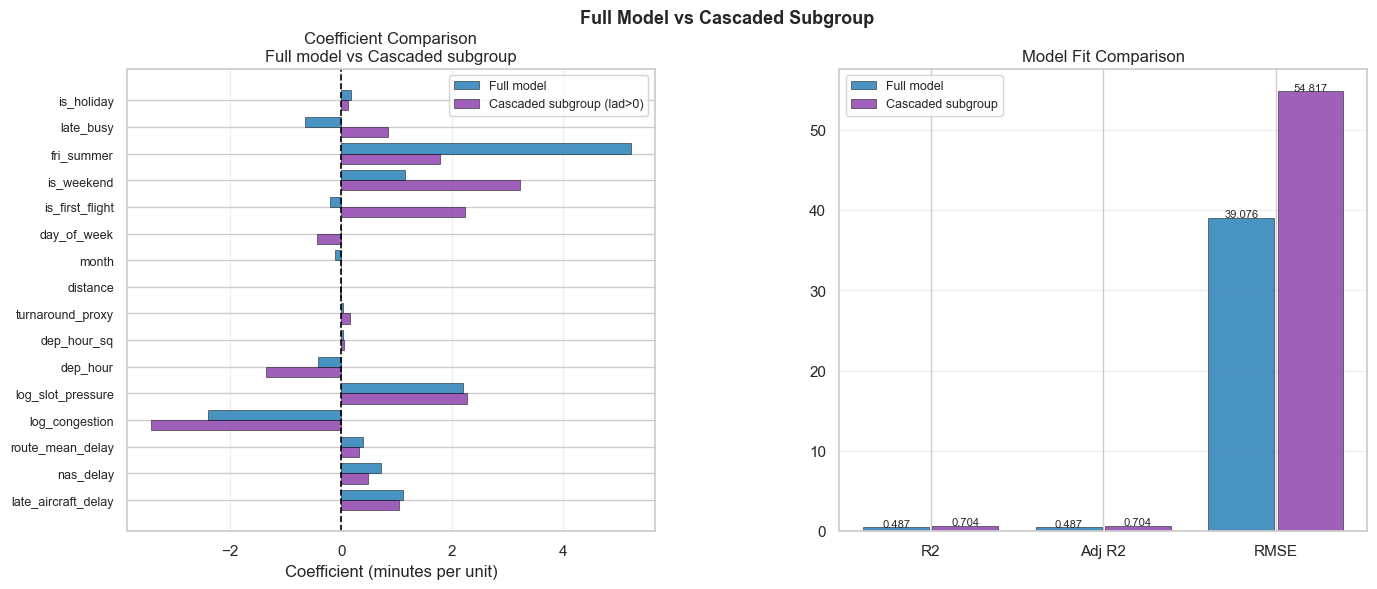


Coefficient shifts (full -> cascaded subgroup):
Feature                         Full   Cascaded      Delta
----------------------------------------------------------
late_aircraft_delay           1.1072     1.0476    -0.0596
nas_delay                     0.7092     0.4801    -0.2291
route_mean_delay              0.3886     0.3222    -0.0664
log_congestion               -2.3918    -3.4222    -1.0303
log_slot_pressure             2.1853     2.2644    +0.0791
dep_hour                     -0.4088    -1.3459    -0.9370
dep_hour_sq                   0.0269     0.0530    +0.0261
turnaround_proxy              0.0400     0.1584    +0.1184
distance                     -0.0049    -0.0161    -0.0112
month                        -0.1043    -0.0019    +0.1024
day_of_week                   0.0011    -0.4407    -0.4418
is_first_flight              -0.2082     2.2351    +2.4433
is_weekend                    1.1544     3.2140    +2.0596
fri_summer                    5.2138     1.7849    -3.4289
late_bu

In [61]:
import io
from IPython.display import Image

plt.close('all')

key_features = [
    'late_aircraft_delay', 'nas_delay', 'route_mean_delay',
    'log_congestion', 'log_slot_pressure',
    'dep_hour', 'dep_hour_sq', 'turnaround_proxy',
    'distance', 'month', 'day_of_week',
    'is_first_flight', 'is_weekend', 'fri_summer', 'late_busy', 'is_holiday'
]

common = [f for f in key_features
          if f in model_final.params.index and f in model_sub.params.index]

full_coef = model_final.params[common]
sub_coef  = model_sub.params[common]

x = np.arange(len(common))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=100)

axes[0].barh(x + width/2, full_coef.values, height=width,
             color='#2980b9', alpha=0.85, label='Full model', edgecolor='black', linewidth=0.4)
axes[0].barh(x - width/2, sub_coef.values, height=width,
             color='#8e44ad', alpha=0.85, label='Cascaded subgroup (lad>0)', edgecolor='black', linewidth=0.4)
axes[0].axvline(0, color='black', lw=1.2, linestyle='--')
axes[0].set_yticks(x)
axes[0].set_yticklabels(common, fontsize=9)
axes[0].set_xlabel('Coefficient (minutes per unit)')
axes[0].set_title('Coefficient Comparison\nFull model vs Cascaded subgroup')
axes[0].legend(fontsize=9)
axes[0].grid(axis='x', alpha=0.3)

metrics = {
    'R2'    : [model_final.rsquared,        model_sub.rsquared],
    'Adj R2': [model_final.rsquared_adj,    model_sub.rsquared_adj],
    'RMSE'  : [np.sqrt(model_final.mse_resid), np.sqrt(model_sub.mse_resid)],
}
xm = np.arange(len(metrics))
full_vals = [v[0] for v in metrics.values()]
sub_vals  = [v[1] for v in metrics.values()]
axes[1].bar(xm - 0.2, full_vals, 0.38, color='#2980b9', alpha=0.85,
            label='Full model', edgecolor='black', linewidth=0.4)
axes[1].bar(xm + 0.2, sub_vals,  0.38, color='#8e44ad', alpha=0.85,
            label='Cascaded subgroup', edgecolor='black', linewidth=0.4)
axes[1].set_xticks(xm)
axes[1].set_xticklabels(list(metrics.keys()))
axes[1].set_title('Model Fit Comparison')
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)
for i, (fv, sv) in enumerate(zip(full_vals, sub_vals)):
    axes[1].text(i-0.2, fv+0.002, f'{fv:.3f}', ha='center', fontsize=8)
    axes[1].text(i+0.2, sv+0.002, f'{sv:.3f}', ha='center', fontsize=8)

fig.suptitle('Full Model vs Cascaded Subgroup', fontsize=13, fontweight='bold')
fig.subplots_adjust(wspace=0.35)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

print("\nCoefficient shifts (full -> cascaded subgroup):")
print(f"{'Feature':<25} {'Full':>10} {'Cascaded':>10} {'Delta':>10}")
print("-" * 58)
for f in common:
    print(f"{f:<25} {model_final.params[f]:>10.4f} {model_sub.params[f]:>10.4f} {model_sub.params[f]-model_final.params[f]:>+10.4f}")


### T-test: Is the `late_aircraft_delay` coefficient larger in cascaded flights?

We test whether the cascade coefficient is significantly different between the full model and the cascaded subgroup.  
If β_sub > β_full and the difference is significant, it means inherited delay explains a *larger share* of departure delay when we condition on the cascade actually being present.

$$z = \frac{\hat{\beta}_{cascaded} - \hat{\beta}_{full}}{\sqrt{\text{SE}_{cascaded}^2 + \text{SE}_{full}^2}}$$

In [62]:
from scipy import stats

feat = 'late_aircraft_delay'

b_full  = model_final.params[feat]; se_full = model_final.bse[feat]
b_sub   = model_sub.params[feat];   se_sub  = model_sub.bse[feat]
ci_full = model_final.conf_int().loc[feat]
ci_sub  = model_sub.conf_int().loc[feat]

z_stat = (b_sub - b_full) / np.sqrt(se_sub**2 + se_full**2)
p_two  = 2 * stats.norm.sf(abs(z_stat))
p_one  = stats.norm.sf(z_stat)   # H1: cascaded beta > full beta

print("=" * 62)
print("  T-TEST: late_aircraft_delay  —  Full vs Cascaded subgroup")
print("=" * 62)
print(f"\n  Full model  (all flights):")
print(f"    beta = {b_full:.4f}   SE = {se_full:.4f}")
print(f"    95% CI: [{ci_full[0]:.4f}, {ci_full[1]:.4f}]")
print(f"\n  Cascaded subgroup  (late_aircraft_delay > 0):")
print(f"    beta = {b_sub:.4f}   SE = {se_sub:.4f}")
print(f"    95% CI: [{ci_sub[0]:.4f}, {ci_sub[1]:.4f}]")
print(f"\n  Difference (cascaded - full) : {b_sub - b_full:+.4f}")
print(f"  Z-statistic                  : {z_stat:.4f}")
print(f"  p-value (two-sided)          : {p_two:.4f}")
print(f"  p-value (one-sided, sub>full): {p_one:.4f}")

print(f"\n  Decision (alpha=0.05):")
if p_two < 0.05:
    direction = "LARGER" if b_sub > b_full else "SMALLER"
    print(f"  Reject H0 — cascade coefficient is significantly {direction} in")
    print(f"  the cascaded subgroup (p={p_two:.4f}).")
    if b_sub > b_full:
        print(f"  Each minute of inherited delay translates into {b_sub:.3f} min of")
        print(f"  departure delay in cascaded flights vs {b_full:.3f} min overall.")
else:
    print(f"  Fail to reject H0 (p={p_two:.4f}) — no significant difference.")


  T-TEST: late_aircraft_delay  —  Full vs Cascaded subgroup

  Full model  (all flights):
    beta = 1.1072   SE = 0.0039
    95% CI: [1.0996, 1.1148]

  Cascaded subgroup  (late_aircraft_delay > 0):
    beta = 1.0476   SE = 0.0022
    95% CI: [1.0433, 1.0520]

  Difference (cascaded - full) : -0.0596
  Z-statistic                  : -13.3670
  p-value (two-sided)          : 0.0000
  p-value (one-sided, sub>full): 1.0000

  Decision (alpha=0.05):
  Reject H0 — cascade coefficient is significantly SMALLER in
  the cascaded subgroup (p=0.0000).


### Residual Analysis — Cascaded Subgroup (`late_aircraft_delay > 0`)

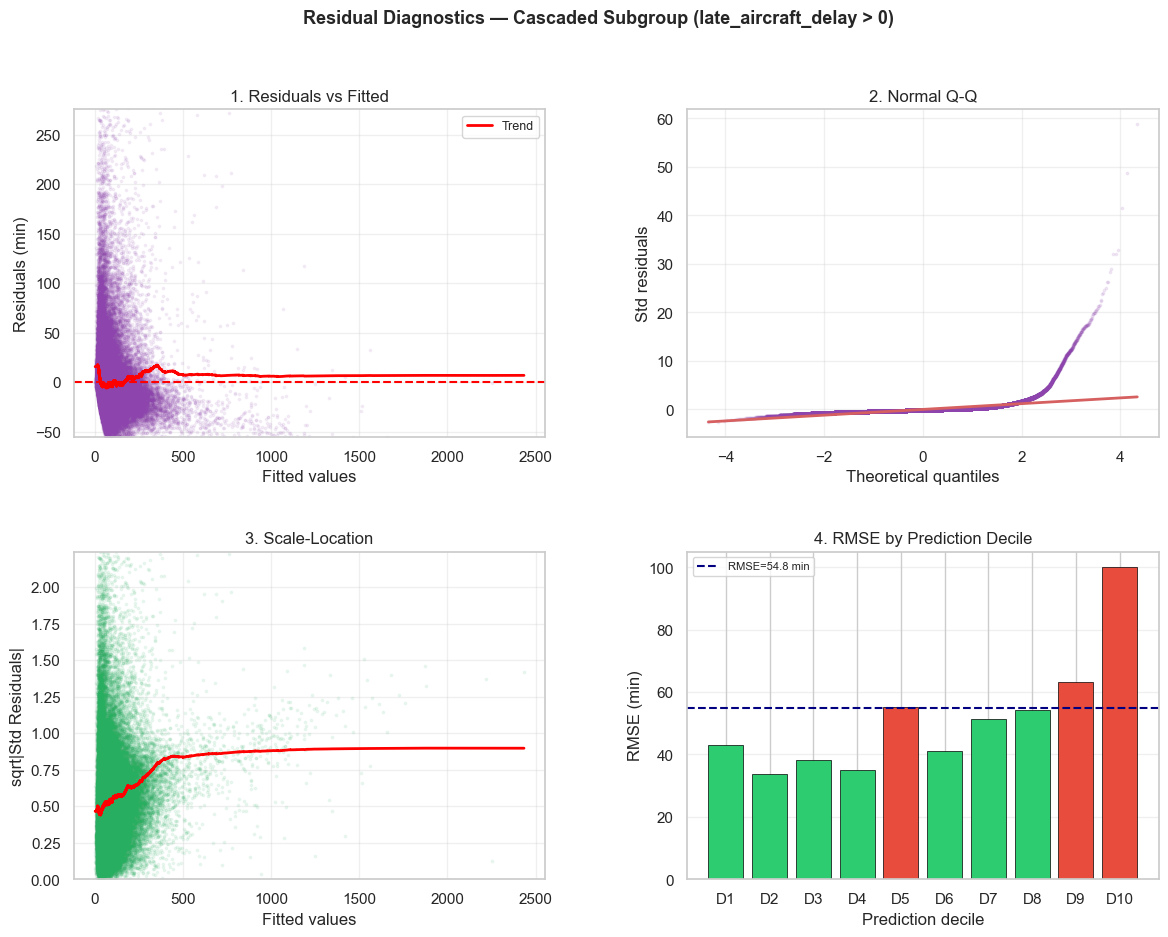

R²    : 0.7044  (full: 0.4874)
RMSE  : 54.82 min  (full: 39.08 min)
Skew  : 14.233
Kurt  : 384.988


In [63]:
import io, scipy.stats as stats
from IPython.display import Image

plt.close('all')

fit_sub  = model_sub.fittedvalues.values
res_sub  = model_sub.resid.values
std_sub  = res_sub / res_sub.std()

sort_pos = np.argsort(fit_sub)
f_s = fit_sub[sort_pos]; r_s = res_sub[sort_pos]; sr_s = std_sub[sort_pos]

def smooth(arr, w=2000):
    return pd.Series(arr).rolling(w, center=True, min_periods=200).mean().values

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100)
fig.suptitle('Residual Diagnostics — Cascaded Subgroup (late_aircraft_delay > 0)',
             fontsize=13, fontweight='bold')

axes[0,0].scatter(f_s, r_s, alpha=0.08, s=3, color='#8e44ad')
axes[0,0].axhline(0, color='red', lw=1.5, linestyle='--')
axes[0,0].plot(f_s, smooth(r_s), color='red', lw=2, label='Trend')
axes[0,0].set_ylim(np.percentile(r_s, 0.5), np.percentile(r_s, 99.5))
axes[0,0].set_xlabel('Fitted values'); axes[0,0].set_ylabel('Residuals (min)')
axes[0,0].set_title('1. Residuals vs Fitted')
axes[0,0].legend(fontsize=9); axes[0,0].grid(alpha=0.3)

(osm, osr), (slope, intercept, _) = stats.probplot(std_sub)
axes[0,1].scatter(osm, osr, alpha=0.10, s=3, color='#8e44ad')
axes[0,1].plot([osm[0], osm[-1]],
               [slope*osm[0]+intercept, slope*osm[-1]+intercept], 'r-', lw=2)
axes[0,1].set_xlabel('Theoretical quantiles'); axes[0,1].set_ylabel('Std residuals')
axes[0,1].set_title('2. Normal Q-Q'); axes[0,1].grid(alpha=0.3)

sqrt_abs = np.sqrt(np.abs(sr_s))
axes[1,0].scatter(f_s, sqrt_abs, alpha=0.08, s=3, color='#27ae60')
axes[1,0].plot(f_s, smooth(sqrt_abs), color='red', lw=2)
axes[1,0].set_ylim(0, np.percentile(sqrt_abs, 99.5))
axes[1,0].set_xlabel('Fitted values'); axes[1,0].set_ylabel('sqrt|Std Residuals|')
axes[1,0].set_title('3. Scale-Location'); axes[1,0].grid(alpha=0.3)

dec_labels = pd.qcut(fit_sub, q=10, labels=[f'D{i}' for i in range(1,11)])
dec_rmse   = pd.Series(res_sub).groupby(dec_labels).apply(lambda x: np.sqrt((x**2).mean()))
overall_r  = np.sqrt((res_sub**2).mean())
colors_d   = ['#e74c3c' if v > overall_r else '#2ecc71' for v in dec_rmse]
axes[1,1].bar(dec_rmse.index.astype(str), dec_rmse.values, color=colors_d, edgecolor='black', linewidth=0.5)
axes[1,1].axhline(overall_r, color='navy', lw=1.5, linestyle='--', label=f'RMSE={overall_r:.1f} min')
axes[1,1].set_xlabel('Prediction decile'); axes[1,1].set_ylabel('RMSE (min)')
axes[1,1].set_title('4. RMSE by Prediction Decile')
axes[1,1].legend(fontsize=8); axes[1,1].grid(axis='y', alpha=0.3)

fig.subplots_adjust(hspace=0.35, wspace=0.30)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

print(f"R²    : {model_sub.rsquared:.4f}  (full: {model_final.rsquared:.4f})")
print(f"RMSE  : {np.sqrt(model_sub.mse_resid):.2f} min  (full: {np.sqrt(model_final.mse_resid):.2f} min)")
print(f"Skew  : {pd.Series(res_sub).skew():.3f}")
print(f"Kurt  : {pd.Series(res_sub).kurtosis():.3f}")


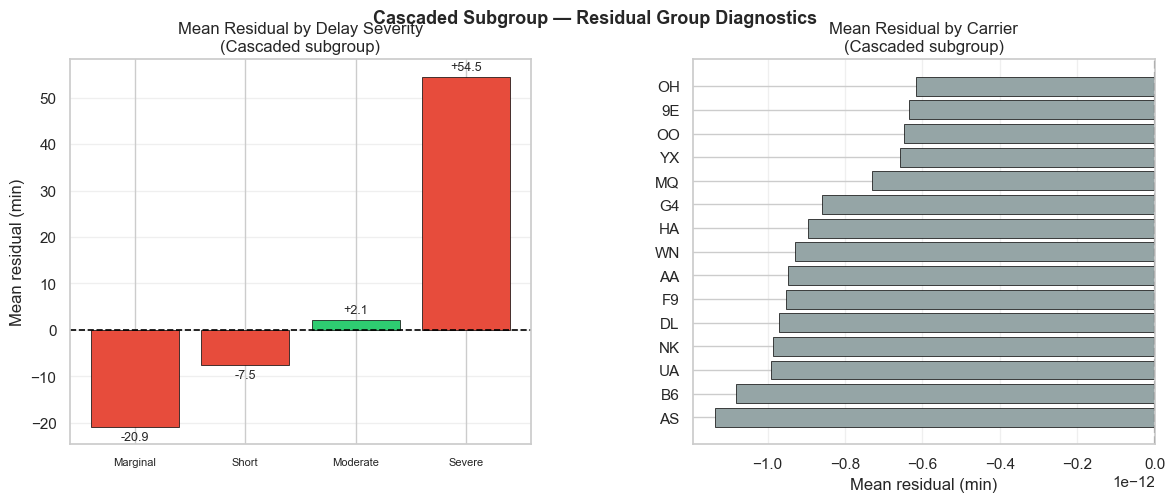

Jarque-Bera  : stat=620,879,802  p=0.0000  -> NOT normal
Breusch-Pagan: stat=653.00  p=0.0000  -> Heteroscedastic


In [64]:
import io
from IPython.display import Image
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import jarque_bera

plt.close('all')
y_act_sub = y_sub.values

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

_bin_s  = pd.Series(pd.cut(y_act_sub,
              bins=[-500,-30,0,15,60,180,5000],
              labels=['Early','On-time','Marginal','Short','Moderate','Severe']))
_resid_s = pd.Series(res_sub)
mean_r   = _resid_s.groupby(_bin_s).mean()
n_r      = _resid_s.groupby(_bin_s).count()
colors   = ['#2ecc71' if abs(v)<5 else '#e74c3c' for v in mean_r]
axes[0].bar(range(len(mean_r)), mean_r.values, color=colors, edgecolor='black', linewidth=0.5)
axes[0].axhline(0, color='black', lw=1.2, linestyle='--')
axes[0].set_xticks(range(len(mean_r)))
axes[0].set_xticklabels(mean_r.index.astype(str), fontsize=8)
for i, (v, n) in enumerate(zip(mean_r.values, n_r.values)):
    axes[0].text(i, v+(1.5 if v>=0 else -3), f'{v:+.1f}', ha='center', fontsize=9)
axes[0].set_ylabel('Mean residual (min)')
axes[0].set_title('Mean Residual by Delay Severity\n(Cascaded subgroup)')
axes[0].grid(axis='y', alpha=0.3)

resid_sub_s = pd.Series(res_sub, index=reg_sub.index)
carrier_sub = (reg_sub[['op_unique_carrier']]
               .assign(resid=resid_sub_s)
               .groupby('op_unique_carrier')['resid']
               .agg(['mean','count'])
               .sort_values('mean', ascending=False))
colors_c = ['#e74c3c' if v>2 else '#2ecc71' if v<-2 else '#95a5a6' for v in carrier_sub['mean']]
axes[1].barh(carrier_sub.index, carrier_sub['mean'], color=colors_c, edgecolor='black', linewidth=0.5)
axes[1].axvline(0, color='black', lw=1.5, linestyle='--')
axes[1].set_xlabel('Mean residual (min)')
axes[1].set_title('Mean Residual by Carrier\n(Cascaded subgroup)')
axes[1].invert_yaxis(); axes[1].grid(axis='x', alpha=0.3)

fig.suptitle('Cascaded Subgroup — Residual Group Diagnostics', fontsize=13, fontweight='bold')
fig.subplots_adjust(wspace=0.35)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

jb_stat, jb_p = jarque_bera(res_sub)
bp_lm, bp_p, _, _ = het_breuschpagan(res_sub, model_sub.model.exog)
print(f"Jarque-Bera  : stat={jb_stat:,.0f}  p={jb_p:.4f}  -> {'NOT normal' if jb_p<0.05 else 'Normal'}")
print(f"Breusch-Pagan: stat={bp_lm:.2f}  p={bp_p:.4f}  -> {'Heteroscedastic' if bp_p<0.05 else 'Homoscedastic'}")


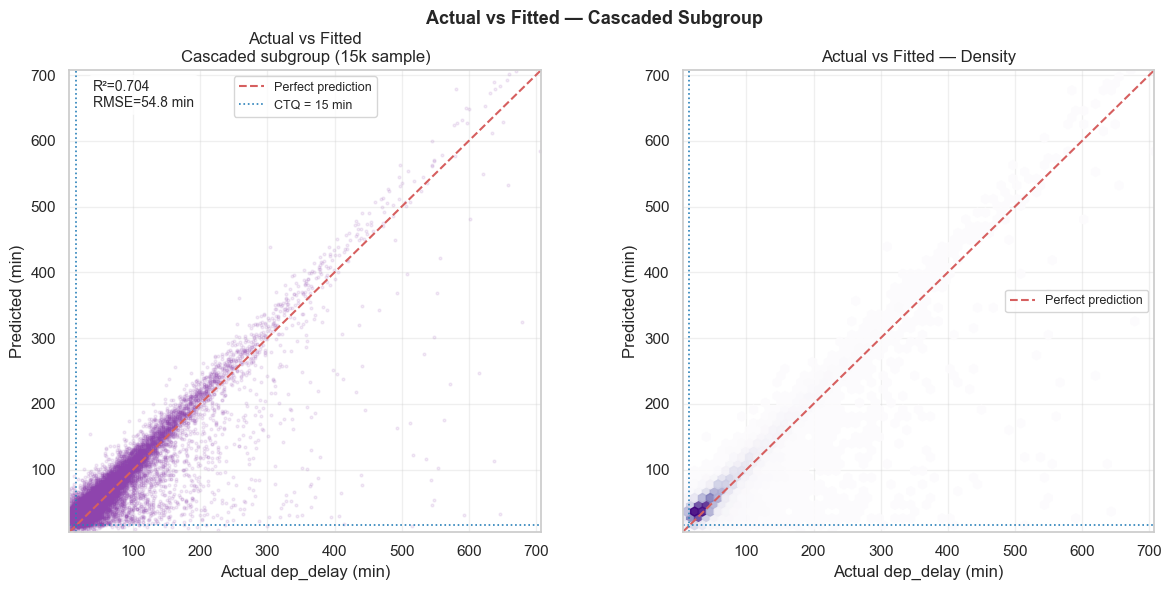

  Metric                   Full model   Cascaded subgroup
  --------------------------------------------------------
  R²                           0.4874              0.7044
  RMSE (min)                    39.08               54.80
  MAE (min)                     13.81               20.81


In [65]:
import io
from IPython.display import Image

plt.close('all')

fit_sub   = model_sub.fittedvalues.values
res_sub   = model_sub.resid.values
y_act_sub = y_sub.values
samp      = np.random.choice(len(fit_sub), min(15_000, len(fit_sub)), replace=False)
lo        = float(np.percentile(y_act_sub, 0.5))
hi        = float(np.percentile(y_act_sub, 99.5))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=100)

axes[0].scatter(y_act_sub[samp], fit_sub[samp], alpha=0.10, s=4, color='#8e44ad')
axes[0].plot([lo, hi], [lo, hi], 'r--', lw=1.5, label='Perfect prediction')
axes[0].axhline(15, color='#2980b9', lw=1.2, linestyle=':')
axes[0].axvline(15, color='#2980b9', lw=1.2, linestyle=':', label='CTQ = 15 min')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
axes[0].set_xlabel('Actual dep_delay (min)'); axes[0].set_ylabel('Predicted (min)')
axes[0].set_title('Actual vs Fitted\nCascaded subgroup (15k sample)')
rmse_s = np.sqrt((res_sub**2).mean())
axes[0].text(0.05, 0.92, f"R²={model_sub.rsquared:.3f}\nRMSE={rmse_s:.1f} min",
             transform=axes[0].transAxes, fontsize=10,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

axes[1].hexbin(y_act_sub[samp], fit_sub[samp],
               gridsize=60, cmap='Purples', mincnt=1,
               extent=[lo, hi, lo, hi], alpha=0.9)
axes[1].plot([lo, hi], [lo, hi], 'r--', lw=1.5, label='Perfect prediction')
axes[1].axhline(15, color='#2980b9', lw=1.2, linestyle=':')
axes[1].axvline(15, color='#2980b9', lw=1.2, linestyle=':')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi)
axes[1].set_xlabel('Actual dep_delay (min)'); axes[1].set_ylabel('Predicted (min)')
axes[1].set_title('Actual vs Fitted — Density')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

fig.suptitle('Actual vs Fitted — Cascaded Subgroup', fontsize=13, fontweight='bold')
fig.subplots_adjust(wspace=0.30)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100, bbox_inches='tight'); plt.close(fig)
buf.seek(0); display(Image(buf.read()))

print(f"  {'Metric':<20} {'Full model':>14}  {'Cascaded subgroup':>18}")
print(f"  {'-'*56}")
print(f"  {'R²':<20} {model_final.rsquared:>14.4f}  {model_sub.rsquared:>18.4f}")
print(f"  {'RMSE (min)':<20} {np.sqrt(model_final.mse_resid):>14.2f}  {rmse_s:>18.2f}")
print(f"  {'MAE (min)':<20} {np.abs(model_final.resid.values).mean():>14.2f}  {np.abs(res_sub).mean():>18.2f}")
